# Portfolio Optimization Beyond Markowitz

DSE4212 / QF4212 group project 2. **Where does the estimation error go?**

We compare classical Markowitz and sample-covariance portfolios with portfolios built on RMT-denoised, PCA-factor and hierarchical (HRP) estimates, with Ledoit-Wolf shrinkage and 1/N as reference baselines. The test is a rolling-window, out-of-sample backtest on daily S&P 500 stock data.

This notebook is the narrative layer. All logic lives in `src/pfopt/`; the stage scripts in `scripts/` produce the tables and figures; the cells below load those results and recompute a few headline quantities from the cached backtest as a consistency check. The analysis runs in the order below:

| Topic | Section |
| --- | --- |
| Data preparation and EDA | 1 |
| Markowitz benchmark | 2 and 3 |
| Alternative approaches: regularized, risk-based, ML | 2 and 7 |
| Backtesting framework, no look-ahead | 4 |
| Performance metrics, weight stability, regimes | 5 and 6 |
| Comparison and analysis | 5 to 8 |

No result number is typed into the text. Every number comes from the code and the saved tables.

## How to reproduce

1. Install: `pip install -e . && pip install -r requirements.txt` (Python 3.11 or newer).
2. Put the three Kaggle files in `data/raw/`: `sp500_stocks.csv`, `sp500_companies.csv`, `sp500_index.csv`. Raw data is not part of the submission.
3. Run the stage scripts in the order given in `README.md`, then `python scripts/11_make_report_assets.py --config config.yaml`. The last script re-runs every stage and writes the report figures and tables to `results/report/`. With a warm cache the stages take a few minutes in total; the first run, which generates the weights, takes longer.
4. Run this notebook with *Restart & Run All*. It reads `results/report/`. Two kinds of cells need more and are skipped with a message when it is missing: cells that recompute from the processed data (`data/processed/`, from `scripts/01b_clean_data.py`) and cells that recompute from the cached backtest (`results/cache/`, from `scripts/02_run_backtest.py`).

All parameters are fixed a priori in `config.yaml`; nothing below was tuned on the test period.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from pfopt.backtest.metrics import performance_metrics
from pfopt.backtest.strategies import core_strategies
from pfopt.config import load_config
from pfopt.data.cleaning import read_processed
from pfopt.data.eda import get_window
from pfopt.data.universe import select_universe, snapshot_dates
from pfopt.estimators.utils import condition_number, mp_edges, winsorize_cols
from pfopt.viz.plots import plot_equity_curves

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yaml").exists())
cfg = load_config(ROOT / "config.yaml")
TABLES, PROC = ROOT / cfg.paths.tables_dir, ROOT / cfg.paths.processed_dir
CACHE = ROOT / cfg.paths.cache_dir / cfg.cache_key()
REPORT = ROOT / "results" / "report"
MANIFEST = pd.read_csv(REPORT / "manifest.csv").fillna("")
PROCESSED = ("log_returns", "simple_returns", "volume", "dollar_volume")
HAVE_DATA = all((PROC / f"{name}.parquet").exists() for name in PROCESSED)
HAVE_CACHE = all((CACHE / f"{name}.parquet").exists() for name in ("returns_net", "turnover"))
FOUND = {True: "found", False: "missing"}


def say(text):
    display(Markdown(text))


def _asset(kind, key):
    names = MANIFEST.loc[MANIFEST["kind"] == kind, "name"]
    hits = [n for n in names if n.split("_", 1)[1] == key]
    if len(hits) != 1:
        raise KeyError(f"{kind} {key!r}: {len(hits)} matches in manifest.csv")
    return hits[0]


def _title(name):
    caption = MANIFEST.loc[MANIFEST["name"] == name, "caption"].iloc[0]
    say(f"**{name}.** {caption}")


def show_figure(key, width=640):
    name = _asset("figure", key)
    _title(name)
    display(Image(filename=str(REPORT / "figures" / f"{name}.png"), width=width))


def show_table(key):
    name = _asset("table", key)
    _title(name)
    say((REPORT / "tables" / f"{name}.md").read_text(encoding="utf-8"))


say(
    f"Config hash `{cfg.config_hash()}`. Processed data {FOUND[HAVE_DATA]}, "
    f"cached backtest {FOUND[HAVE_CACHE]}."
)

Config hash `ffa190721ee6`. Processed data found, cached backtest found.

## 1. Data preparation and exploratory analysis

The only data source is the supplied Kaggle file of daily S&P 500 prices. Cleaning is code (`src/pfopt/data/cleaning.py`), never manual editing: symbols without prices are dropped and logged, short gaps are forward-filled up to a fixed limit, and prices that look like errors are flagged. Estimation uses **log returns**; portfolio P&L uses **simple returns**.

The supplied file prices only part of the listed symbols, and it holds only current index members. Two consequences carry through every result: the universe is a selection of the symbols that do have prices, and survivorship bias remains. Both are limitations, not features.

In [2]:
if HAVE_DATA:
    frames = read_processed(PROC)
    log_returns, dollar_volume = frames["log_returns"], frames["dollar_volume"]
    first, last = log_returns.index[[0, -1]]
    dropped = pd.read_csv(TABLES / "dropped_symbols.csv")
    say(
        f"{len(log_returns)} trading days ({first:%Y-%m-%d} to {last:%Y-%m-%d}), "
        f"{log_returns.shape[1]} symbols with prices after cleaning; "
        f"{len(dropped)} rows in `dropped_symbols.csv`."
    )
else:
    say("Processed data not found (run `scripts/01b_clean_data.py`); live data cells are skipped.")

3767 trading days (2010-01-05 to 2024-12-20), 172 symbols with prices after cleaning; 330 rows in `dropped_symbols.csv`.

Daily returns are fat-tailed, which is why the windows are winsorized per column before estimation. The eigenvalue spectrum of the correlation matrix has a few large eigenvalues (market and group factors) and a bulk that Random Matrix Theory (RMT) describes: for `N` assets and `T` observations the noise eigenvalues of a correlation matrix lie inside the Marchenko-Pastur (MP) band, whose upper edge is `(1 + sqrt(q))^2` with `q = N / T`. Eigenvalues above that edge are signal.

**figA01_return_hist.** Pooled return distribution.

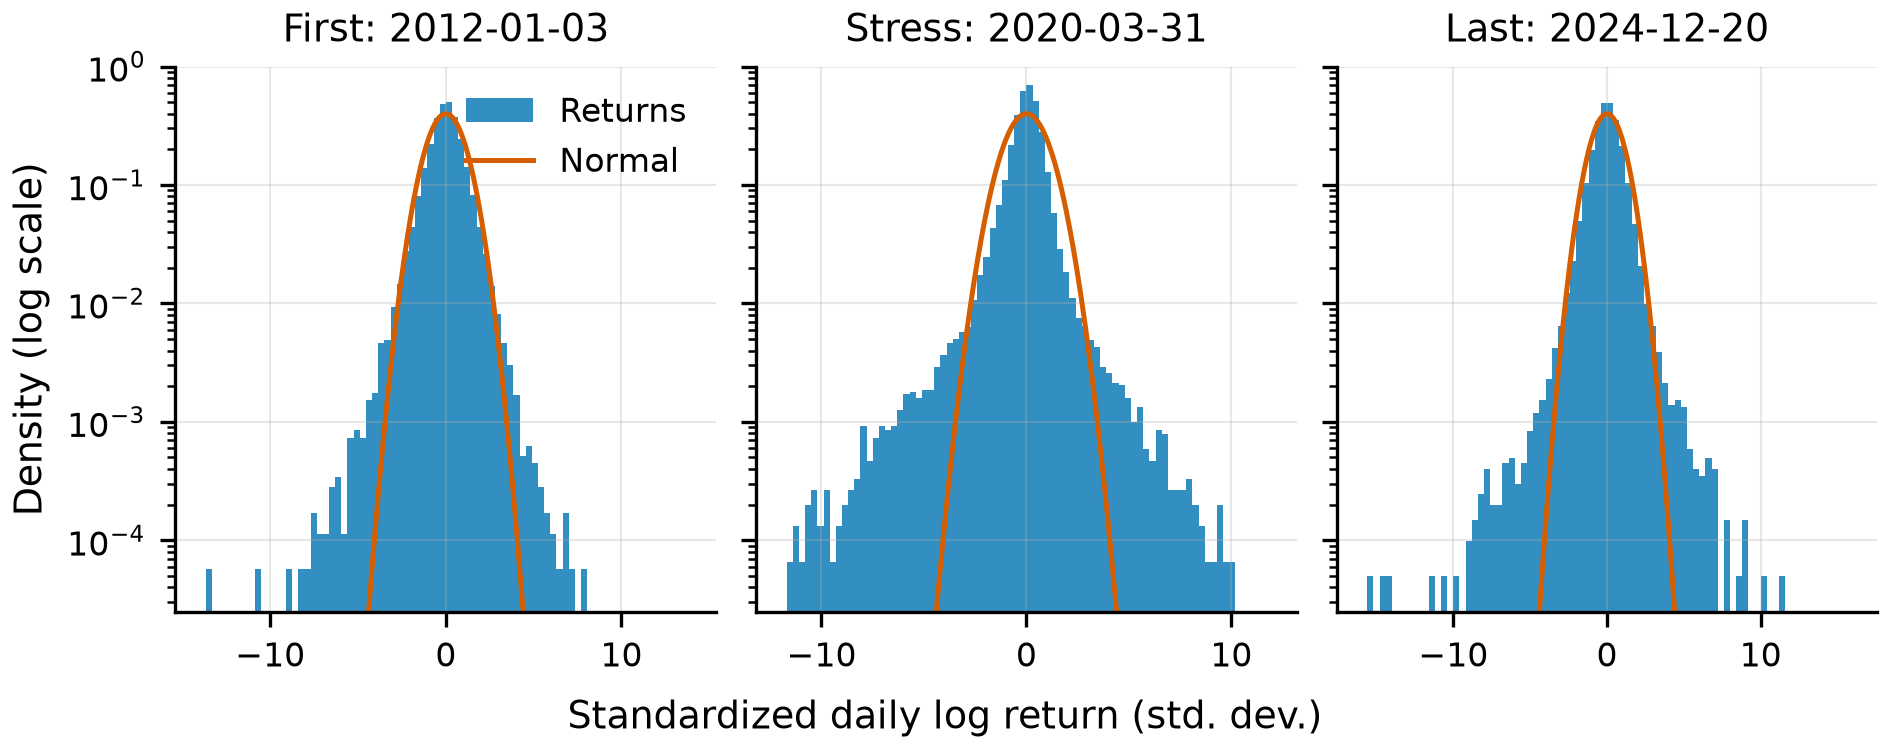

**fig01_mp_spectrum.** Eigenvalue spectrum against Marchenko-Pastur.

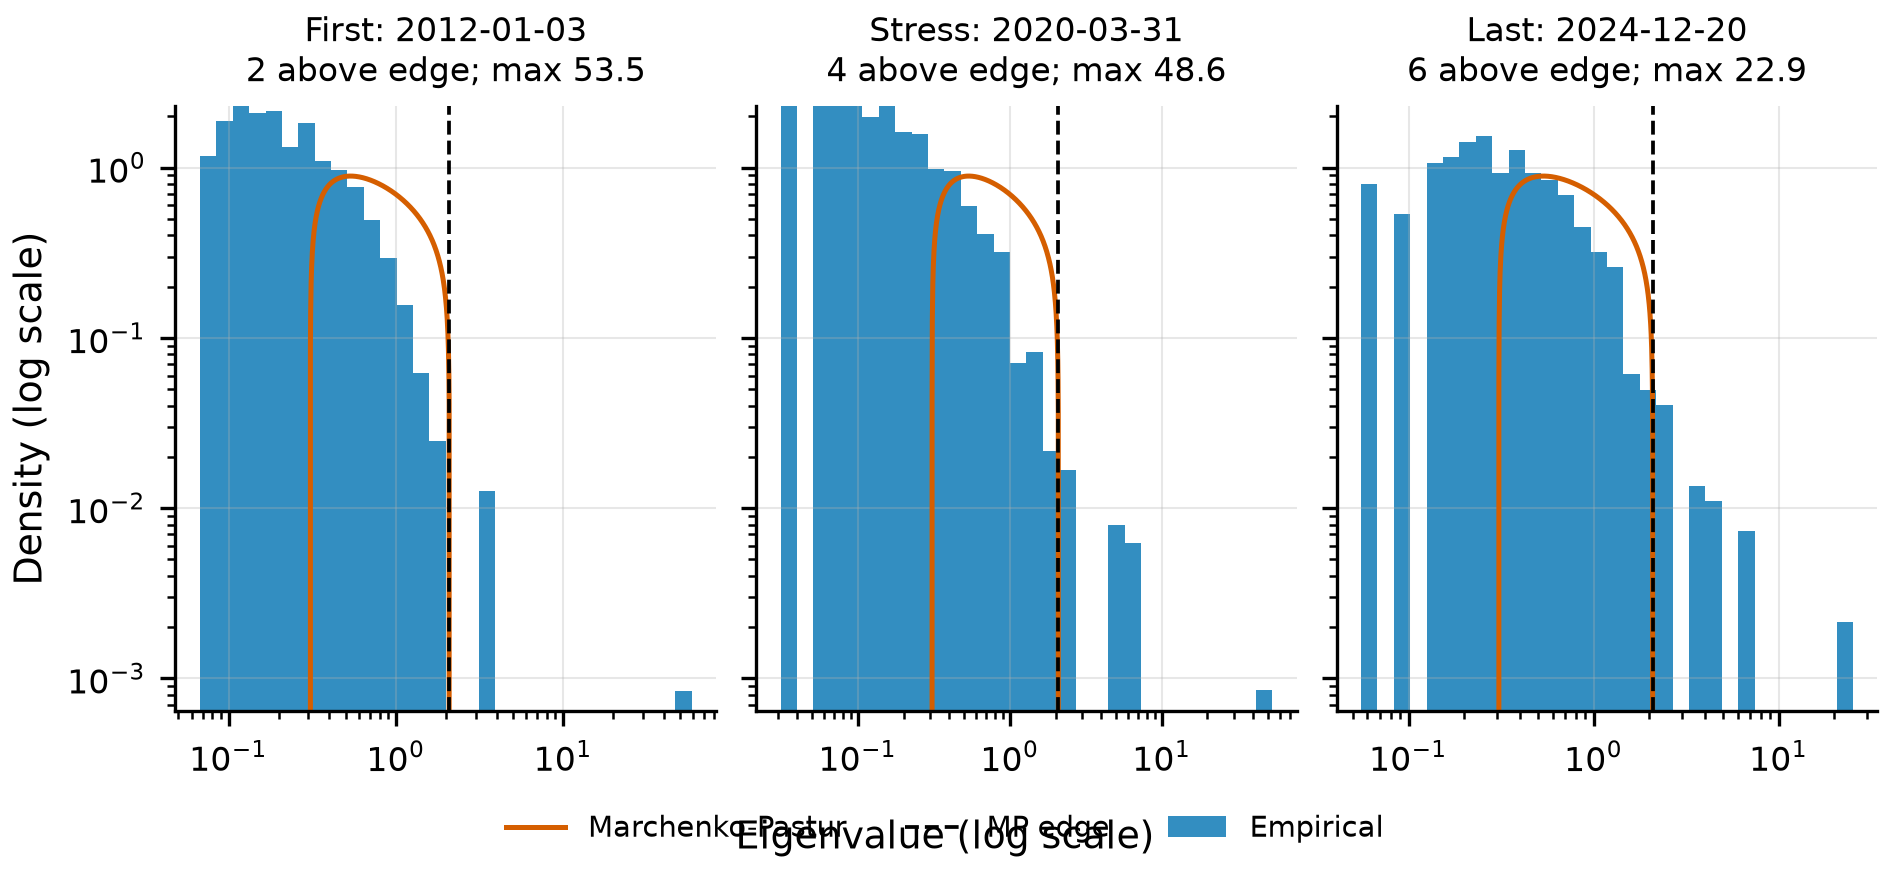

**fig02_corr_heatmap.** Clustered correlation matrices.

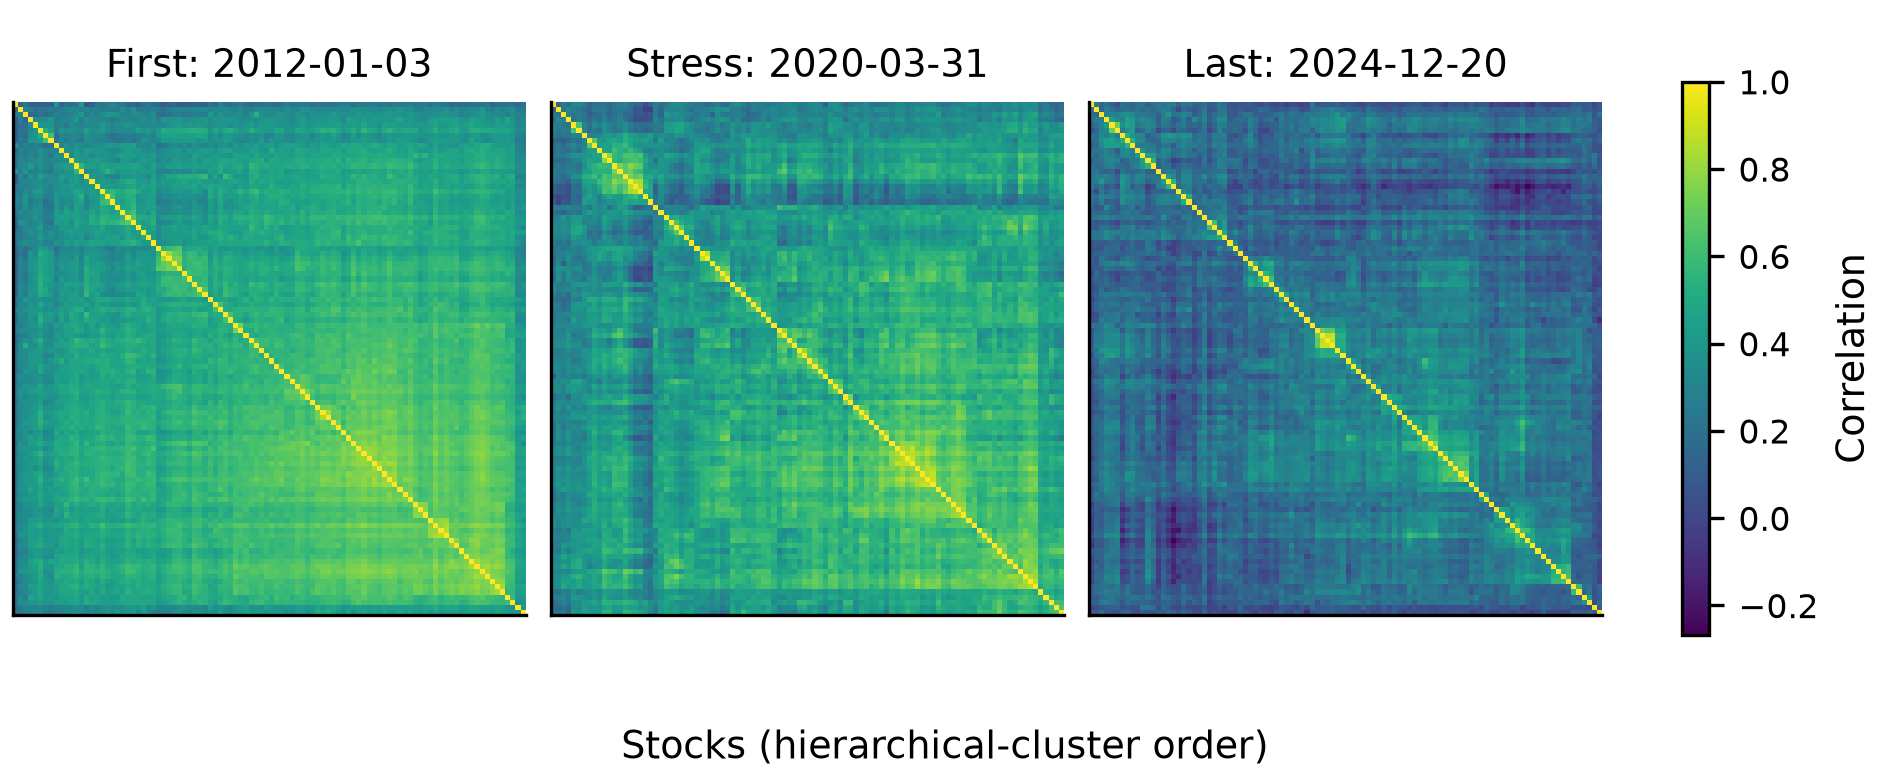

In [3]:
show_figure("return_hist")
show_figure("mp_spectrum")
show_figure("corr_heatmap")

The number of signal eigenvalues and the average correlation are not constant: they rise in stress periods. This matters later, because an estimator calibrated on a calm window is exposed when correlations jump.

**fig03_spectrum_time.** Signal eigenvalues over time.

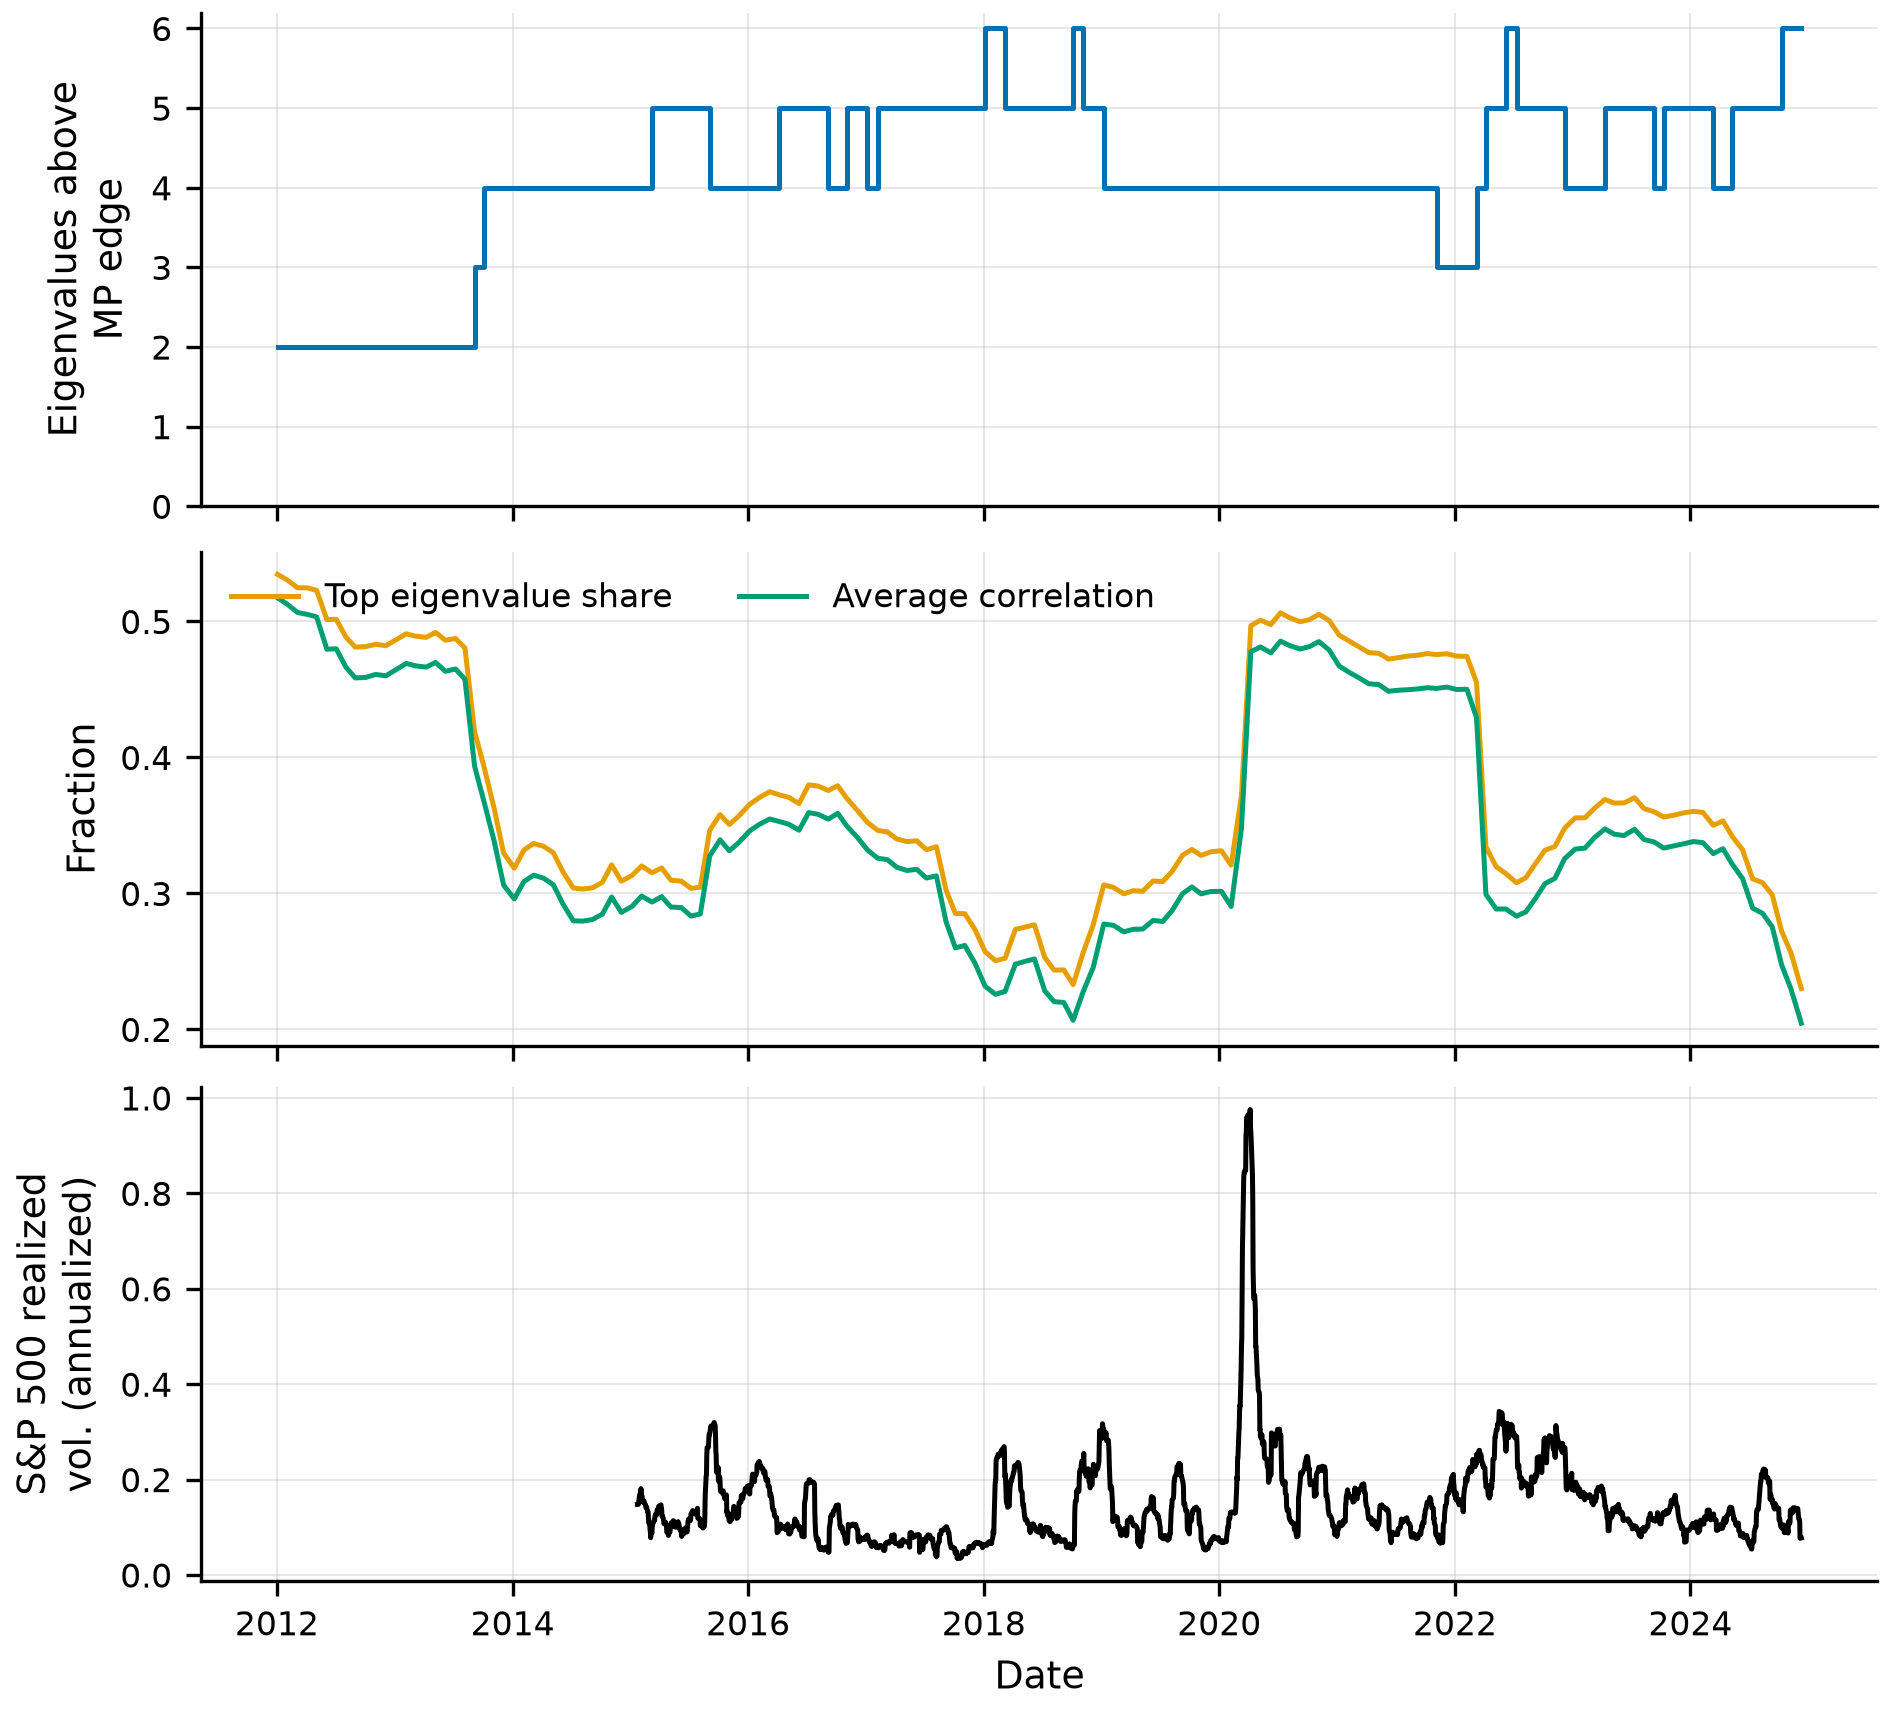

**figA02_rolling_corr.** Rolling average correlation.

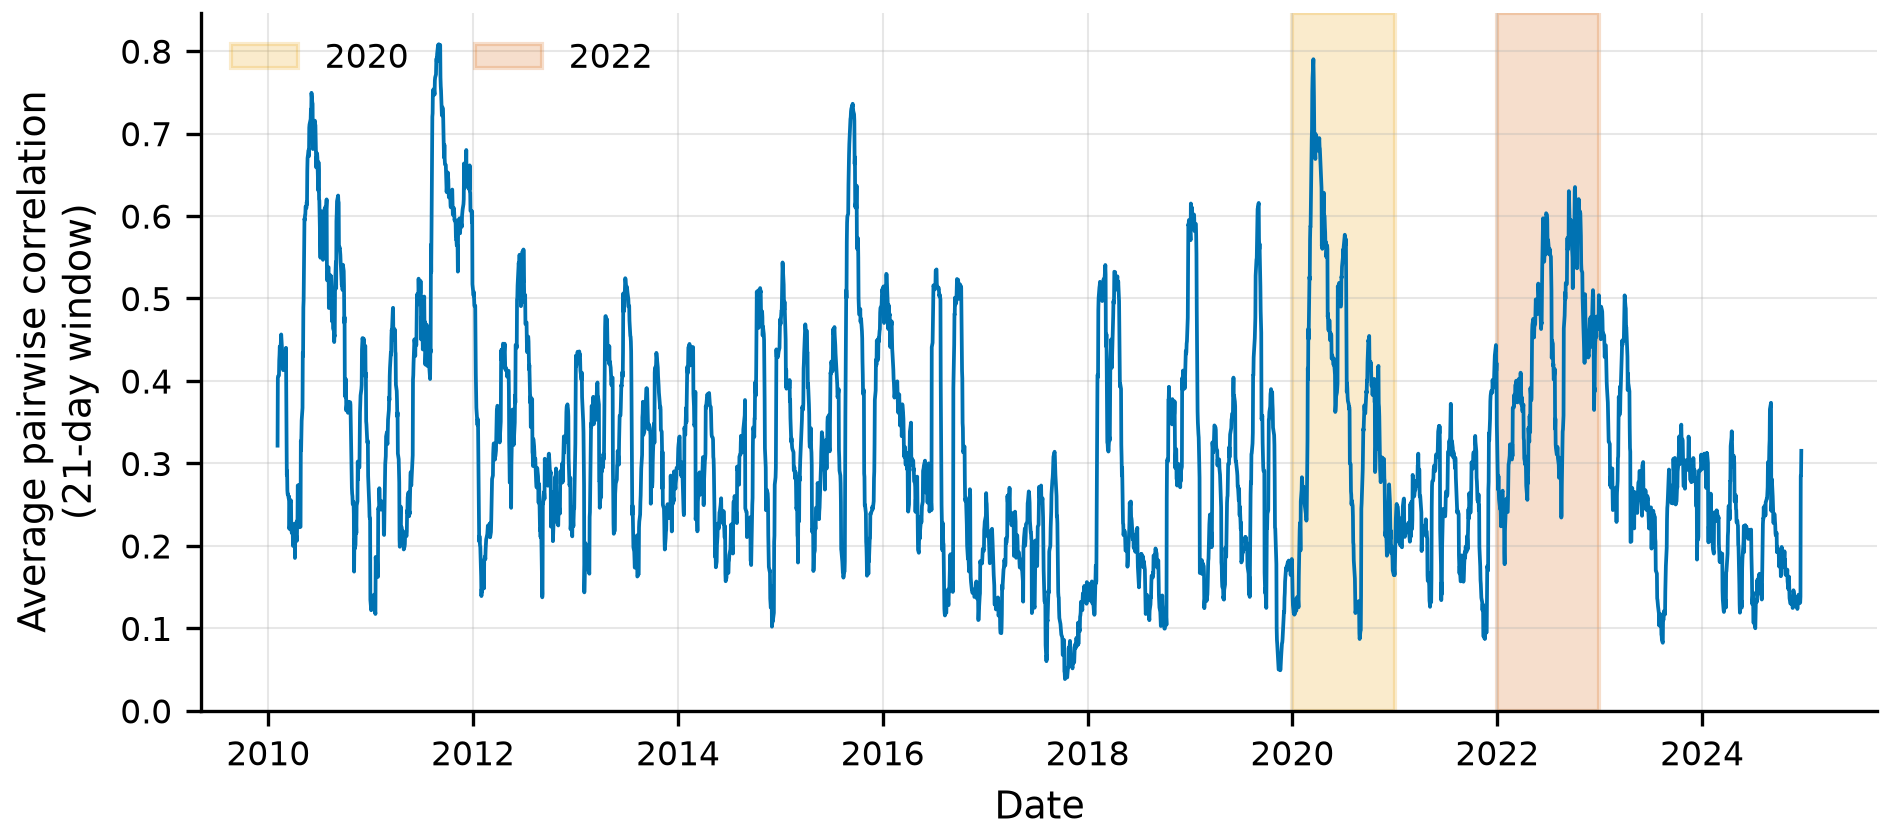

In [4]:
show_figure("spectrum_time")
show_figure("rolling_corr")

## 2. Estimators and strategies in action

| Method | Idea |
| --- | --- |
| Sample covariance | Plug-in estimate from the window; with `N` close to `T` its small eigenvalues are far too small. |
| Ledoit-Wolf | Convex combination of the sample covariance and a scaled identity, with a data-driven intensity. |
| RMT clipping | Keep correlation eigenvalues above the MP upper edge, replace the rest by their mean (trace preserved), rescale to a unit diagonal. |
| PCA factor | Top-`K` principal components (K from the MP rule) plus a diagonal residual. |
| HRP | Hierarchical clustering of the correlation matrix, then recursive bisection by cluster variance; no matrix inversion. |
| 1/N | Equal weight, no estimation. |

Global minimum-variance (GMV) portfolios use each covariance estimate; the Markowitz benchmark maximizes the Sharpe ratio with expected returns from the window. All are long-only and fully invested.

The next cells run these estimators on one point-in-time snapshot, with only data up to that date.

In [5]:
if HAVE_DATA:
    n, t, w = cfg.universe.n_assets, cfg.universe.lookback_days, cfg.universe.dollar_volume_window
    date = snapshot_dates(log_returns, t, n, cfg.eda.stress_date)["stress"]
    universe = select_universe(log_returns, dollar_volume, date, t, n, w)
    window = get_window(log_returns, date, t, universe)
    x = winsorize_cols(window.to_numpy(), cfg.data.winsor_lower, cfg.data.winsor_upper)
    result = core_strategies(x, cfg)
    lam_minus, lam_plus = mp_edges(n / t)
    n_signal, k = result.info["rmt_n_signal"], result.info["pca_K"]
    delta = result.info["lw_shrinkage"]
    say(
        f"Snapshot {date:%Y-%m-%d}: window {x.shape[0]} x {x.shape[1]}, q = N/T = {n / t:.2f}, "
        f"MP band [{lam_minus:.2f}, {lam_plus:.2f}]. RMT keeps {n_signal} signal eigenvalues, "
        f"PCA uses K = {k}, Ledoit-Wolf shrinkage intensity {delta:.3f}."
    )
    cond = pd.Series({k: condition_number(v) for k, v in result.covariances.items()})
    eff_n = pd.Series({k: 1.0 / float(np.sum(v**2)) for k, v in result.weights.items()})
    display(cond.rename("condition number").round(1).to_frame())
    display(eff_n.rename("effective number of names").round(1).to_frame())

Snapshot 2020-03-31: window 504 x 100, q = N/T = 0.20, MP band [0.31, 2.09]. RMT keeps 4 signal eigenvalues, PCA uses K = 4, Ledoit-Wolf shrinkage intensity 0.077.

,condition number
Sample,1676.7
Ledoit-Wolf,424.7
RMT,286.4
PCA,389.7


,effective number of names
EW,100.0
GMV-SAMPLE,7.2
GMV-LW,9.5
GMV-RMT,7.7
GMV-PCA,7.6
HRP,79.5
HRP-RMT,83.3


The condition number shows how much each estimator tames the smallest eigenvalues; the effective number of names `1 / sum(w^2)` shows how concentrated the resulting weights are. The saved figures compare the full spectra and weights at three dates.

**figA03_cov_spectra.** Covariance estimator spectra.

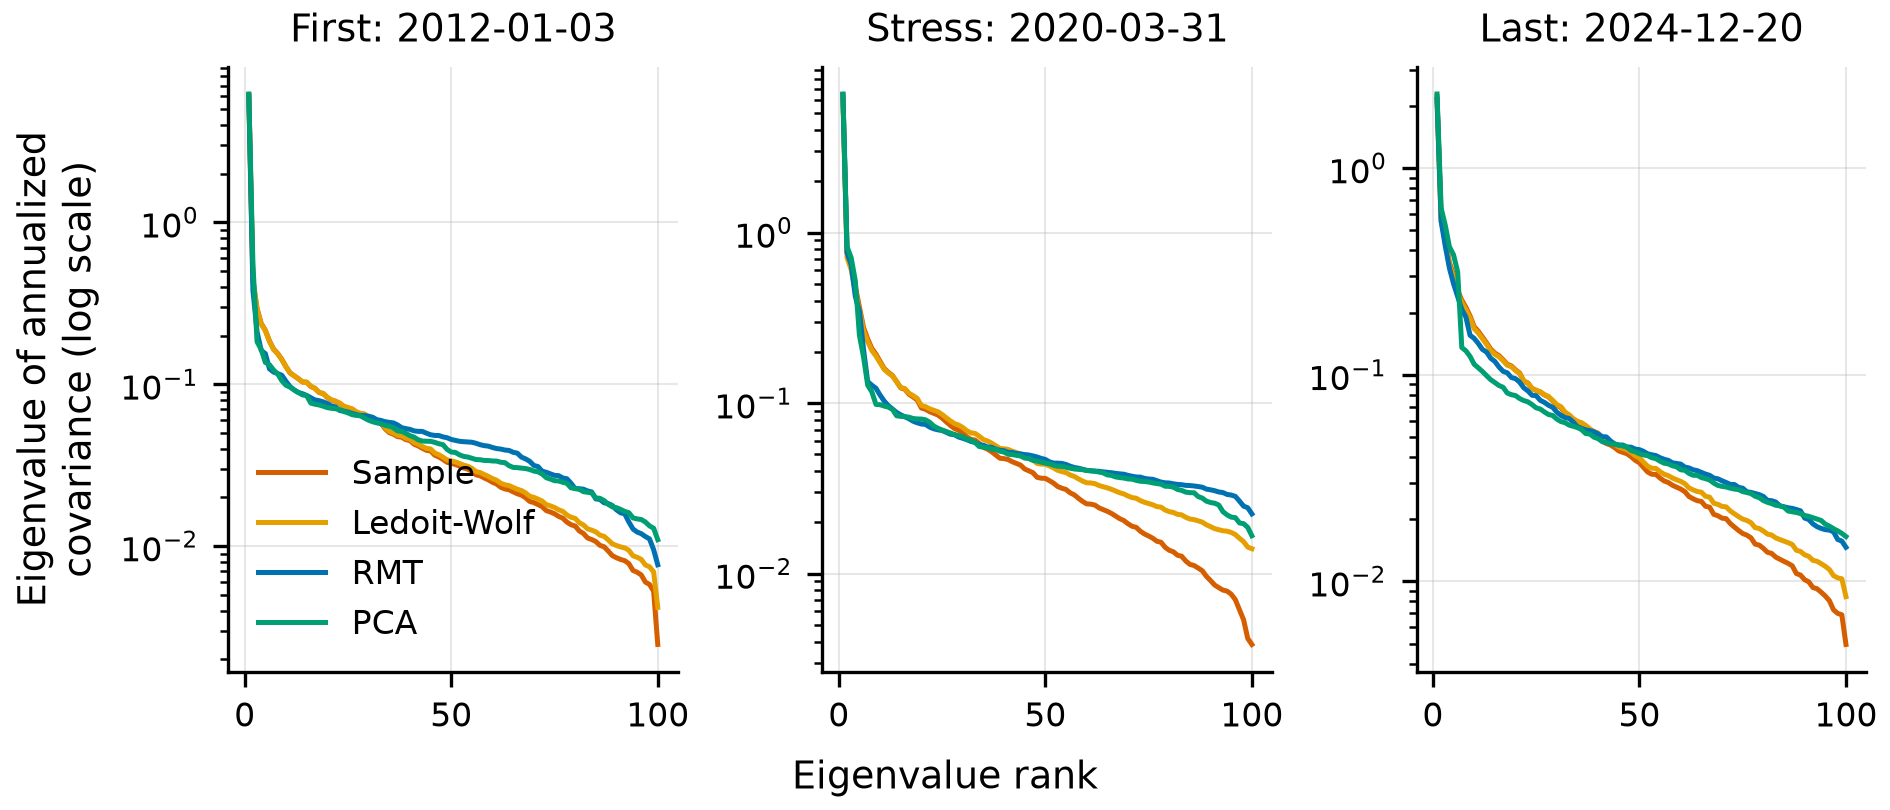

**figA04_sorted_weights.** Sorted weights at one date.

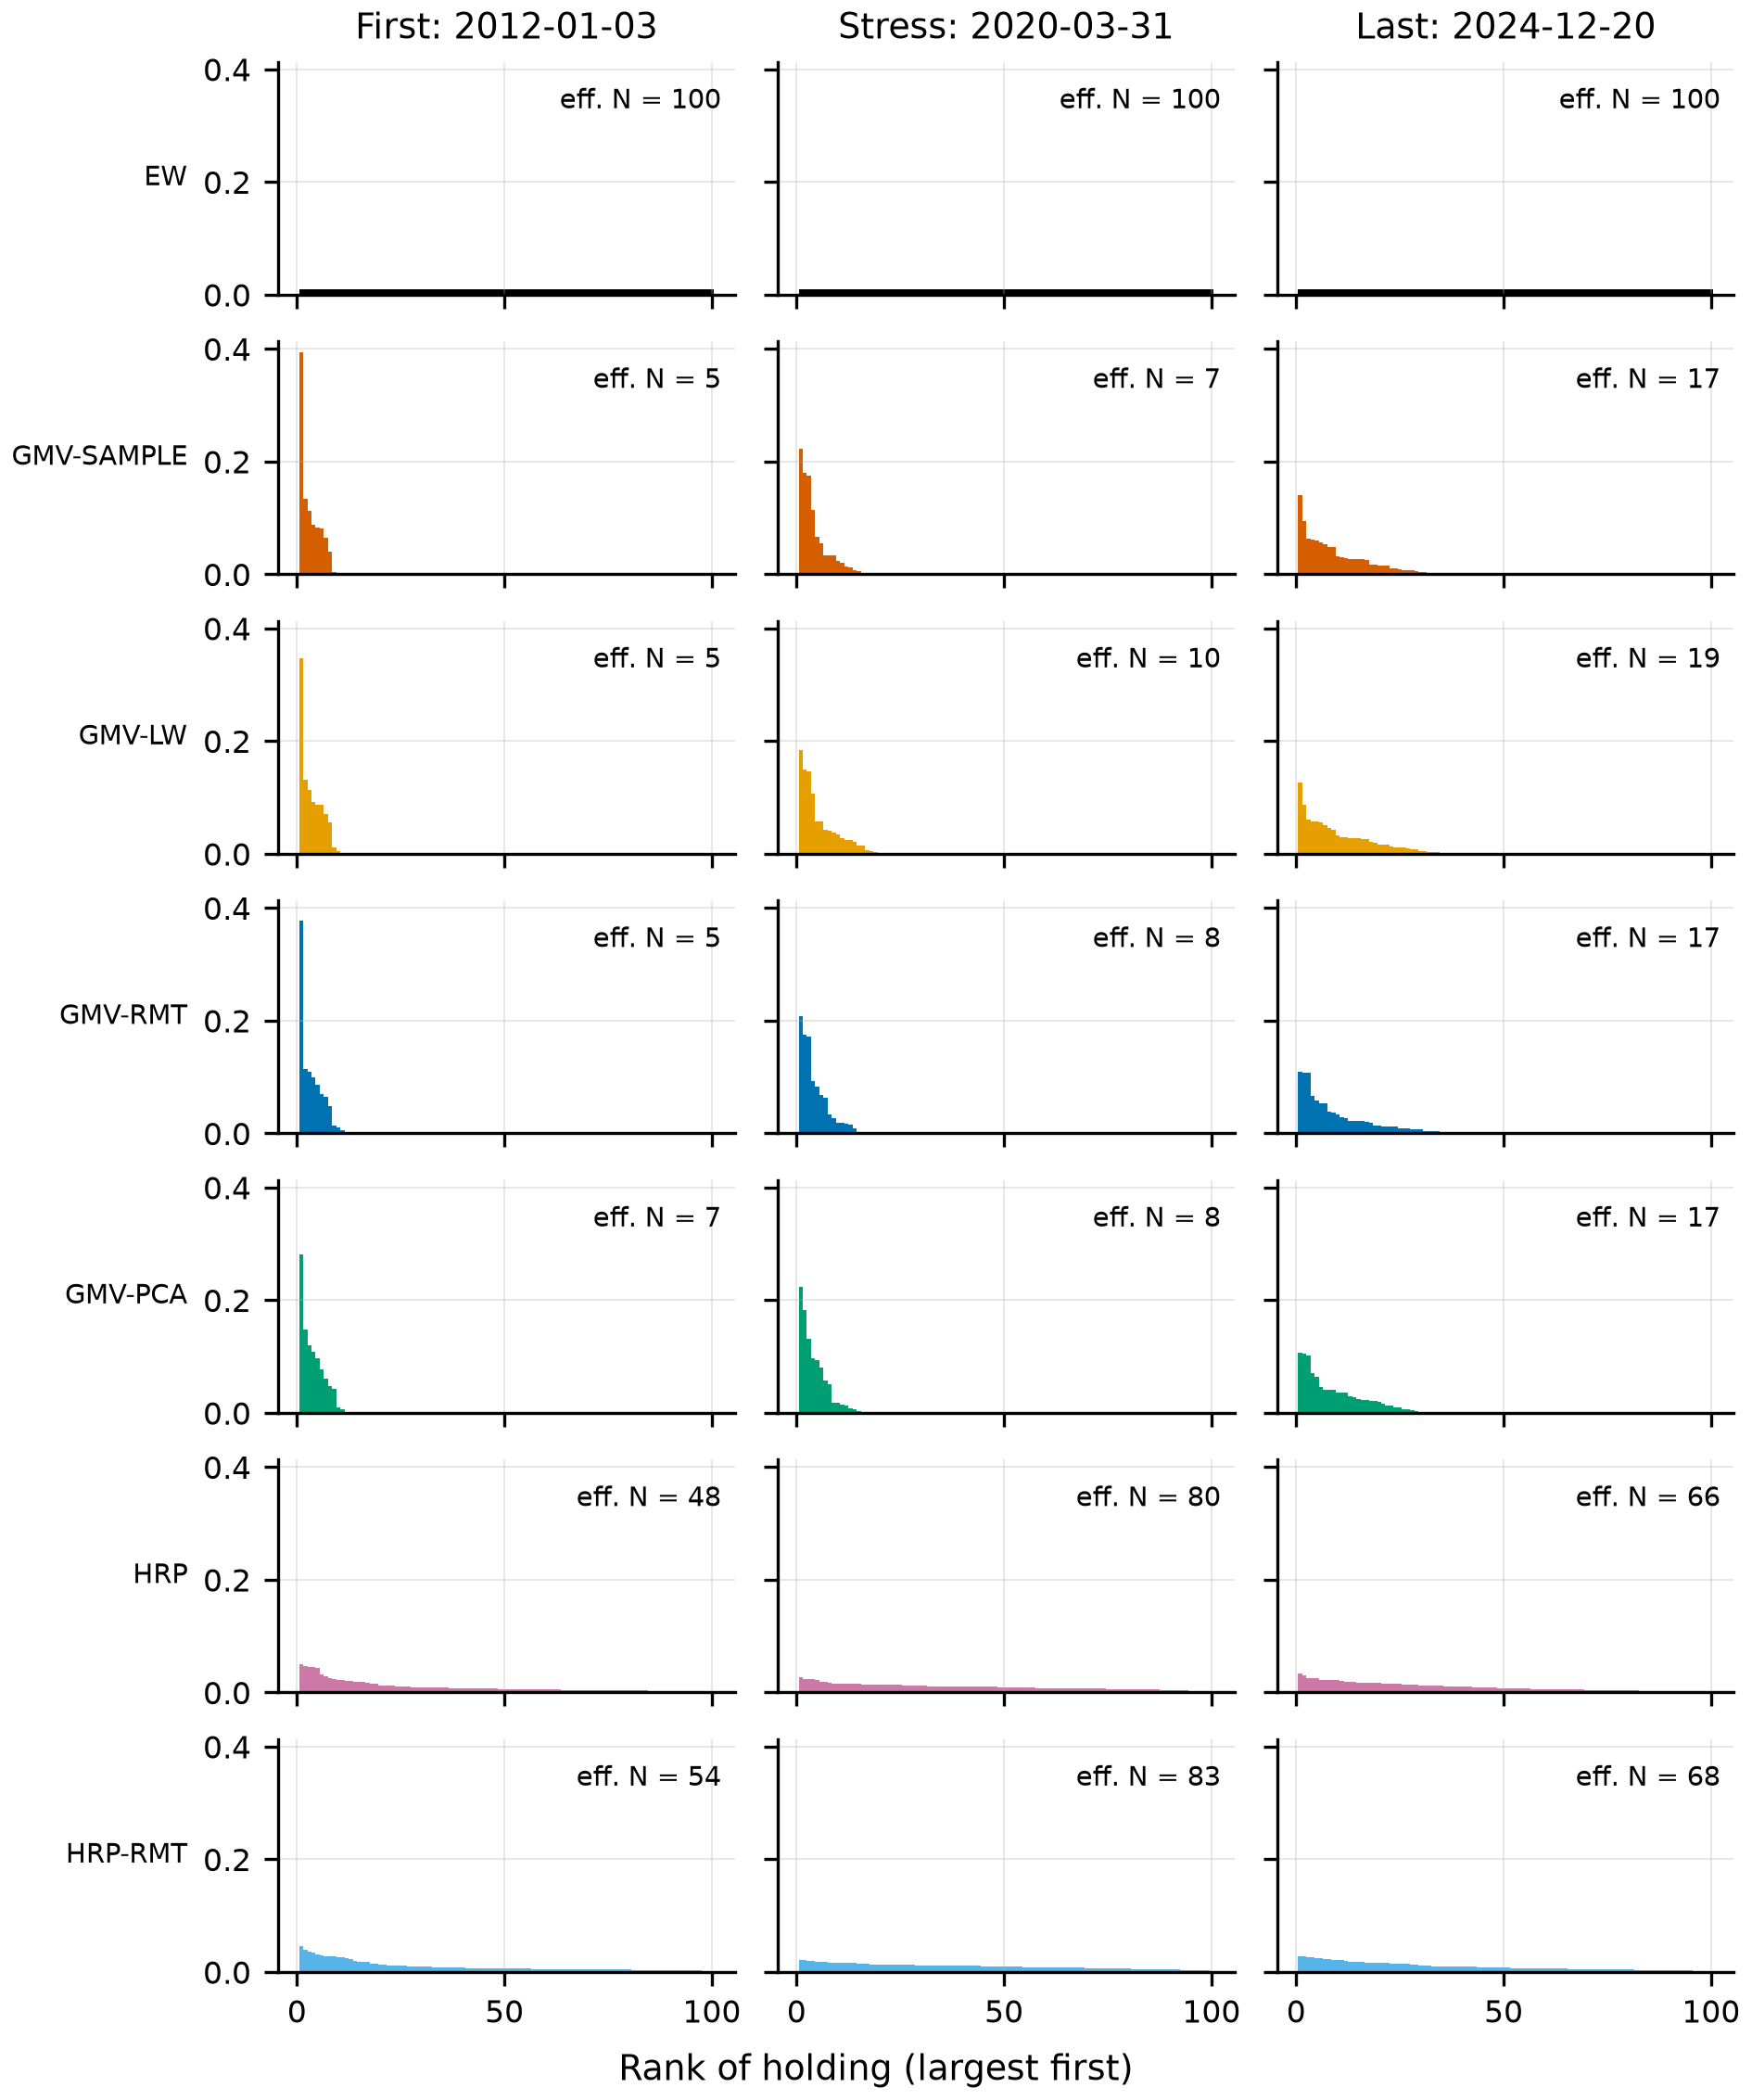

In [6]:
show_figure("cov_spectra")
show_figure("sorted_weights")

## 3. The Markowitz benchmark and the efficient frontier

Plug-in Markowitz treats estimates as truth. The frontier below is estimated in one window and then evaluated on the following period: the gap between the estimated and the realized frontier is the estimation error that the rest of the project tries to reduce.

**fig04_frontier.** Estimated against realized efficient frontier.

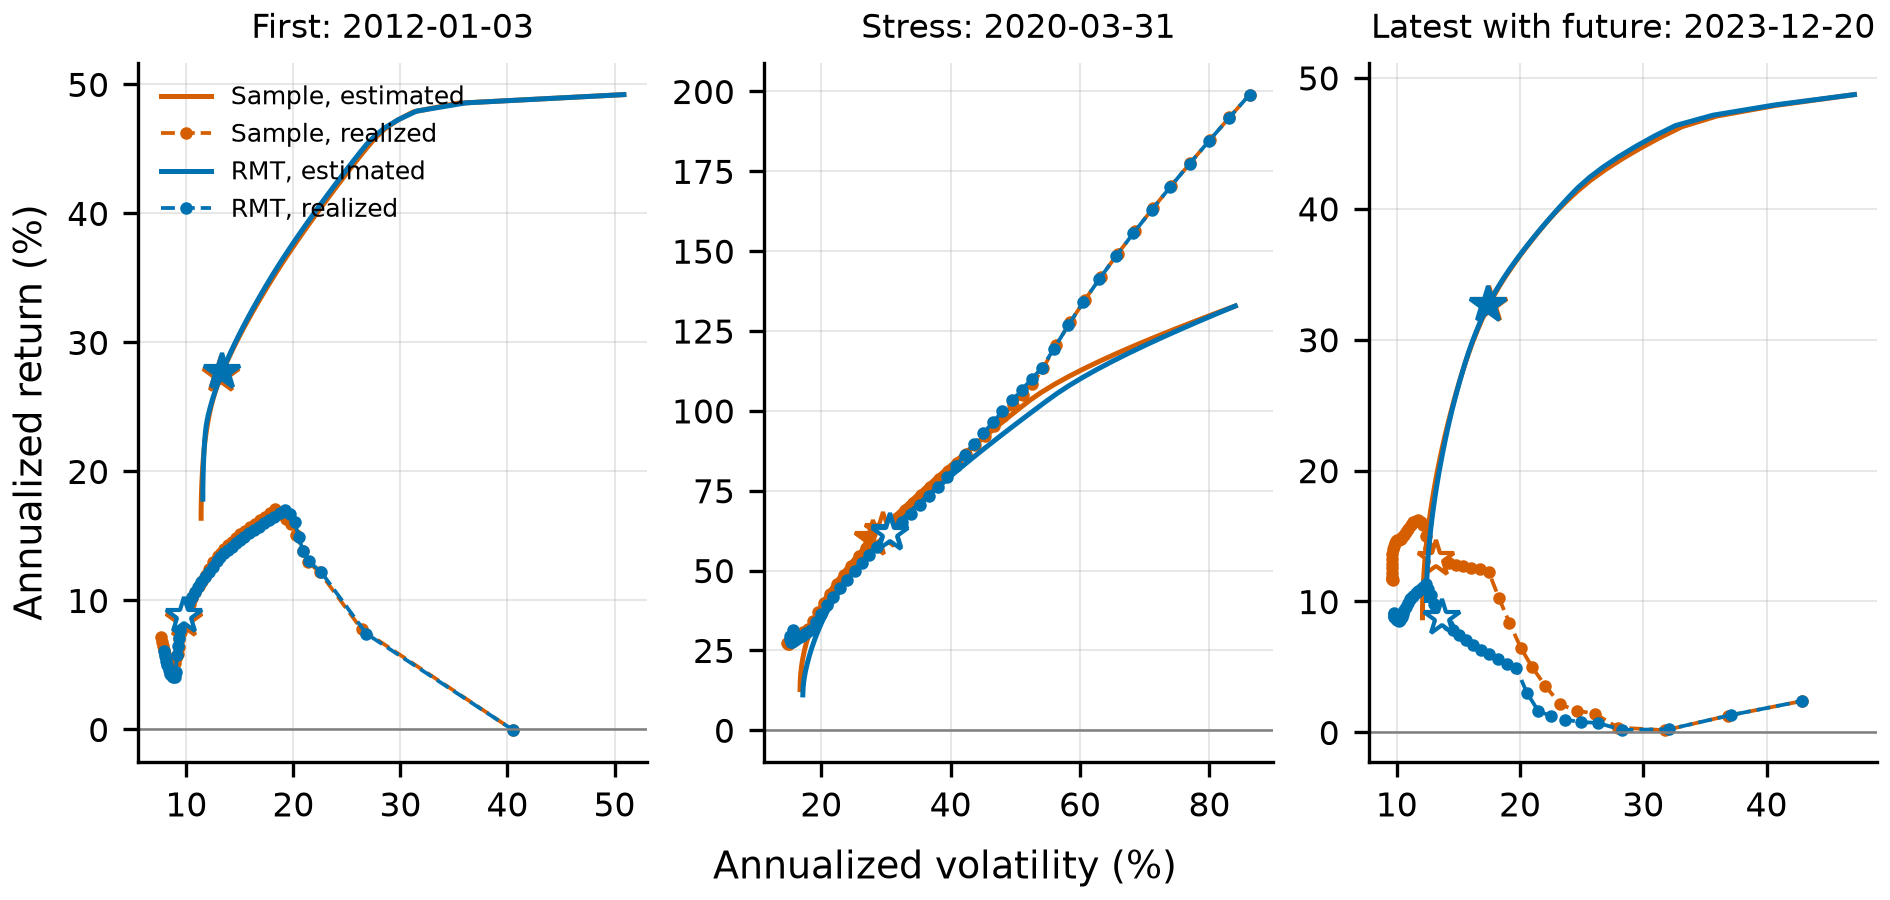

In [7]:
show_figure("frontier")

## 4. Backtesting framework

At each rebalance date `t` the weights use only data dated `t` or earlier: the point-in-time universe, the estimation window, the winsorization and the estimates. They are applied to returns from `t + 1` onward, drift between rebalances, and pay proportional costs on turnover. Every strategy faces the same universe, dates, constraints and cost model.

The test suite checks this directly (perturbing future data must not change past weights, accounting on toy data). A separate check additionally runs the whole pipeline on synthetic panels where the answer is known.

In [8]:
bt, u = cfg.backtest, cfg.universe
say(
    f"Universe: top {u.n_assets} names by trailing {u.dollar_volume_window}-day dollar volume "
    f"among names with a complete {u.lookback_days}-day window. Rebalance every "
    f"{bt.rebalance_days} trading days; transaction cost {bt.cost_bps:g} bps per unit of "
    f"turnover; weight cap {bt.max_weight}; expected-return convention `{bt.mu_convention}`; "
    f"seed {cfg.run.seed}."
)
show_table("parameters")

Universe: top 100 names by trailing 252-day dollar volume among names with a complete 504-day window. Rebalance every 21 trading days; transaction cost 10 bps per unit of turnover; weight cap None; expected-return convention `arithmetic`; seed 42.

**tab08_parameters.** Fixed a priori parameters.

| section | parameter | value |
| --- | --- | --- |
| run | seed | 42 |
| run | annualization | 252 |
| run | rf | 0.0 |
| data | start_date | 2010-01-04 |
| data | end_date | 2024-12-20 |
| data | ffill_limit | 3 |
| data | max_missing_frac | 0.05 |
| data | suspect_abs_logret | 0.4 |
| data | winsor_lower | 0.001 |
| data | winsor_upper | 0.999 |
| eda | stress_date | 2020-03-31 |
| eda | corr_window_days | 21 |
| eda | index_vol_window_days | 21 |
| eda | highlight_years | [2020, 2022] |
| eda | frontier_horizon_days | 252 |
| eda | frontier_points | 50 |
| stats | block_length | 10 |
| stats | n_boot | 5000 |
| stats | sensitivity_block_lengths | [5, 10, 20] |
| stats | references | [GMV-SAMPLE, EW, GMV-LW] |
| stats | alpha | 0.05 |
| stats | mde_power | 0.8 |
| regimes | covid_start | 2020-02-19 |
| regimes | covid_end | 2020-12-31 |
| regimes | stress_year | 2022 |
| regimes | vol_window_days | 63 |
| regimes | min_history_days | 252 |
| universe | n_assets | 100 |
| universe | lookback_days | 504 |
| universe | dollar_volume_window | 252 |
| backtest | rebalance_days | 21 |
| backtest | cost_bps | 10.0 |
| backtest | max_weight | none |
| backtest | mu_convention | arithmetic |
| pca | k_rule | mp |
| pca | k_fixed | none |
| pca | baing_kmax | 10 |
| hrp | linkage | single |
| sensitivity | n_assets | [50, 100, 200] |
| sensitivity | lookback_days | [252, 504, 756] |
| sensitivity | cost_bps | [0.0, 5.0, 10.0, 20.0] |
| sensitivity | max_weight | [0.1] |
| sensitivity | pca_k_fixed | [1, 3, 5, 10] |
| sensitivity | hrp_linkage | [single, ward, average] |
| simulation | n_assets | 100 |
| simulation | n_groups | 2 |
| simulation | sample_sizes | [126, 252, 504, 1000] |
| simulation | n_reps | 200 |
| simulation | distributions | [gaussian, student_t] |
| simulation | t_df | 5.0 |
| simulation | market_vol | 0.15 |
| simulation | group_vols | [0.08, 0.06] |
| simulation | loading_low | 0.5 |
| simulation | loading_high | 1.5 |
| simulation | idio_vol_low | 0.15 |
| simulation | idio_vol_high | 0.45 |
| simulation | alpha | 0.05 |
| simulation | time_varying | False |
| simulation | horizon_days | 21 |
| simulation | vol_log_sd | 0.4 |
| simulation | vol_persistence | 0.98 |
| simulation | loading_drift_sd | 0.2 |
| simulation | loading_persistence | 0.996 |
| pipeline_check | n_symbols | 150 |
| pipeline_check | n_days | 2500 |
| pipeline_check | n_panels | 4 |
| pipeline_check | dv_persistence | 0.995 |
| pipeline_check | dv_sd | 1.0 |
| pipeline_check | z2_tolerance | 3.0 |
| pipeline_check | identity_tolerance | 1e-06 |
| nonstationarity | halflives | [126, 63] |
| nonstationarity | calibration_block_days | 21 |
| nonstationarity | sim_sample_sizes | [252, 504] |
| nonstationarity | sim_n_reps | 100 |
| residual | n_perm | 200 |
| residual | sim_n_groups | 10 |
| residual | sim_group_vol | 0.08 |
| residual | sim_label_error | 0.2 |
| residual | sim_sample_sizes | [252, 504] |
| residual | sim_n_reps | 100 |
| residual | n_placebo | 20 |
| forecast | n_portfolios | 500 |
| forecast | dirichlet_alphas | [1.0, 0.1] |
| forecast | hac_lag | 3 |
| regularized | ridge_lambdas | [0.1, 1.0, 10.0] |
| regularized | shrink_gammas | [0.25, 0.5, 0.75] |
| regularized | l1_bounds | [1.25, 1.5, 2.0] |
| regularized | enet_bound | 1.5 |
| regularized | enet_lambda | 1.0 |
| ml | momentum_days | 252 |
| ml | skip_days | 21 |
| ml | reversal_days | 21 |
| ml | vol_days | 63 |
| ml | horizon_days | 21 |
| ml | purge_days | 21 |
| ml | min_train_dates | 24 |
| ml | retrain_every | 6 |
| ml | ridge_alpha | 0.1 |
| ml | rf_trees | 200 |
| ml | rf_max_depth | 4 |
| ml | rf_min_leaf | 50 |
| ml | rf_max_features | 0.5 |
| ml | ic_gate_t | 2.0 |
| ml | force_portfolio | True |


In [9]:
show_table("pipeline_accounting")
show_table("pipeline_identity")
show_table("pipeline_estimation")

**tabA06_pipeline_accounting.** Extension: accounting check of the backtest on synthetic panels.

| strategy | n_panels | mean_z2 | se | z | passes | realized_over_true | realized_over_predicted |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EW | 4 | 0.983 | 0.016 | -1.088 | yes | 0.991 |  |
| GMV-SAMPLE | 4 | 0.989 | 0.016 | -0.710 | yes | 0.995 | 1.057 |
| GMV-LW | 4 | 0.988 | 0.016 | -0.772 | yes | 0.994 | 1.066 |
| GMV-RMT | 4 | 0.990 | 0.016 | -0.636 | yes | 0.996 | 1.032 |
| GMV-PCA | 4 | 0.989 | 0.016 | -0.697 | yes | 0.995 | 1.050 |
| HRP | 4 | 0.983 | 0.016 | -1.066 | yes | 0.992 | 1.012 |


**tabA07_pipeline_identity.** Extension: backtest engine against the direct evaluation.

| strategy | max_abs_diff | passes |
| --- | --- | --- |
| EW | 8.9e-16 | yes |
| GMV-SAMPLE | 6.7e-16 | yes |
| GMV-LW | 6.7e-16 | yes |
| GMV-RMT | 4.4e-16 | yes |
| GMV-PCA | 6.7e-16 | yes |
| HRP | 8.9e-16 | yes |


**tabA08_pipeline_estimation.** Extension: estimator ranking of the engine on synthetic panels.

| strategy | mean_log_ratio | se | ci_low | ci_high | n_panels | mean_var_ratio | mean_l1_dist |
| --- | --- | --- | --- | --- | --- | --- | --- |
| EW | 0.596 | 0.020 | 0.533 | 0.659 | 4 | 1.919 | 1.499 |
| GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 4 | 1.057 | 0.439 |
| GMV-LW | 4.0e-04 | 7.6e-04 | -0.002 | 0.003 | 4 | 1.057 | 0.438 |
| GMV-RMT | -0.005 | 0.003 | -0.013 | 0.003 | 4 | 1.051 | 0.447 |
| GMV-PCA | -0.012 | 3.4e-04 | -0.013 | -0.010 | 4 | 1.044 | 0.392 |
| HRP | 0.390 | 0.011 | 0.354 | 0.426 | 4 | 1.562 | 1.194 |


## 5. Out-of-sample performance

First a consistency check: the headline metrics are recomputed here from the cached daily net returns and compared with the table that the report uses.

Largest difference to `main_metrics.csv` (net): 1.1e-16.

,ann_return,ann_vol,sharpe,max_drawdown,sortino,annual_turnover
EW,0.170,0.174,0.993,-0.376,1.401,0.869
GMV-LW,0.094,0.130,0.758,-0.335,1.066,2.262
GMV-PCA,0.092,0.135,0.721,-0.343,1.013,2.175
GMV-RMT,0.084,0.136,0.663,-0.362,0.932,2.195
GMV-SAMPLE,0.093,0.130,0.744,-0.333,1.047,2.397
HRP-RMT,0.138,0.150,0.941,-0.359,1.316,2.535
HRP,0.136,0.148,0.934,-0.356,1.307,2.737
MV-RMT,0.174,0.202,0.898,-0.383,1.291,6.029
MV-SAMPLE,0.177,0.199,0.919,-0.380,1.315,5.812


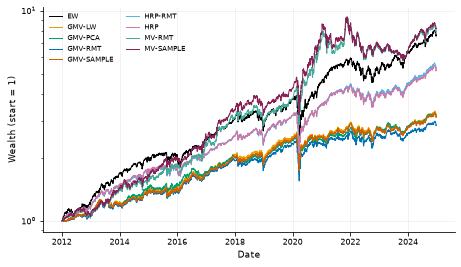

In [10]:
if HAVE_CACHE:
    net = pd.read_parquet(CACHE / "returns_net.parquet")
    turnover = pd.read_parquet(CACHE / "turnover.parquet")
    ann, rf = cfg.run.annualization, cfg.run.rf
    live = pd.DataFrame({s: performance_metrics(net[s], turnover[s], ann, rf) for s in net}).T
    saved = pd.read_csv(TABLES / "main_metrics.csv")
    saved = saved[saved["basis"] == "net"].set_index("strategy")
    cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown"]
    gap = float((live.loc[saved.index, cols] - saved[cols]).abs().max().max())
    say(f"Largest difference to `main_metrics.csv` (net): {gap:.1e}.")
    assert gap < 1e-8
    display(live[[*cols, "sortino", "annual_turnover"]].round(3))
    fig = plot_equity_curves((1.0 + net).cumprod())
    display(fig)
    plt.close(fig)
else:
    say("Cached backtest not found (run `scripts/02_run_backtest.py`); live cell skipped.")

The report tables: metrics net and gross of costs, with Sharpe, Sortino, maximum drawdown, CVaR and turnover. Block-bootstrap tests then ask whether differences against the reference strategies are larger than sampling noise; the studentized version in the appendix adds Holm adjustment and the smallest effect the sample could have detected.

In [11]:
show_table("main_net")
show_table("main_gross")
show_table("significance")
show_table("inference")

**tab01_main_net.** Out-of-sample metrics, net of costs.

| strategy | ann_return | ann_vol | sharpe | sortino | max_drawdown | calmar | cvar_95 | annual_turnover |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| EW | 0.170 | 0.174 | 0.993 | 1.401 | -0.376 | 0.453 | 0.026 | 0.869 |
| GMV-LW | 0.094 | 0.130 | 0.758 | 1.066 | -0.335 | 0.280 | 0.019 | 2.262 |
| GMV-PCA | 0.092 | 0.135 | 0.721 | 1.013 | -0.343 | 0.268 | 0.020 | 2.175 |
| GMV-RMT | 0.084 | 0.136 | 0.663 | 0.932 | -0.362 | 0.233 | 0.020 | 2.195 |
| GMV-SAMPLE | 0.093 | 0.130 | 0.744 | 1.047 | -0.333 | 0.278 | 0.019 | 2.397 |
| HRP-RMT | 0.138 | 0.150 | 0.941 | 1.316 | -0.359 | 0.385 | 0.022 | 2.535 |
| HRP | 0.136 | 0.148 | 0.934 | 1.307 | -0.356 | 0.382 | 0.022 | 2.737 |
| MV-RMT | 0.174 | 0.202 | 0.898 | 1.291 | -0.383 | 0.455 | 0.030 | 6.029 |
| MV-SAMPLE | 0.177 | 0.199 | 0.919 | 1.315 | -0.380 | 0.466 | 0.030 | 5.812 |


**tab02_main_gross.** Out-of-sample metrics, gross of costs.

| strategy | ann_return | ann_vol | sharpe | sortino | max_drawdown | calmar | cvar_95 | annual_turnover |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| EW | 0.171 | 0.174 | 0.998 | 1.409 | -0.376 | 0.456 | 0.026 | 0.869 |
| GMV-LW | 0.097 | 0.130 | 0.776 | 1.092 | -0.335 | 0.288 | 0.019 | 2.262 |
| GMV-PCA | 0.094 | 0.135 | 0.738 | 1.037 | -0.343 | 0.275 | 0.020 | 2.175 |
| GMV-RMT | 0.087 | 0.136 | 0.680 | 0.956 | -0.362 | 0.240 | 0.020 | 2.195 |
| GMV-SAMPLE | 0.095 | 0.130 | 0.763 | 1.075 | -0.333 | 0.286 | 0.019 | 2.397 |
| HRP-RMT | 0.141 | 0.150 | 0.958 | 1.342 | -0.359 | 0.393 | 0.022 | 2.535 |
| HRP | 0.139 | 0.149 | 0.953 | 1.335 | -0.356 | 0.391 | 0.022 | 2.737 |
| MV-RMT | 0.181 | 0.202 | 0.928 | 1.336 | -0.376 | 0.483 | 0.030 | 6.029 |
| MV-SAMPLE | 0.184 | 0.199 | 0.948 | 1.359 | -0.372 | 0.494 | 0.030 | 5.812 |


**tab03_significance.** Bootstrap tests against references.

| reference | strategy | test | estimate | ci_low | ci_high | p_value |
| --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | EW | sharpe_diff | 0.248 | -0.119 | 0.596 | 0.189 |
| GMV-SAMPLE | EW | log_var_ratio | 0.575 | 0.457 | 0.713 | 4.0e-04 |
| GMV-SAMPLE | GMV-LW | sharpe_diff | 0.014 | -0.008 | 0.039 | 0.222 |
| GMV-SAMPLE | GMV-LW | log_var_ratio | -0.012 | -0.020 | -0.005 | 0.003 |
| GMV-SAMPLE | GMV-PCA | sharpe_diff | -0.023 | -0.142 | 0.090 | 0.687 |
| GMV-SAMPLE | GMV-PCA | log_var_ratio | 0.066 | 0.044 | 0.085 | 4.0e-04 |
| GMV-SAMPLE | GMV-RMT | sharpe_diff | -0.081 | -0.179 | 0.018 | 0.102 |
| GMV-SAMPLE | GMV-RMT | log_var_ratio | 0.087 | 0.038 | 0.124 | 4.0e-04 |
| GMV-SAMPLE | HRP-RMT | sharpe_diff | 0.196 | -0.072 | 0.466 | 0.162 |
| GMV-SAMPLE | HRP-RMT | log_var_ratio | 0.278 | 0.204 | 0.357 | 4.0e-04 |
| GMV-SAMPLE | HRP | sharpe_diff | 0.189 | -0.075 | 0.455 | 0.171 |
| GMV-SAMPLE | HRP | log_var_ratio | 0.261 | 0.184 | 0.344 | 4.0e-04 |
| GMV-SAMPLE | MV-RMT | sharpe_diff | 0.153 | -0.324 | 0.591 | 0.559 |
| GMV-SAMPLE | MV-RMT | log_var_ratio | 0.873 | 0.666 | 1.109 | 4.0e-04 |
| GMV-SAMPLE | MV-SAMPLE | sharpe_diff | 0.174 | -0.298 | 0.616 | 0.498 |
| GMV-SAMPLE | MV-SAMPLE | log_var_ratio | 0.846 | 0.630 | 1.088 | 4.0e-04 |
| EW | GMV-LW | sharpe_diff | -0.234 | -0.575 | 0.129 | 0.210 |
| EW | GMV-LW | log_var_ratio | -0.587 | -0.727 | -0.469 | 4.0e-04 |
| EW | GMV-PCA | sharpe_diff | -0.272 | -0.677 | 0.140 | 0.191 |
| EW | GMV-PCA | log_var_ratio | -0.509 | -0.658 | -0.385 | 4.0e-04 |
| EW | GMV-RMT | sharpe_diff | -0.329 | -0.703 | 0.059 | 0.096 |
| EW | GMV-RMT | log_var_ratio | -0.488 | -0.663 | -0.341 | 4.0e-04 |
| EW | GMV-SAMPLE | sharpe_diff | -0.248 | -0.596 | 0.119 | 0.189 |
| EW | GMV-SAMPLE | log_var_ratio | -0.575 | -0.713 | -0.457 | 4.0e-04 |
| EW | HRP-RMT | sharpe_diff | -0.052 | -0.166 | 0.081 | 0.465 |
| EW | HRP-RMT | log_var_ratio | -0.297 | -0.370 | -0.235 | 4.0e-04 |
| EW | HRP | sharpe_diff | -0.059 | -0.176 | 0.074 | 0.406 |
| EW | HRP | log_var_ratio | -0.314 | -0.382 | -0.258 | 4.0e-04 |
| EW | MV-RMT | sharpe_diff | -0.095 | -0.567 | 0.354 | 0.663 |
| EW | MV-RMT | log_var_ratio | 0.298 | 0.150 | 0.458 | 4.0e-04 |
| EW | MV-SAMPLE | sharpe_diff | -0.074 | -0.555 | 0.376 | 0.732 |
| EW | MV-SAMPLE | log_var_ratio | 0.271 | 0.116 | 0.435 | 4.0e-04 |
| GMV-LW | EW | sharpe_diff | 0.234 | -0.129 | 0.575 | 0.210 |
| GMV-LW | EW | log_var_ratio | 0.587 | 0.469 | 0.727 | 4.0e-04 |
| GMV-LW | GMV-PCA | sharpe_diff | -0.037 | -0.157 | 0.076 | 0.517 |
| GMV-LW | GMV-PCA | log_var_ratio | 0.078 | 0.057 | 0.098 | 4.0e-04 |
| GMV-LW | GMV-RMT | sharpe_diff | -0.095 | -0.196 | 0.004 | 0.060 |
| GMV-LW | GMV-RMT | log_var_ratio | 0.099 | 0.052 | 0.138 | 4.0e-04 |
| GMV-LW | GMV-SAMPLE | sharpe_diff | -0.014 | -0.039 | 0.008 | 0.222 |
| GMV-LW | GMV-SAMPLE | log_var_ratio | 0.012 | 0.005 | 0.020 | 0.003 |
| GMV-LW | HRP-RMT | sharpe_diff | 0.182 | -0.074 | 0.441 | 0.176 |
| GMV-LW | HRP-RMT | log_var_ratio | 0.290 | 0.218 | 0.370 | 4.0e-04 |
| GMV-LW | HRP | sharpe_diff | 0.175 | -0.080 | 0.430 | 0.189 |
| GMV-LW | HRP | log_var_ratio | 0.273 | 0.199 | 0.356 | 4.0e-04 |
| GMV-LW | MV-RMT | sharpe_diff | 0.139 | -0.335 | 0.577 | 0.599 |
| GMV-LW | MV-RMT | log_var_ratio | 0.885 | 0.674 | 1.126 | 4.0e-04 |
| GMV-LW | MV-SAMPLE | sharpe_diff | 0.160 | -0.319 | 0.600 | 0.539 |
| GMV-LW | MV-SAMPLE | log_var_ratio | 0.858 | 0.639 | 1.104 | 4.0e-04 |


**tabA09_inference.** Extension: studentized bootstrap tests with Holm adjustment and detectable effects.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | EW | sharpe_diff | 0.248 | -0.121 | 0.617 | 0.185 | 1.000 | 0.523 |
| GMV-SAMPLE | EW | log_var_ratio | 0.575 | 0.330 | 0.820 | 2.0e-04 | 0.002 | 0.225 |
| GMV-SAMPLE | GMV-LW | sharpe_diff | 0.014 | -0.010 | 0.038 | 0.237 | 1.000 | 0.033 |
| GMV-SAMPLE | GMV-LW | log_var_ratio | -0.012 | -0.019 | -0.005 | 6.0e-04 | 0.002 | 0.008 |
| GMV-SAMPLE | GMV-PCA | sharpe_diff | -0.023 | -0.137 | 0.091 | 0.685 | 1.000 | 0.166 |
| GMV-SAMPLE | GMV-PCA | log_var_ratio | 0.066 | 0.047 | 0.084 | 2.0e-04 | 0.002 | 0.026 |
| GMV-SAMPLE | GMV-RMT | sharpe_diff | -0.081 | -0.173 | 0.011 | 0.088 | 0.707 | 0.133 |
| GMV-SAMPLE | GMV-RMT | log_var_ratio | 0.087 | -0.011 | 0.186 | 0.060 | 0.060 | 0.070 |
| GMV-SAMPLE | HRP-RMT | sharpe_diff | 0.197 | -0.091 | 0.484 | 0.162 | 1.000 | 0.397 |
| GMV-SAMPLE | HRP-RMT | log_var_ratio | 0.278 | 0.158 | 0.399 | 2.0e-04 | 0.002 | 0.134 |
| GMV-SAMPLE | HRP | sharpe_diff | 0.189 | -0.093 | 0.472 | 0.174 | 1.000 | 0.393 |
| GMV-SAMPLE | HRP | log_var_ratio | 0.261 | 0.129 | 0.394 | 2.0e-04 | 0.002 | 0.143 |
| GMV-SAMPLE | MV-RMT | sharpe_diff | 0.153 | -0.301 | 0.607 | 0.519 | 1.000 | 0.629 |
| GMV-SAMPLE | MV-RMT | log_var_ratio | 0.873 | 0.475 | 1.270 | 2.0e-04 | 0.002 | 0.348 |
| GMV-SAMPLE | MV-SAMPLE | sharpe_diff | 0.174 | -0.278 | 0.627 | 0.462 | 1.000 | 0.630 |
| GMV-SAMPLE | MV-SAMPLE | log_var_ratio | 0.846 | 0.431 | 1.261 | 2.0e-04 | 0.002 | 0.358 |
| EW | GMV-LW | sharpe_diff | -0.234 | -0.596 | 0.127 | 0.200 | 1.000 | 0.513 |
| EW | GMV-LW | log_var_ratio | -0.587 | -0.842 | -0.333 | 2.0e-04 | 0.002 | 0.226 |
| EW | GMV-PCA | sharpe_diff | -0.272 | -0.693 | 0.150 | 0.195 | 1.000 | 0.592 |
| EW | GMV-PCA | log_var_ratio | -0.509 | -0.761 | -0.258 | 2.0e-04 | 0.002 | 0.235 |
| EW | GMV-RMT | sharpe_diff | -0.329 | -0.715 | 0.057 | 0.092 | 0.736 | 0.548 |
| EW | GMV-RMT | log_var_ratio | -0.488 | -0.846 | -0.130 | 0.012 | 0.012 | 0.286 |
| EW | GMV-SAMPLE | sharpe_diff | -0.248 | -0.617 | 0.121 | 0.185 | 1.000 | 0.523 |
| EW | GMV-SAMPLE | log_var_ratio | -0.575 | -0.820 | -0.330 | 2.0e-04 | 0.002 | 0.225 |
| EW | HRP-RMT | sharpe_diff | -0.052 | -0.172 | 0.069 | 0.405 | 1.000 | 0.170 |
| EW | HRP-RMT | log_var_ratio | -0.297 | -0.440 | -0.153 | 6.0e-04 | 0.002 | 0.106 |
| EW | HRP | sharpe_diff | -0.059 | -0.182 | 0.064 | 0.349 | 1.000 | 0.176 |
| EW | HRP | log_var_ratio | -0.314 | -0.434 | -0.194 | 2.0e-04 | 0.002 | 0.097 |
| EW | MV-RMT | sharpe_diff | -0.095 | -0.551 | 0.361 | 0.679 | 1.000 | 0.640 |
| EW | MV-RMT | log_var_ratio | 0.298 | 0.142 | 0.454 | 6.0e-04 | 0.002 | 0.203 |
| EW | MV-SAMPLE | sharpe_diff | -0.074 | -0.533 | 0.385 | 0.749 | 1.000 | 0.641 |
| EW | MV-SAMPLE | log_var_ratio | 0.271 | 0.108 | 0.434 | 0.002 | 0.003 | 0.209 |
| GMV-LW | EW | sharpe_diff | 0.234 | -0.127 | 0.596 | 0.200 | 1.000 | 0.513 |
| GMV-LW | EW | log_var_ratio | 0.587 | 0.333 | 0.842 | 2.0e-04 | 0.002 | 0.226 |
| GMV-LW | GMV-PCA | sharpe_diff | -0.037 | -0.151 | 0.076 | 0.523 | 1.000 | 0.166 |
| GMV-LW | GMV-PCA | log_var_ratio | 0.078 | 0.060 | 0.096 | 2.0e-04 | 0.002 | 0.025 |
| GMV-LW | GMV-RMT | sharpe_diff | -0.095 | -0.189 | -7.5e-04 | 0.049 | 0.390 | 0.137 |
| GMV-LW | GMV-RMT | log_var_ratio | 0.099 | 0.002 | 0.197 | 0.047 | 0.047 | 0.070 |
| GMV-LW | GMV-SAMPLE | sharpe_diff | -0.014 | -0.038 | 0.010 | 0.237 | 1.000 | 0.033 |
| GMV-LW | GMV-SAMPLE | log_var_ratio | 0.012 | 0.005 | 0.019 | 6.0e-04 | 0.002 | 0.008 |
| GMV-LW | HRP-RMT | sharpe_diff | 0.182 | -0.094 | 0.459 | 0.176 | 1.000 | 0.383 |
| GMV-LW | HRP-RMT | log_var_ratio | 0.290 | 0.171 | 0.410 | 2.0e-04 | 0.002 | 0.134 |
| GMV-LW | HRP | sharpe_diff | 0.175 | -0.098 | 0.449 | 0.192 | 1.000 | 0.379 |
| GMV-LW | HRP | log_var_ratio | 0.273 | 0.140 | 0.407 | 2.0e-04 | 0.002 | 0.142 |
| GMV-LW | MV-RMT | sharpe_diff | 0.139 | -0.317 | 0.595 | 0.557 | 1.000 | 0.630 |
| GMV-LW | MV-RMT | log_var_ratio | 0.885 | 0.483 | 1.287 | 2.0e-04 | 0.002 | 0.352 |
| GMV-LW | MV-SAMPLE | sharpe_diff | 0.160 | -0.297 | 0.618 | 0.499 | 1.000 | 0.631 |
| GMV-LW | MV-SAMPLE | log_var_ratio | 0.858 | 0.438 | 1.279 | 2.0e-04 | 0.002 | 0.361 |


**fig05_equity.** Net equity curves with 1/N and the S&P 500.

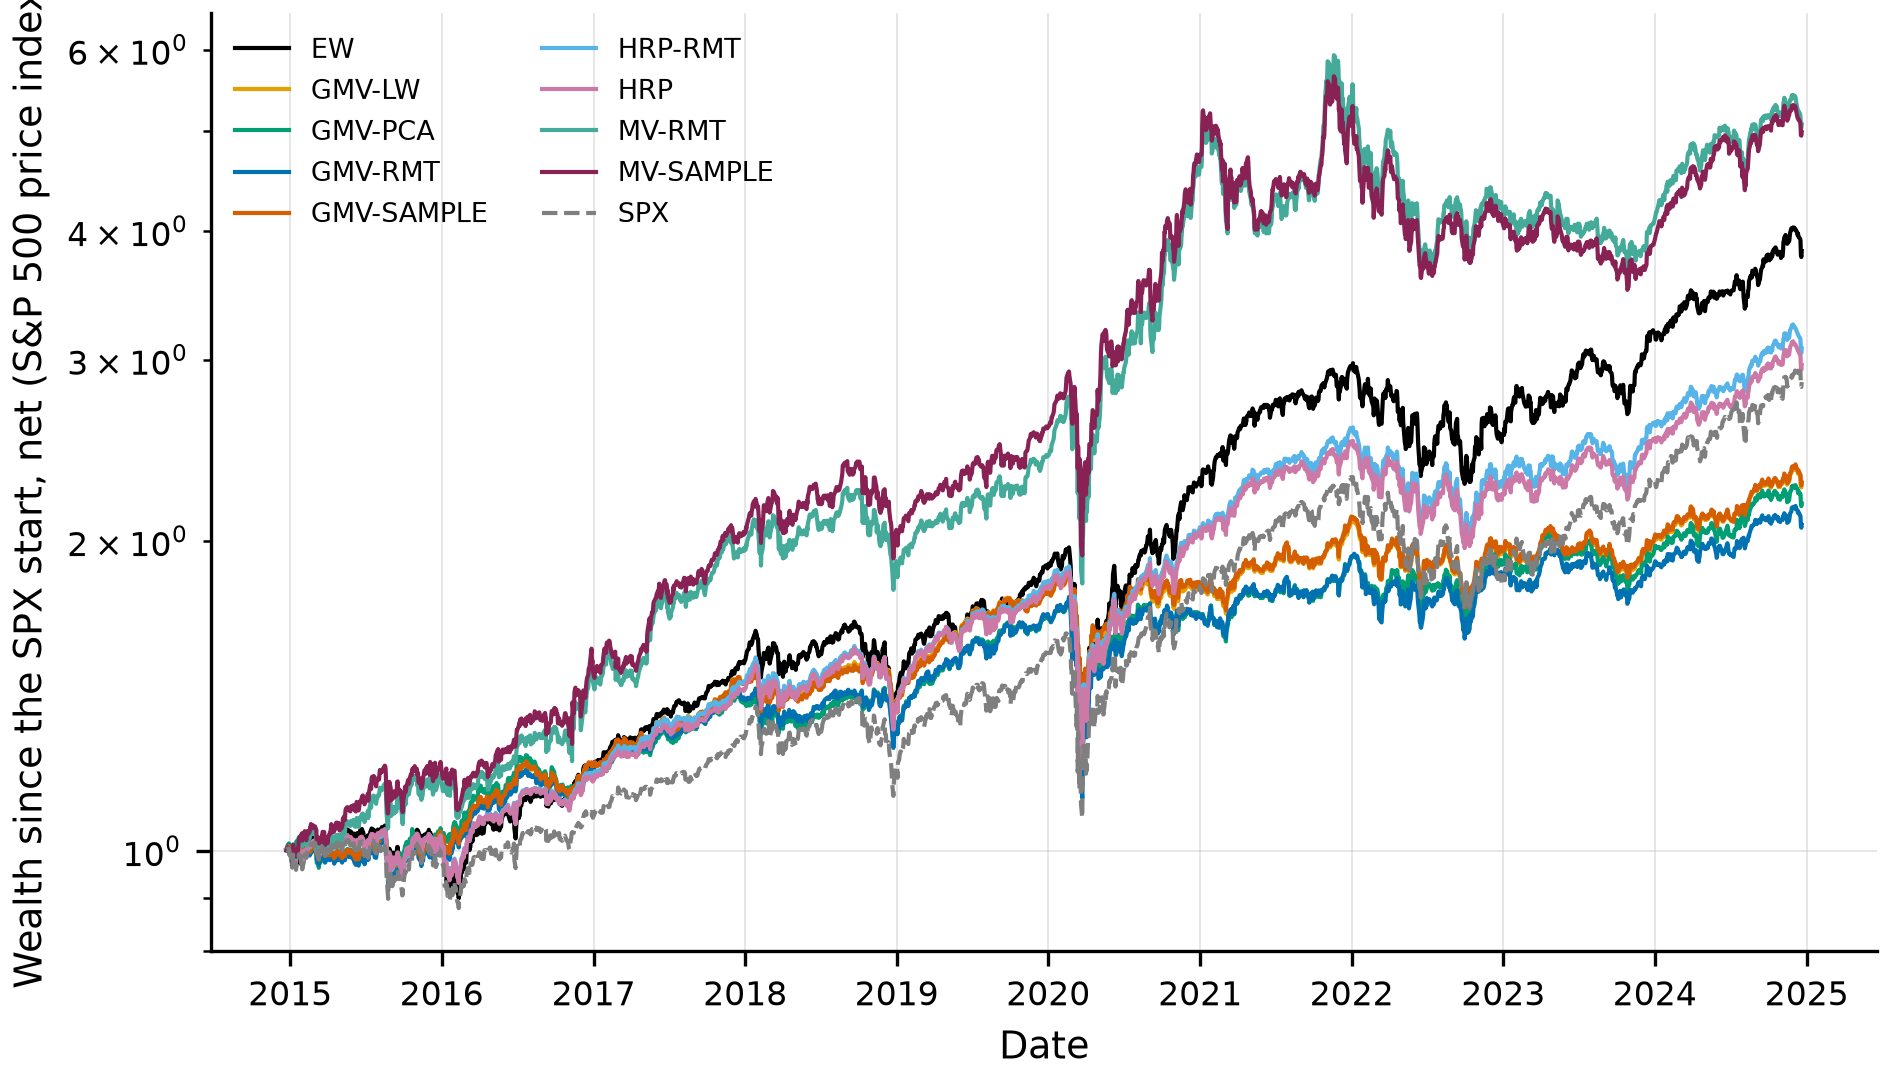

**fig06_drawdowns.** Drawdowns of the core strategies.

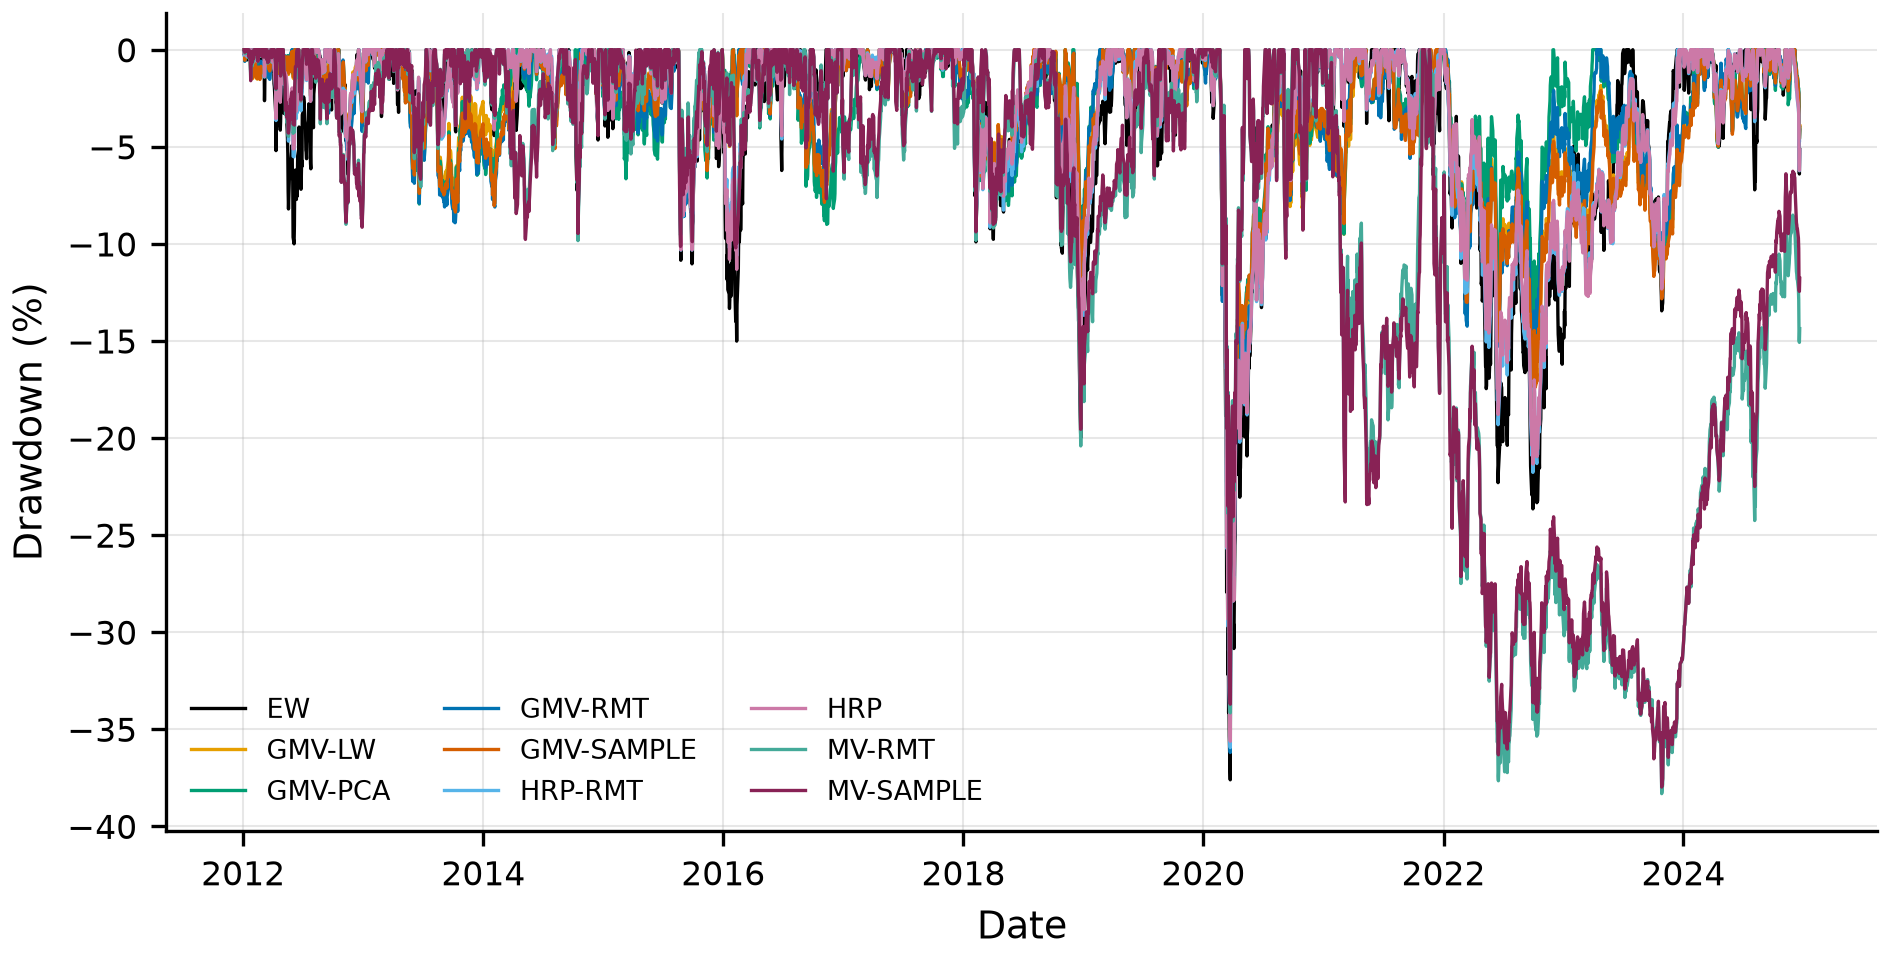

**figA06_risk_return.** Risk against return.

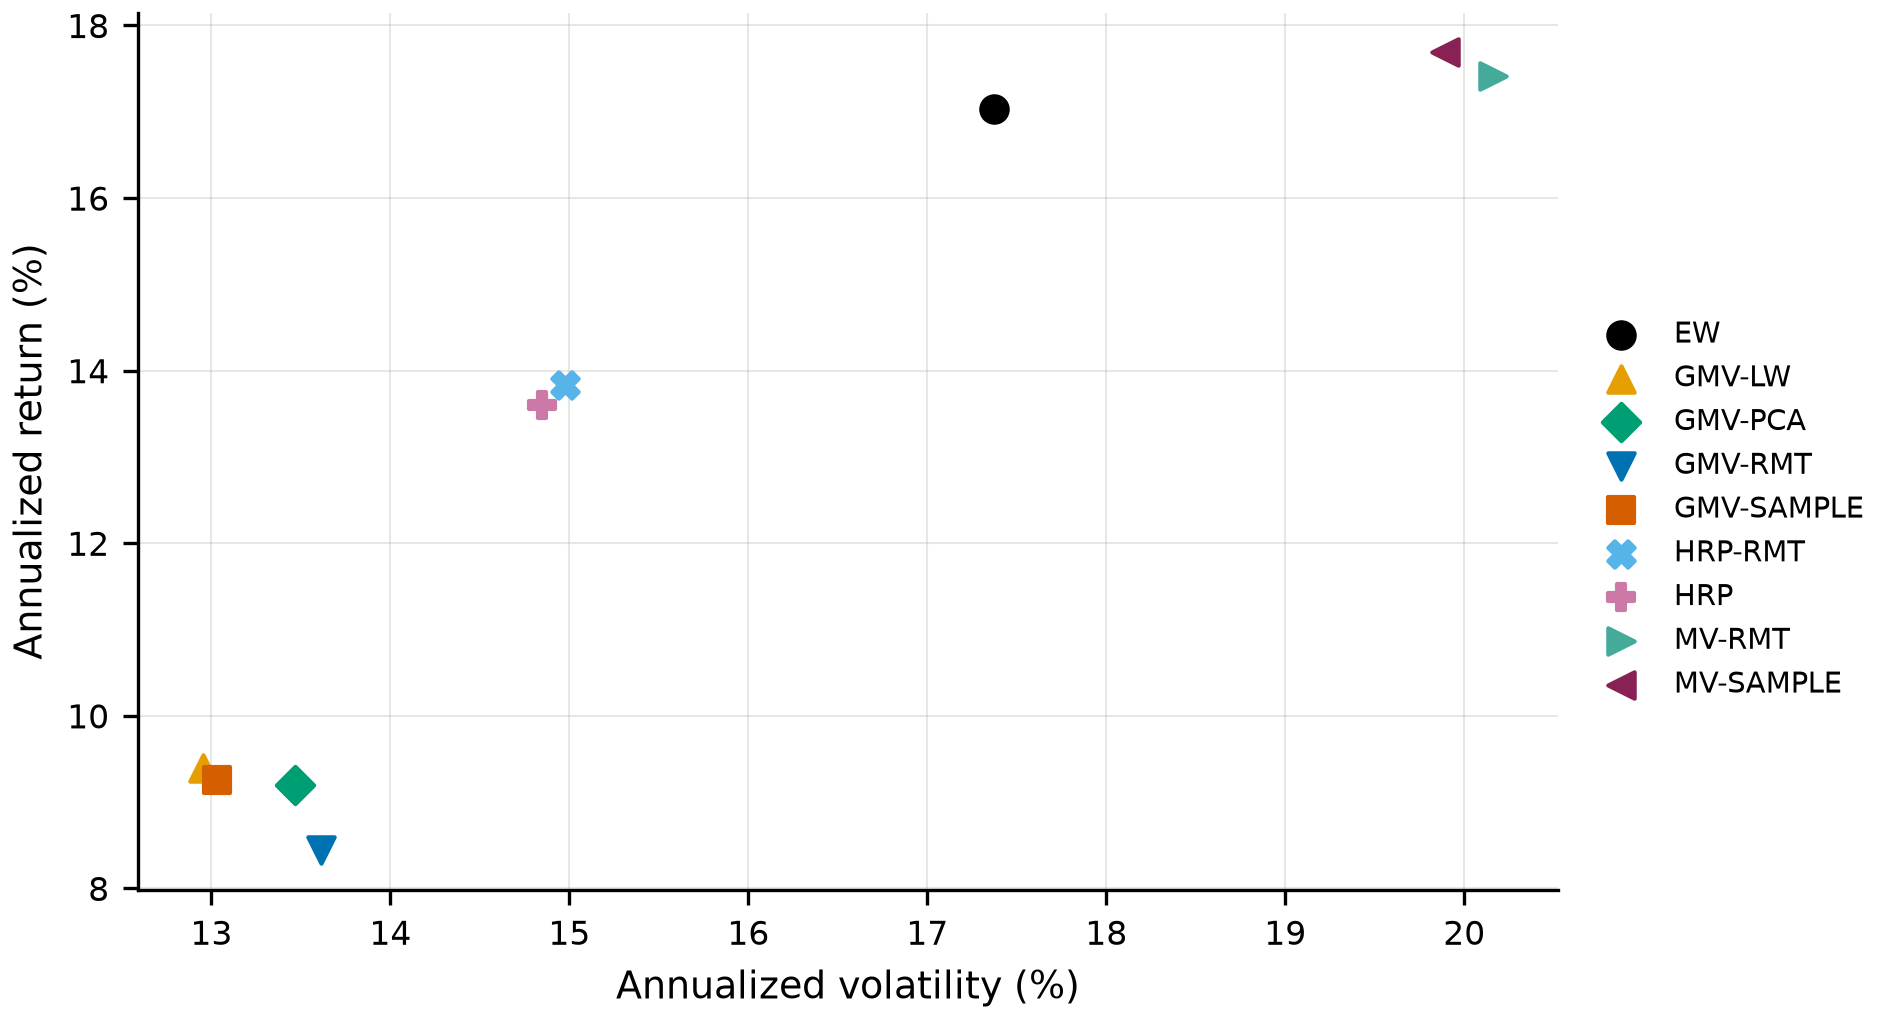

**figA07_rolling_sharpe.** Rolling Sharpe and volatility.

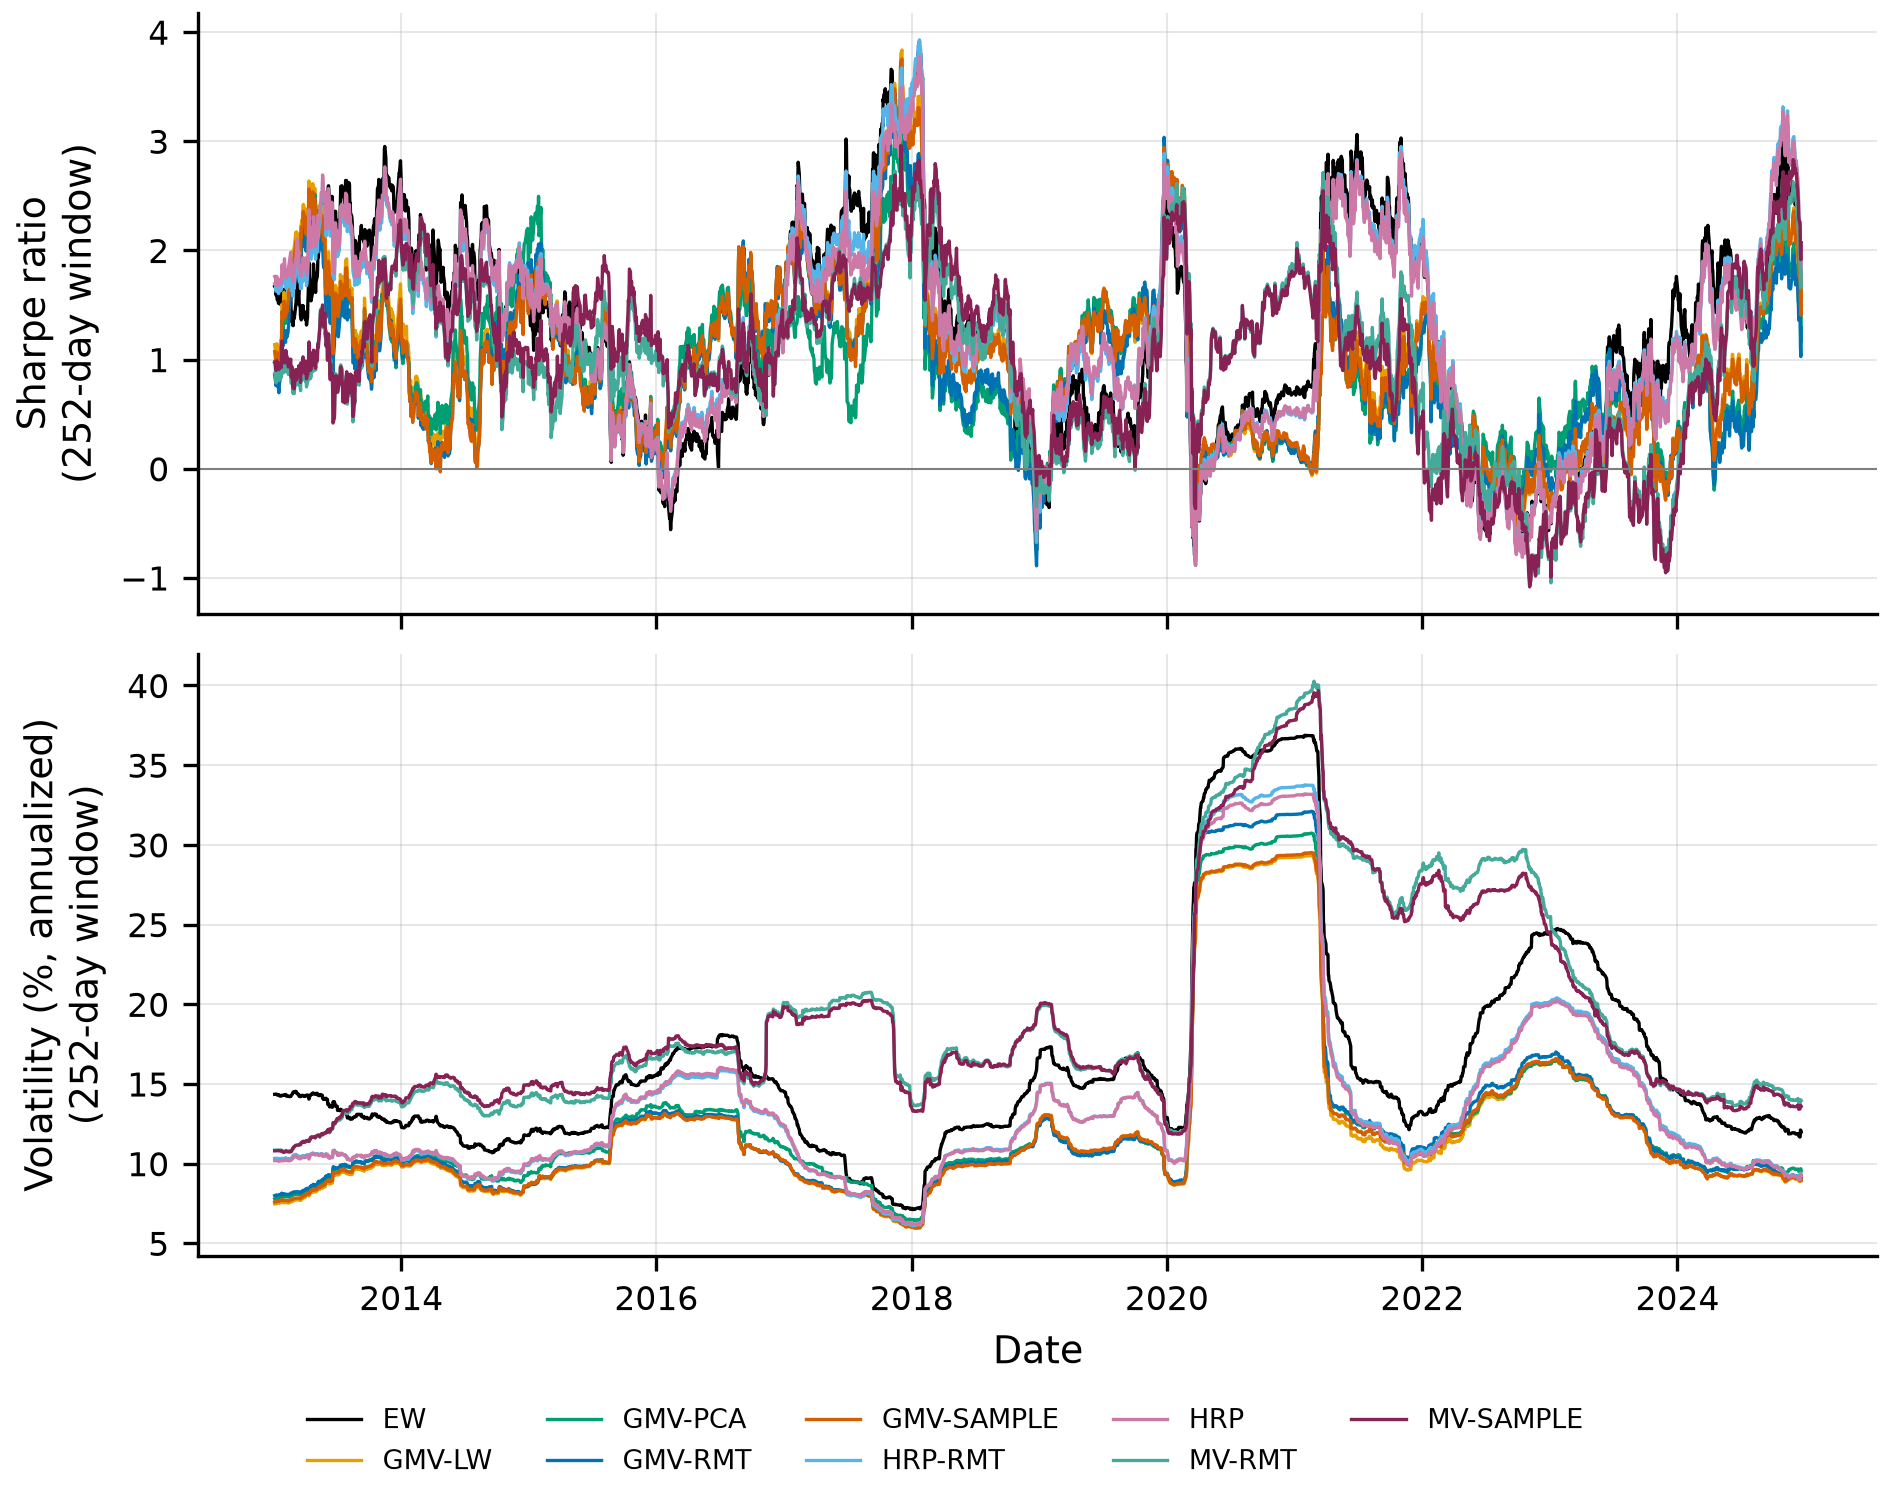

In [12]:
show_figure("equity")
show_figure("drawdowns")
show_figure("risk_return")
show_figure("rolling_sharpe")

Does the optimizer know how risky its portfolio is? The ratio of realized to predicted volatility is the direct measure of how much estimation error leaks into the risk forecast. Turnover and the effective number of names show how stable and diversified the weights are.

**fig07_vol_forecast.** Realized over predicted volatility.

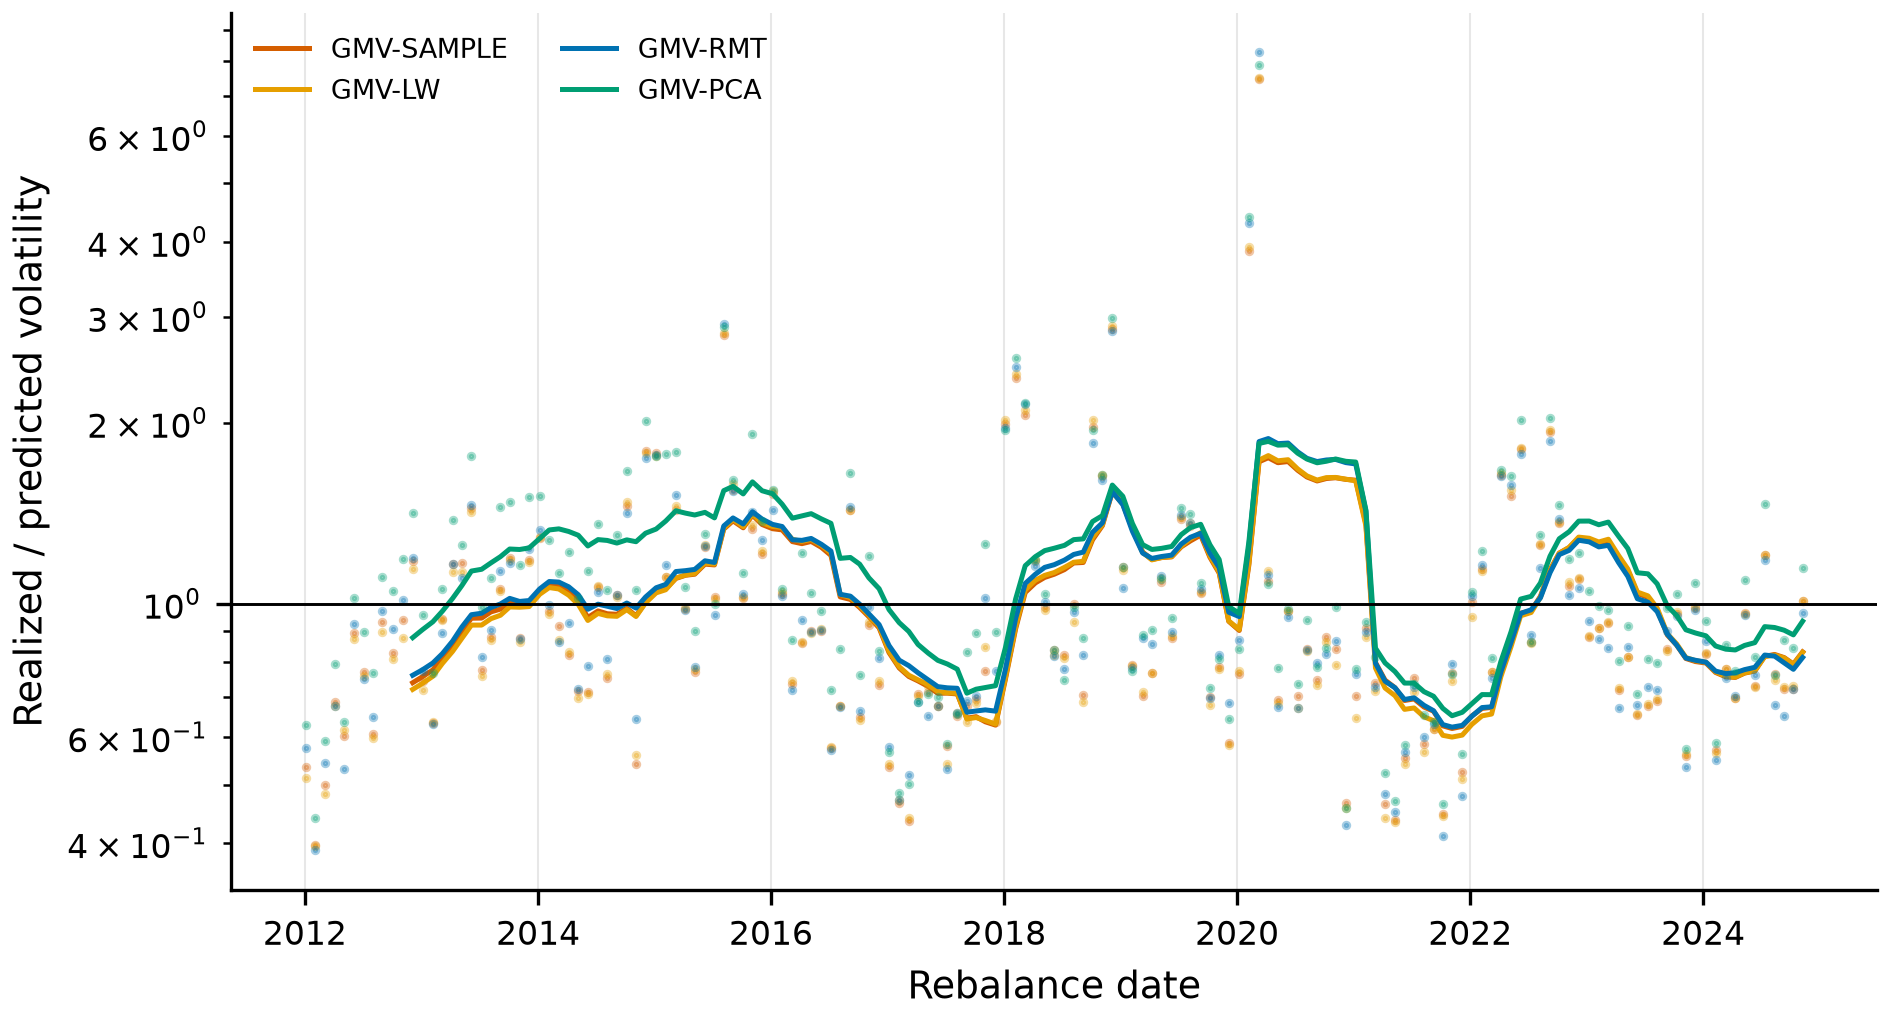

**tabA03_risk_forecast.** Volatility forecast quality.

| strategy | n_periods | mean_ratio | median_ratio | mean_log_ratio | pooled_variance_ratio | bias_statistic | realized_vol_pooled | mean_predicted_vol |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | 155 | 1.020 | 0.860 | -0.094 | 1.319 | 1.227 | 0.130 | 0.113 |
| GMV-LW | 155 | 1.018 | 0.860 | -0.099 | 1.314 | 1.230 | 0.130 | 0.113 |
| GMV-RMT | 155 | 1.039 | 0.877 | -0.079 | 1.393 | 1.276 | 0.136 | 0.115 |
| GMV-PCA | 155 | 1.147 | 0.988 | 0.028 | 1.605 | 1.356 | 0.135 | 0.106 |
| HRP | 155 | 0.899 | 0.733 | -0.252 | 0.972 | 1.105 | 0.148 | 0.151 |
| HRP-RMT | 155 | 0.891 | 0.718 | -0.262 | 0.953 | 1.094 | 0.150 | 0.153 |
| MV-SAMPLE | 155 | 1.029 | 0.896 | -0.067 | 1.122 | 1.180 | 0.199 | 0.188 |
| MV-RMT | 155 | 1.016 | 0.880 | -0.081 | 1.065 | 1.173 | 0.202 | 0.195 |


**fig08_turnover.** Turnover and effective number of names.

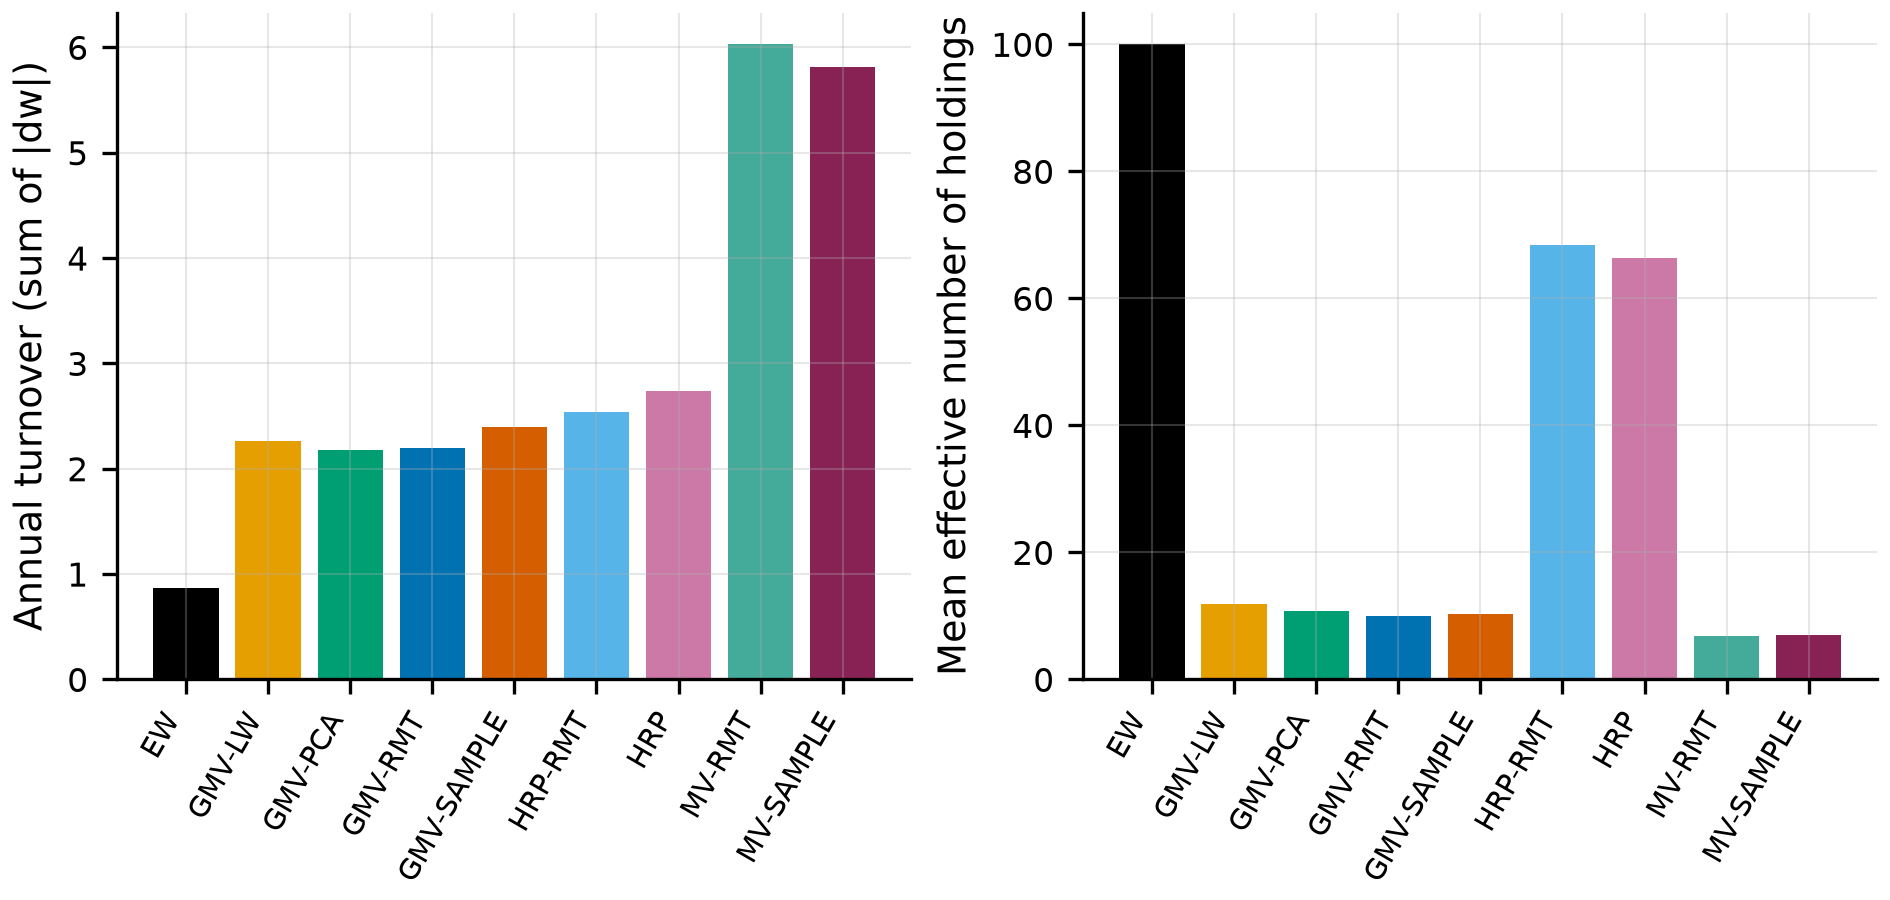

**tabA02_concentration.** Weight concentration.

| strategy | mean_hhi | mean_effective_n | mean_max_weight | mean_top10_share | mean_n_positions | share_zero | p50 | p90 | p99 | max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| EW | 0.010 | 100.000 | 0.010 | 0.100 | 100.000 | 0.000 | 0.010 | 0.010 | 0.010 | 0.010 |
| GMV-SAMPLE | 0.112 | 10.275 | 0.207 | 0.844 | 20.109 | 0.799 | 2.3e-12 | 0.030 | 0.158 | 0.430 |
| GMV-LW | 0.094 | 11.888 | 0.177 | 0.809 | 21.994 | 0.780 | 2.6e-12 | 0.035 | 0.142 | 0.354 |
| GMV-RMT | 0.112 | 10.008 | 0.202 | 0.859 | 19.763 | 0.802 | 2.7e-12 | 0.029 | 0.160 | 0.417 |
| GMV-PCA | 0.101 | 10.690 | 0.178 | 0.852 | 19.538 | 0.805 | 2.2e-12 | 0.032 | 0.151 | 0.294 |
| HRP | 0.015 | 66.327 | 0.039 | 0.266 | 99.865 | 0.001 | 0.008 | 0.019 | 0.037 | 0.064 |
| HRP-RMT | 0.015 | 68.381 | 0.038 | 0.257 | 99.955 | 4.5e-04 | 0.008 | 0.019 | 0.036 | 0.061 |
| MV-SAMPLE | 0.157 | 6.932 | 0.256 | 0.967 | 11.365 | 0.886 | 1.5e-13 | 0.014 | 0.208 | 0.512 |
| MV-RMT | 0.162 | 6.841 | 0.263 | 0.962 | 11.359 | 0.886 | 1.6e-13 | 0.014 | 0.214 | 0.481 |


In [13]:
show_figure("vol_forecast")
show_table("risk_forecast")
show_figure("turnover")
show_table("concentration")

## 6. Robustness: regimes, sensitivity, weight structure

**Regimes.** Metrics by subperiod (including the COVID stress period and 2022) show whether a ranking holds across market conditions. **Sensitivity.** Universe size, window length, costs, weight cap, number of PCA factors and HRP linkage are varied; the sensitivity tables are reported as sensitivity only and never used to choose the headline configuration. **Long-only constraint.** Hypothesis H3 compares the long-only GMV with the unconstrained one, since the constraint itself regularizes.

**tab04_subperiods.** Metrics by subperiod.

| period | strategy | ann_return | ann_vol | sharpe | max_drawdown |
| --- | --- | --- | --- | --- | --- |
| full | EW | 0.170 | 0.174 | 0.993 | -0.376 |
| full | GMV-LW | 0.094 | 0.130 | 0.758 | -0.335 |
| full | GMV-PCA | 0.092 | 0.135 | 0.721 | -0.343 |
| full | GMV-RMT | 0.084 | 0.136 | 0.663 | -0.362 |
| full | GMV-SAMPLE | 0.093 | 0.130 | 0.744 | -0.333 |
| full | HRP-RMT | 0.138 | 0.150 | 0.941 | -0.359 |
| full | HRP | 0.136 | 0.148 | 0.934 | -0.356 |
| full | MV-RMT | 0.174 | 0.202 | 0.898 | -0.383 |
| full | MV-SAMPLE | 0.177 | 0.199 | 0.919 | -0.380 |
| covid | EW | 0.200 | 0.390 | 0.665 | -0.376 |
| covid | GMV-LW | -0.030 | 0.311 | 0.056 | -0.335 |
| covid | GMV-PCA | -0.030 | 0.325 | 0.068 | -0.343 |
| covid | GMV-RMT | -0.033 | 0.340 | 0.072 | -0.362 |
| covid | GMV-SAMPLE | -0.023 | 0.312 | 0.081 | -0.333 |
| covid | HRP-RMT | 0.110 | 0.357 | 0.472 | -0.359 |
| covid | HRP | 0.113 | 0.352 | 0.482 | -0.356 |
| covid | MV-RMT | 0.797 | 0.410 | 1.636 | -0.342 |
| covid | MV-SAMPLE | 0.743 | 0.402 | 1.584 | -0.337 |
| year_2022 | EW | -0.141 | 0.245 | -0.498 | -0.237 |
| year_2022 | GMV-LW | -0.070 | 0.163 | -0.367 | -0.181 |
| year_2022 | GMV-PCA | -0.016 | 0.163 | -0.020 | -0.148 |
| year_2022 | GMV-RMT | -0.044 | 0.168 | -0.182 | -0.173 |
| year_2022 | GMV-SAMPLE | -0.073 | 0.164 | -0.382 | -0.184 |
| year_2022 | HRP-RMT | -0.114 | 0.202 | -0.497 | -0.218 |
| year_2022 | HRP | -0.113 | 0.200 | -0.499 | -0.213 |
| year_2022 | MV-RMT | -0.204 | 0.255 | -0.769 | -0.335 |
| year_2022 | MV-SAMPLE | -0.194 | 0.245 | -0.757 | -0.319 |
| calm | EW | 0.201 | 0.134 | 1.436 | -0.200 |
| calm | GMV-LW | 0.121 | 0.098 | 1.213 | -0.129 |
| calm | GMV-PCA | 0.113 | 0.102 | 1.095 | -0.121 |
| calm | GMV-RMT | 0.107 | 0.100 | 1.062 | -0.125 |
| calm | GMV-SAMPLE | 0.119 | 0.099 | 1.186 | -0.128 |
| calm | HRP-RMT | 0.167 | 0.112 | 1.436 | -0.169 |
| calm | HRP | 0.163 | 0.111 | 1.415 | -0.166 |
| calm | MV-RMT | 0.176 | 0.168 | 1.047 | -0.225 |
| calm | MV-SAMPLE | 0.180 | 0.167 | 1.075 | -0.234 |
| high_vol | EW | 0.171 | 0.240 | 0.778 | -0.350 |
| high_vol | GMV-LW | 0.069 | 0.179 | 0.463 | -0.327 |
| high_vol | GMV-PCA | 0.093 | 0.185 | 0.572 | -0.336 |
| high_vol | GMV-RMT | 0.086 | 0.191 | 0.526 | -0.350 |
| high_vol | GMV-SAMPLE | 0.070 | 0.180 | 0.467 | -0.325 |
| high_vol | HRP-RMT | 0.131 | 0.210 | 0.692 | -0.338 |
| high_vol | HRP | 0.127 | 0.207 | 0.682 | -0.335 |
| high_vol | MV-RMT | 0.119 | 0.268 | 0.554 | -0.430 |
| high_vol | MV-SAMPLE | 0.116 | 0.264 | 0.548 | -0.412 |
| low_vol | EW | 0.152 | 0.113 | 1.309 | -0.135 |
| low_vol | GMV-LW | 0.104 | 0.088 | 1.163 | -0.103 |
| low_vol | GMV-PCA | 0.064 | 0.094 | 0.704 | -0.126 |
| low_vol | GMV-RMT | 0.067 | 0.091 | 0.759 | -0.128 |
| low_vol | GMV-SAMPLE | 0.103 | 0.089 | 1.148 | -0.102 |
| low_vol | HRP-RMT | 0.129 | 0.094 | 1.341 | -0.109 |
| low_vol | HRP | 0.123 | 0.093 | 1.292 | -0.110 |
| low_vol | MV-RMT | 0.254 | 0.171 | 1.410 | -0.159 |
| low_vol | MV-SAMPLE | 0.244 | 0.164 | 1.417 | -0.160 |


**fig09_subperiods.** Sharpe and drawdown by subperiod.

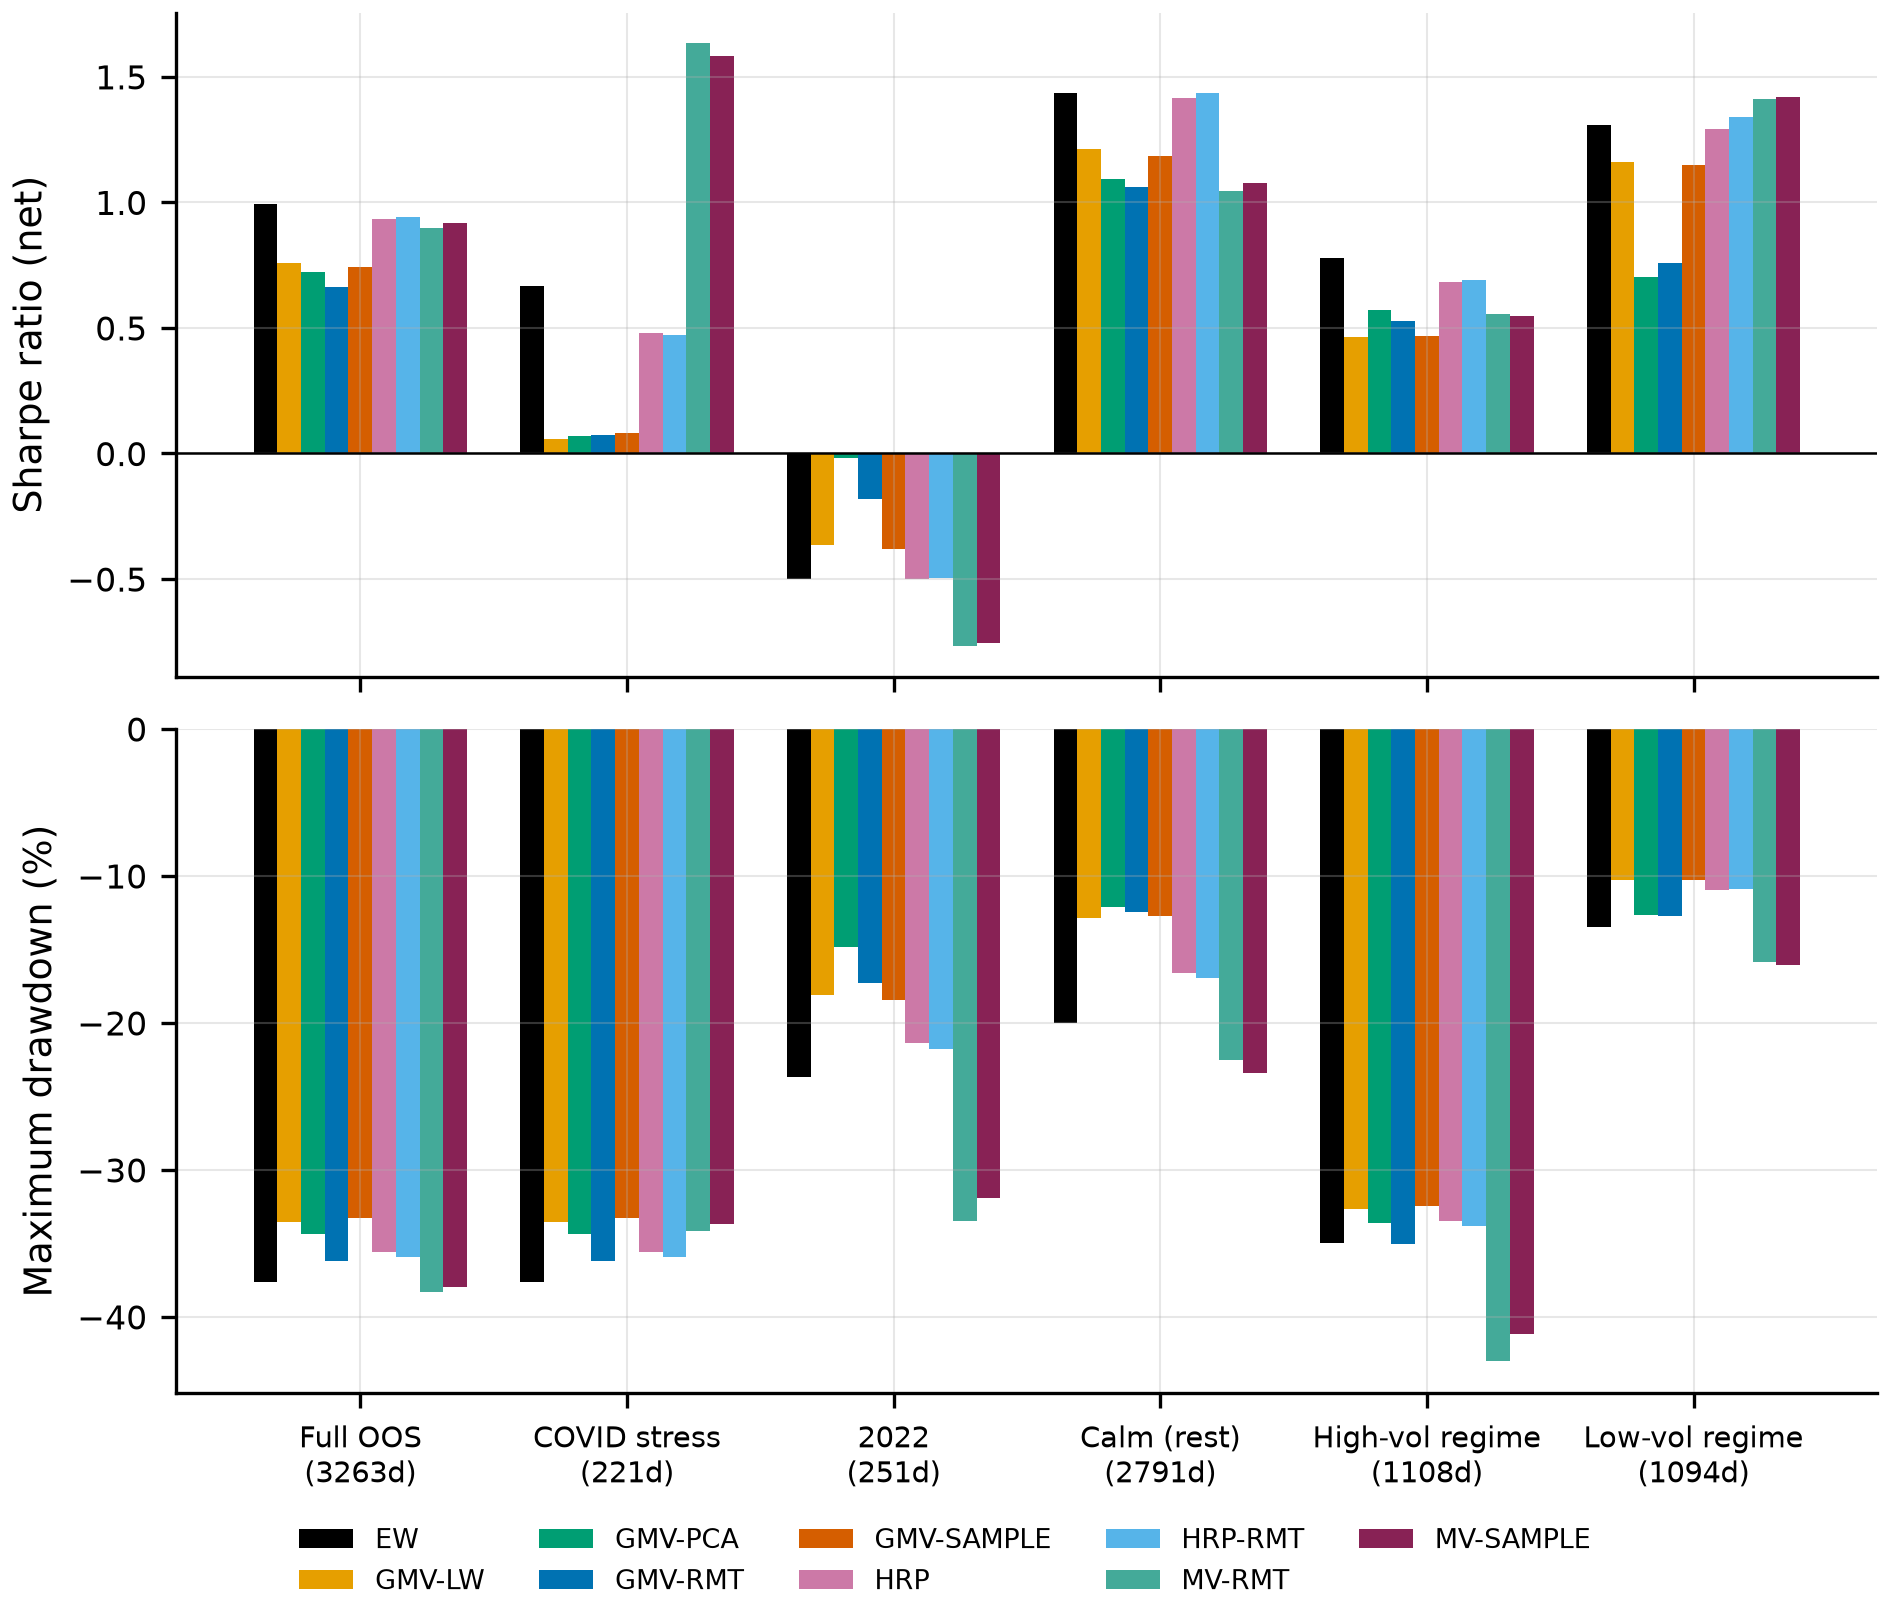

**tab05_sensitivity.** Sensitivity analyses.

| grid | variant | strategy | period | ann_vol | sharpe | annual_turnover |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | baseline | EW | own | 0.174 | 0.993 | 0.869 |
| baseline | baseline | GMV-SAMPLE | own | 0.130 | 0.744 | 2.397 |
| baseline | baseline | GMV-LW | own | 0.130 | 0.758 | 2.262 |
| baseline | baseline | GMV-RMT | own | 0.136 | 0.663 | 2.195 |
| baseline | baseline | GMV-PCA | own | 0.135 | 0.721 | 2.175 |
| baseline | baseline | HRP | own | 0.148 | 0.934 | 2.737 |
| baseline | baseline | HRP-RMT | own | 0.150 | 0.941 | 2.535 |
| baseline | baseline | MV-SAMPLE | own | 0.199 | 0.919 | 5.812 |
| baseline | baseline | MV-RMT | own | 0.202 | 0.898 | 6.029 |
| baseline | baseline | EW | common | 0.176 | 0.948 | 0.879 |
| baseline | baseline | GMV-SAMPLE | common | 0.134 | 0.734 | 2.508 |
| baseline | baseline | GMV-LW | common | 0.133 | 0.746 | 2.361 |
| baseline | baseline | GMV-RMT | common | 0.140 | 0.659 | 2.300 |
| baseline | baseline | GMV-PCA | common | 0.138 | 0.714 | 2.297 |
| baseline | baseline | HRP | common | 0.152 | 0.891 | 2.760 |
| baseline | baseline | HRP-RMT | common | 0.153 | 0.902 | 2.561 |
| baseline | baseline | MV-SAMPLE | common | 0.205 | 0.924 | 5.797 |
| baseline | baseline | MV-RMT | common | 0.208 | 0.907 | 5.989 |
| lookback | T=252 | EW | own | 0.181 | 0.899 | 0.867 |
| lookback | T=252 | GMV-SAMPLE | own | 0.127 | 0.843 | 4.055 |
| lookback | T=252 | GMV-LW | own | 0.127 | 0.850 | 3.668 |
| lookback | T=252 | GMV-RMT | own | 0.130 | 0.796 | 3.442 |
| lookback | T=252 | GMV-PCA | own | 0.129 | 0.871 | 3.306 |
| lookback | T=252 | HRP | own | 0.150 | 0.920 | 3.037 |
| lookback | T=252 | HRP-RMT | own | 0.151 | 0.921 | 2.765 |
| lookback | T=252 | MV-SAMPLE | own | 0.203 | 0.700 | 8.606 |
| lookback | T=252 | MV-RMT | own | 0.209 | 0.687 | 8.513 |
| lookback | T=252 | EW | common | 0.176 | 0.950 | 0.881 |
| lookback | T=252 | GMV-SAMPLE | common | 0.130 | 0.822 | 4.196 |
| lookback | T=252 | GMV-LW | common | 0.129 | 0.835 | 3.795 |
| lookback | T=252 | GMV-RMT | common | 0.134 | 0.779 | 3.551 |
| lookback | T=252 | GMV-PCA | common | 0.133 | 0.848 | 3.514 |
| lookback | T=252 | HRP | common | 0.149 | 0.929 | 3.052 |
| lookback | T=252 | HRP-RMT | common | 0.151 | 0.925 | 2.778 |
| lookback | T=252 | MV-SAMPLE | common | 0.208 | 0.739 | 8.346 |
| lookback | T=252 | MV-RMT | common | 0.215 | 0.719 | 8.437 |
| lookback | T=756 | EW | own | 0.176 | 0.949 | 0.860 |
| lookback | T=756 | GMV-SAMPLE | own | 0.136 | 0.752 | 1.821 |
| lookback | T=756 | GMV-LW | own | 0.136 | 0.756 | 1.778 |
| lookback | T=756 | GMV-RMT | own | 0.142 | 0.718 | 1.823 |
| lookback | T=756 | GMV-PCA | own | 0.141 | 0.746 | 1.715 |
| lookback | T=756 | HRP | own | 0.153 | 0.913 | 2.660 |
| lookback | T=756 | HRP-RMT | own | 0.154 | 0.913 | 2.494 |
| lookback | T=756 | MV-SAMPLE | own | 0.200 | 0.872 | 4.339 |
| lookback | T=756 | MV-RMT | own | 0.200 | 0.857 | 4.383 |
| lookback | T=756 | EW | common | 0.176 | 0.949 | 0.860 |
| lookback | T=756 | GMV-SAMPLE | common | 0.136 | 0.752 | 1.821 |
| lookback | T=756 | GMV-LW | common | 0.136 | 0.756 | 1.778 |
| lookback | T=756 | GMV-RMT | common | 0.142 | 0.718 | 1.823 |
| lookback | T=756 | GMV-PCA | common | 0.141 | 0.746 | 1.715 |
| lookback | T=756 | HRP | common | 0.153 | 0.913 | 2.660 |
| lookback | T=756 | HRP-RMT | common | 0.154 | 0.913 | 2.494 |
| lookback | T=756 | MV-SAMPLE | common | 0.200 | 0.872 | 4.339 |
| lookback | T=756 | MV-RMT | common | 0.200 | 0.857 | 4.383 |
| universe | N=50 | EW | own | 0.179 | 0.931 | 1.050 |
| universe | N=50 | GMV-SAMPLE | own | 0.139 | 0.730 | 2.026 |
| universe | N=50 | GMV-LW | own | 0.138 | 0.749 | 1.941 |
| universe | N=50 | GMV-RMT | own | 0.143 | 0.672 | 1.913 |
| universe | N=50 | GMV-PCA | own | 0.140 | 0.715 | 1.605 |
| universe | N=50 | HRP | own | 0.151 | 0.886 | 2.500 |
| universe | N=50 | HRP-RMT | own | 0.152 | 0.902 | 2.414 |
| universe | N=50 | MV-SAMPLE | own | 0.207 | 0.793 | 5.471 |
| universe | N=50 | MV-RMT | own | 0.212 | 0.802 | 5.381 |
| universe | N=50 | EW | common | 0.182 | 0.904 | 1.051 |
| universe | N=50 | GMV-SAMPLE | common | 0.143 | 0.733 | 2.122 |
| universe | N=50 | GMV-LW | common | 0.142 | 0.748 | 2.035 |
| universe | N=50 | GMV-RMT | common | 0.147 | 0.665 | 2.006 |
| universe | N=50 | GMV-PCA | common | 0.144 | 0.706 | 1.692 |
| universe | N=50 | HRP | common | 0.154 | 0.859 | 2.524 |
| universe | N=50 | HRP-RMT | common | 0.155 | 0.873 | 2.432 |
| universe | N=50 | MV-SAMPLE | common | 0.214 | 0.804 | 5.443 |
| universe | N=50 | MV-RMT | common | 0.218 | 0.814 | 5.356 |
| cost | 0 bps | EW | own | 0.174 | 0.998 | 0.869 |
| cost | 0 bps | GMV-SAMPLE | own | 0.130 | 0.763 | 2.397 |
| cost | 0 bps | GMV-LW | own | 0.130 | 0.776 | 2.262 |
| cost | 0 bps | GMV-RMT | own | 0.136 | 0.680 | 2.195 |
| cost | 0 bps | GMV-PCA | own | 0.135 | 0.738 | 2.175 |
| cost | 0 bps | HRP | own | 0.149 | 0.953 | 2.737 |
| cost | 0 bps | HRP-RMT | own | 0.150 | 0.958 | 2.535 |
| cost | 0 bps | MV-SAMPLE | own | 0.199 | 0.948 | 5.812 |
| cost | 0 bps | MV-RMT | own | 0.202 | 0.928 | 6.029 |
| cost | 0 bps | EW | common | 0.176 | 0.953 | 0.879 |
| cost | 0 bps | GMV-SAMPLE | common | 0.134 | 0.753 | 2.508 |
| cost | 0 bps | GMV-LW | common | 0.133 | 0.764 | 2.361 |
| cost | 0 bps | GMV-RMT | common | 0.140 | 0.675 | 2.300 |
| cost | 0 bps | GMV-PCA | common | 0.138 | 0.731 | 2.297 |
| cost | 0 bps | HRP | common | 0.152 | 0.909 | 2.760 |
| cost | 0 bps | HRP-RMT | common | 0.153 | 0.919 | 2.561 |
| cost | 0 bps | MV-SAMPLE | common | 0.205 | 0.952 | 5.797 |
| cost | 0 bps | MV-RMT | common | 0.208 | 0.936 | 5.989 |
| cost | 5 bps | EW | own | 0.174 | 0.995 | 0.869 |
| cost | 5 bps | GMV-SAMPLE | own | 0.130 | 0.754 | 2.397 |
| cost | 5 bps | GMV-LW | own | 0.130 | 0.767 | 2.262 |
| cost | 5 bps | GMV-RMT | own | 0.136 | 0.672 | 2.195 |
| cost | 5 bps | GMV-PCA | own | 0.135 | 0.729 | 2.175 |
| cost | 5 bps | HRP | own | 0.149 | 0.943 | 2.737 |
| cost | 5 bps | HRP-RMT | own | 0.150 | 0.950 | 2.535 |
| cost | 5 bps | MV-SAMPLE | own | 0.199 | 0.933 | 5.812 |
| cost | 5 bps | MV-RMT | own | 0.202 | 0.913 | 6.029 |
| cost | 5 bps | EW | common | 0.176 | 0.950 | 0.879 |
| cost | 5 bps | GMV-SAMPLE | common | 0.134 | 0.744 | 2.508 |
| cost | 5 bps | GMV-LW | common | 0.133 | 0.755 | 2.361 |
| cost | 5 bps | GMV-RMT | common | 0.140 | 0.667 | 2.300 |
| cost | 5 bps | GMV-PCA | common | 0.138 | 0.723 | 2.297 |
| cost | 5 bps | HRP | common | 0.152 | 0.900 | 2.760 |
| cost | 5 bps | HRP-RMT | common | 0.153 | 0.911 | 2.561 |
| cost | 5 bps | MV-SAMPLE | common | 0.205 | 0.938 | 5.797 |
| cost | 5 bps | MV-RMT | common | 0.208 | 0.921 | 5.989 |
| cost | 20 bps | EW | own | 0.174 | 0.987 | 0.869 |
| cost | 20 bps | GMV-SAMPLE | own | 0.130 | 0.726 | 2.397 |
| cost | 20 bps | GMV-LW | own | 0.129 | 0.741 | 2.262 |
| cost | 20 bps | GMV-RMT | own | 0.136 | 0.647 | 2.195 |
| cost | 20 bps | GMV-PCA | own | 0.135 | 0.705 | 2.175 |
| cost | 20 bps | HRP | own | 0.148 | 0.915 | 2.737 |
| cost | 20 bps | HRP-RMT | own | 0.150 | 0.924 | 2.535 |
| cost | 20 bps | MV-SAMPLE | own | 0.199 | 0.889 | 5.812 |
| cost | 20 bps | MV-RMT | own | 0.202 | 0.867 | 6.029 |
| cost | 20 bps | EW | common | 0.176 | 0.943 | 0.879 |
| cost | 20 bps | GMV-SAMPLE | common | 0.134 | 0.716 | 2.508 |
| cost | 20 bps | GMV-LW | common | 0.133 | 0.729 | 2.361 |
| cost | 20 bps | GMV-RMT | common | 0.140 | 0.643 | 2.300 |
| cost | 20 bps | GMV-PCA | common | 0.138 | 0.698 | 2.297 |
| cost | 20 bps | HRP | common | 0.152 | 0.873 | 2.760 |
| cost | 20 bps | HRP-RMT | common | 0.153 | 0.886 | 2.561 |
| cost | 20 bps | MV-SAMPLE | common | 0.205 | 0.896 | 5.797 |
| cost | 20 bps | MV-RMT | common | 0.208 | 0.878 | 5.989 |
| cap | cap 10% | EW | own | 0.174 | 0.993 | 0.869 |
| cap | cap 10% | GMV-SAMPLE | own | 0.129 | 0.805 | 2.166 |
| cap | cap 10% | GMV-LW | own | 0.129 | 0.804 | 2.114 |
| cap | cap 10% | GMV-RMT | own | 0.133 | 0.742 | 2.118 |
| cap | cap 10% | GMV-PCA | own | 0.132 | 0.798 | 2.058 |
| cap | cap 10% | HRP | own | 0.148 | 0.934 | 2.737 |
| cap | cap 10% | HRP-RMT | own | 0.150 | 0.941 | 2.535 |
| cap | cap 10% | MV-SAMPLE | own | 0.175 | 0.995 | 4.961 |
| cap | cap 10% | MV-RMT | own | 0.176 | 0.923 | 5.107 |
| cap | cap 10% | EW | common | 0.176 | 0.948 | 0.879 |
| cap | cap 10% | GMV-SAMPLE | common | 0.132 | 0.788 | 2.287 |
| cap | cap 10% | GMV-LW | common | 0.132 | 0.786 | 2.232 |
| cap | cap 10% | GMV-RMT | common | 0.137 | 0.712 | 2.233 |
| cap | cap 10% | GMV-PCA | common | 0.135 | 0.780 | 2.182 |
| cap | cap 10% | HRP | common | 0.152 | 0.891 | 2.760 |
| cap | cap 10% | HRP-RMT | common | 0.153 | 0.902 | 2.561 |
| cap | cap 10% | MV-SAMPLE | common | 0.179 | 0.968 | 5.087 |
| cap | cap 10% | MV-RMT | common | 0.181 | 0.895 | 5.269 |
| pca_k | K=1 | GMV-PCA | own | 0.142 | 0.555 | 1.338 |
| pca_k | K=1 | GMV-PCA | common | 0.146 | 0.544 | 1.398 |
| pca_k | K=3 | GMV-PCA | own | 0.136 | 0.657 | 2.005 |
| pca_k | K=3 | GMV-PCA | common | 0.140 | 0.648 | 2.111 |
| pca_k | K=5 | GMV-PCA | own | 0.134 | 0.733 | 2.089 |
| pca_k | K=5 | GMV-PCA | common | 0.138 | 0.729 | 2.201 |
| pca_k | K=10 | GMV-PCA | own | 0.133 | 0.740 | 2.243 |
| pca_k | K=10 | GMV-PCA | common | 0.136 | 0.737 | 2.364 |
| pca_k | Bai-Ng | GMV-PCA | own | 0.136 | 0.677 | 2.052 |
| pca_k | Bai-Ng | GMV-PCA | common | 0.140 | 0.668 | 2.164 |
| hrp_linkage | ward | HRP | own | 0.151 | 0.912 | 3.204 |
| hrp_linkage | ward | HRP-RMT | own | 0.152 | 0.916 | 2.967 |
| hrp_linkage | ward | HRP | common | 0.154 | 0.872 | 3.260 |
| hrp_linkage | ward | HRP-RMT | common | 0.155 | 0.875 | 3.017 |
| hrp_linkage | average | HRP | own | 0.149 | 0.939 | 2.953 |
| hrp_linkage | average | HRP-RMT | own | 0.150 | 0.932 | 2.818 |
| hrp_linkage | average | HRP | common | 0.152 | 0.900 | 2.988 |
| hrp_linkage | average | HRP-RMT | common | 0.153 | 0.896 | 2.833 |


**fig10_sens_q.** Sensitivity to N and T (ratio q = N / T).

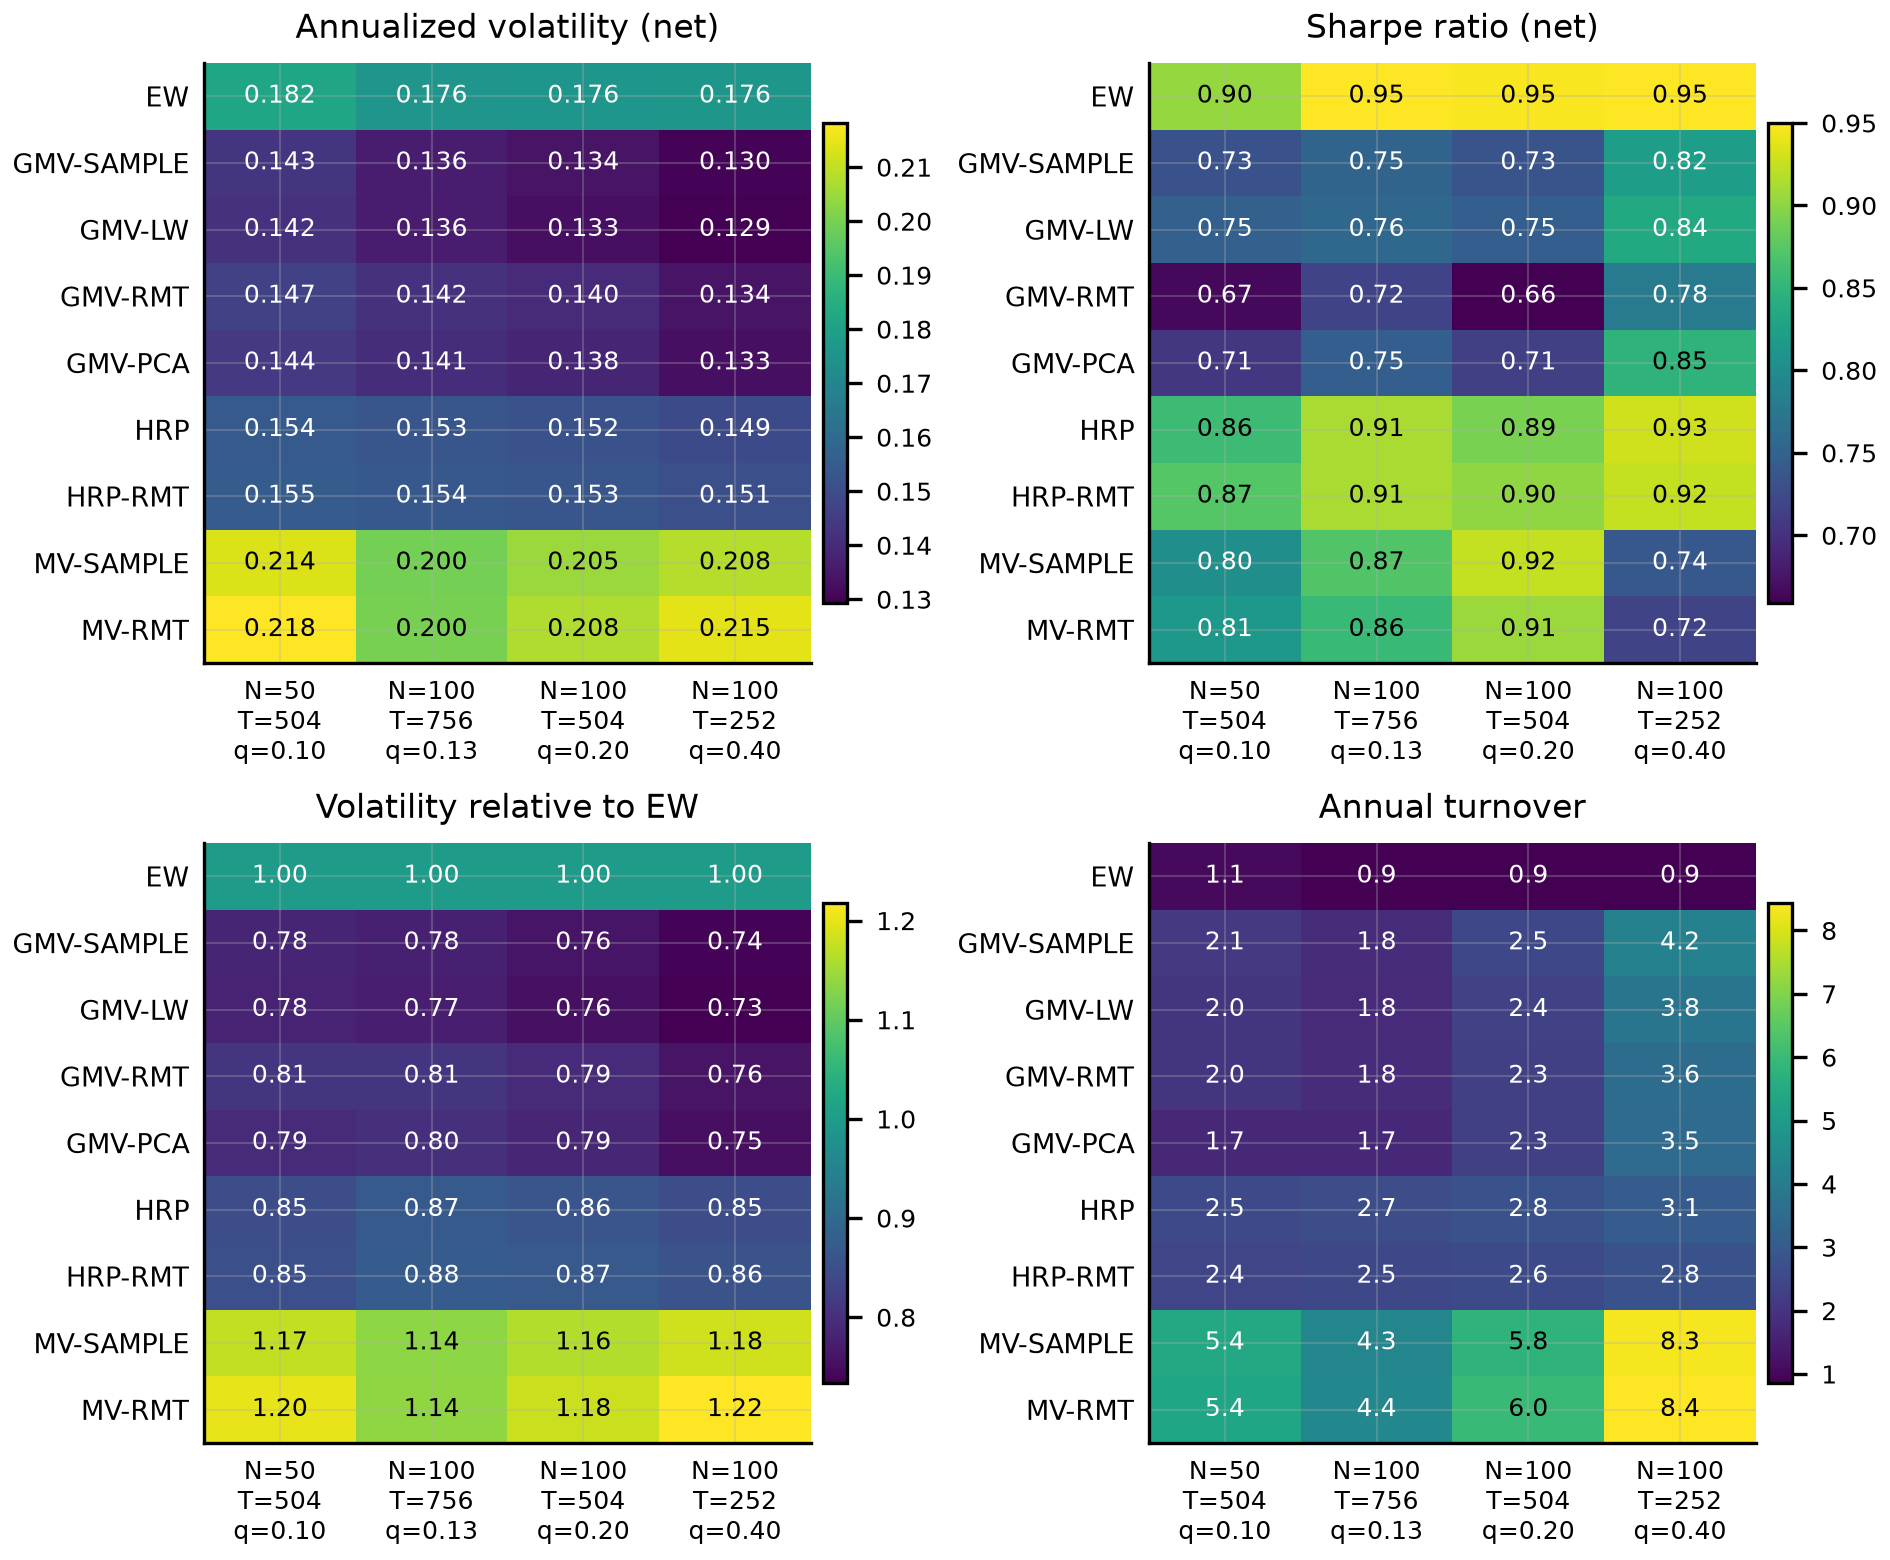

**figA08_sens_other.** Sensitivity to costs, cap, K and linkage.

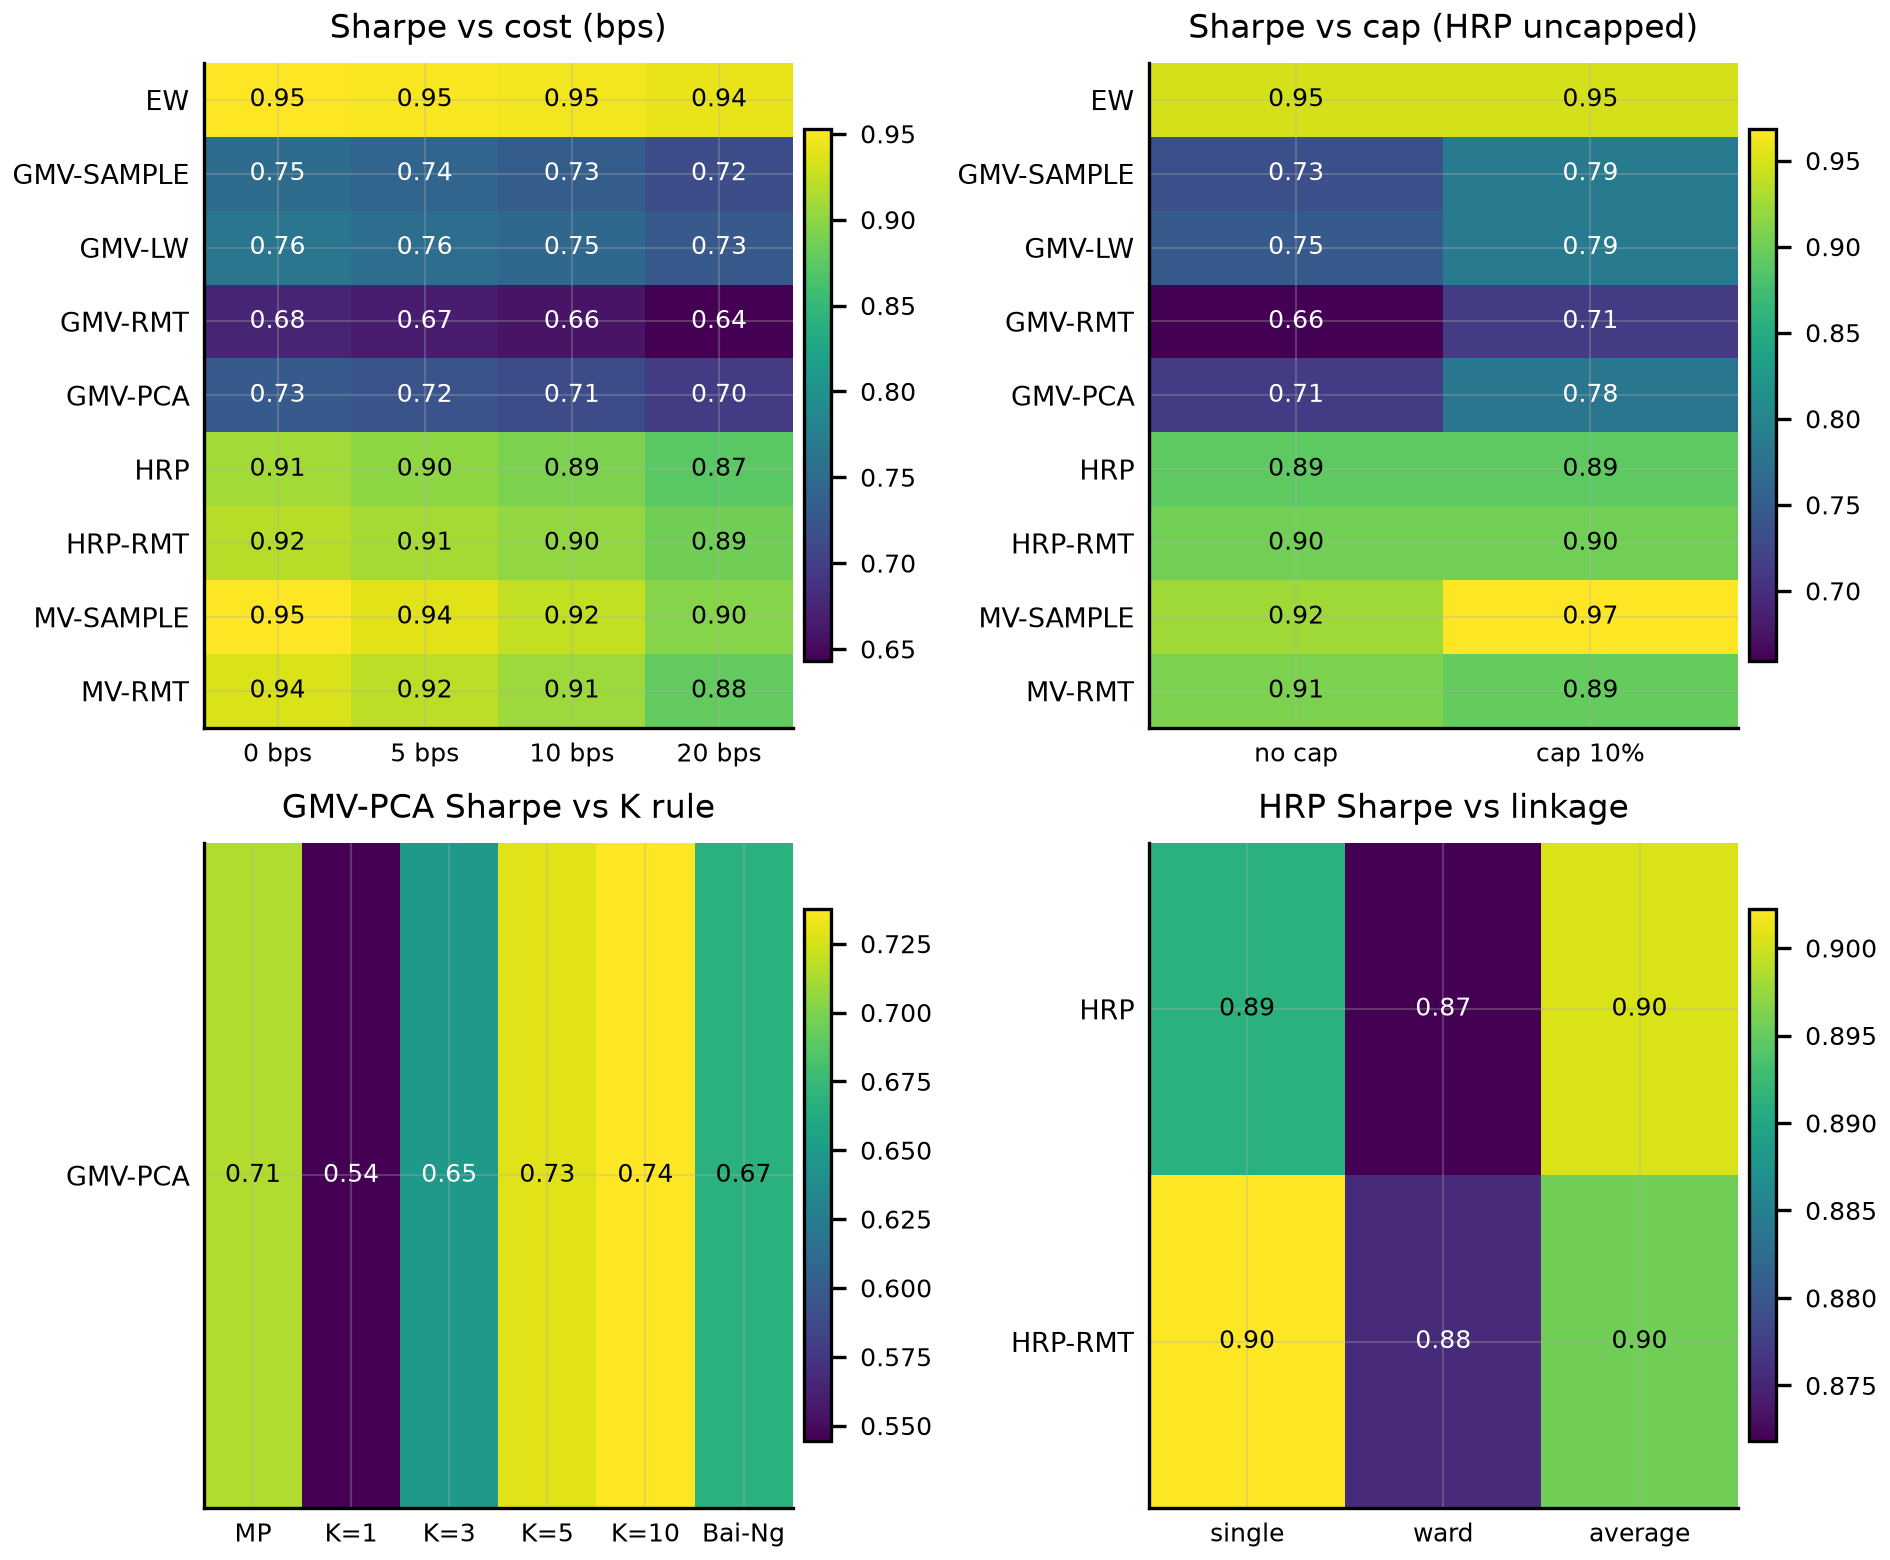

In [14]:
show_table("subperiods")
show_figure("subperiods")
show_table("sensitivity")
show_figure("sens_q")
show_figure("sens_other")

**tab06_h3_metrics.** Long-only and unconstrained GMV.

| strategy | constraint | ann_vol | sharpe | annual_turnover | mean_max_weight | mean_leverage | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | long-only | 0.130 | 0.744 | 2.397 | 0.207 | 1.000 | 1.187 |
| GMV-LW | long-only | 0.130 | 0.758 | 2.262 | 0.177 | 1.000 | 1.185 |
| GMV-RMT | long-only | 0.136 | 0.663 | 2.195 | 0.202 | 1.000 | 1.226 |
| GMV-PCA | long-only | 0.135 | 0.721 | 2.175 | 0.178 | 1.000 | 1.319 |
| GMV-SAMPLE-UNC | unconstrained | 0.134 | 0.702 | 12.061 | 0.190 | 3.663 | 1.551 |
| GMV-LW-UNC | unconstrained | 0.130 | 0.757 | 9.498 | 0.149 | 3.146 | 1.455 |
| GMV-RMT-UNC | unconstrained | 0.140 | 0.532 | 6.700 | 0.161 | 2.723 | 1.552 |
| GMV-PCA-UNC | unconstrained | 0.146 | 0.551 | 6.289 | 0.128 | 2.670 | 1.989 |


**tab07_h3_tests.** Hypothesis H3 bootstrap test.

| name | gap_a | gap_b | estimate | ci_low | ci_high | p_value | significant |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Ledoit-Wolf | -0.068 | -0.012 | -0.055 | -0.080 | -0.033 | 4.0e-04 | yes |
| RMT | 0.090 | 0.087 | 0.003 | -0.050 | 0.049 | 0.952 | no |
| PCA | 0.168 | 0.066 | 0.103 | 0.054 | 0.161 | 4.0e-04 | yes |


**fig11_h3.** Long-only against unconstrained GMV (hypothesis H3).

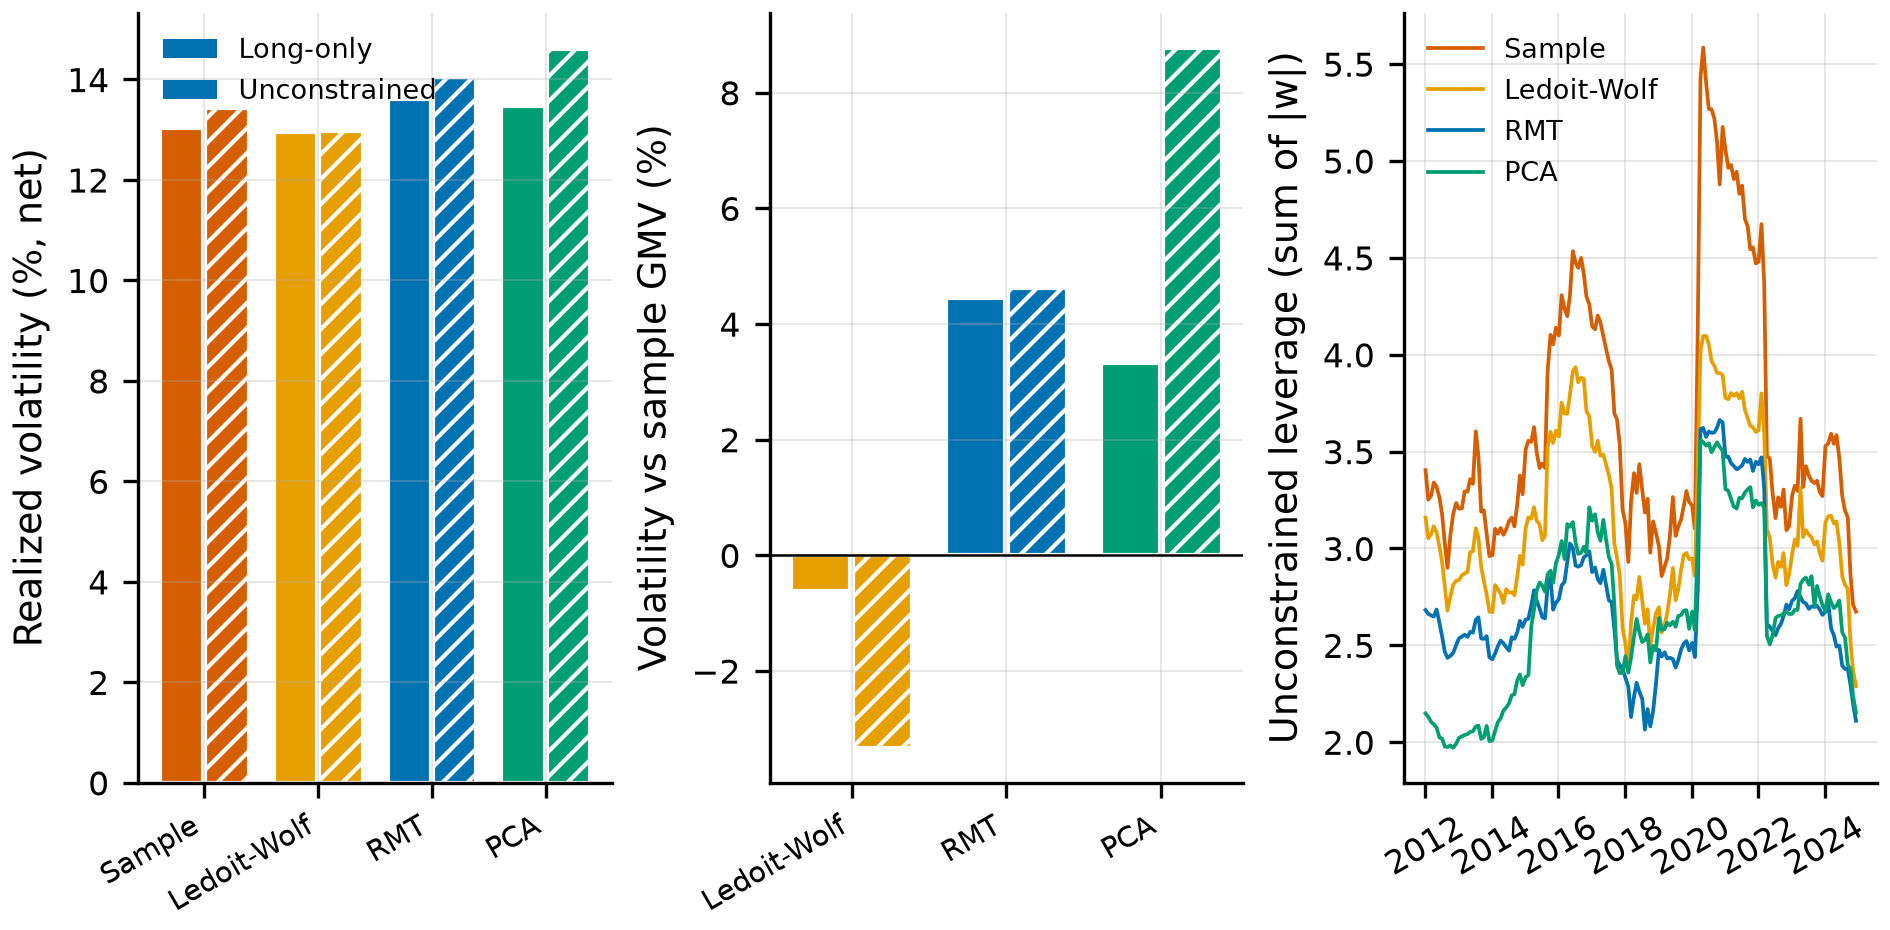

In [15]:
show_table("h3_metrics")
show_table("h3_tests")
show_figure("h3")

**figA09_struct_weights.** Pooled weight distributions.

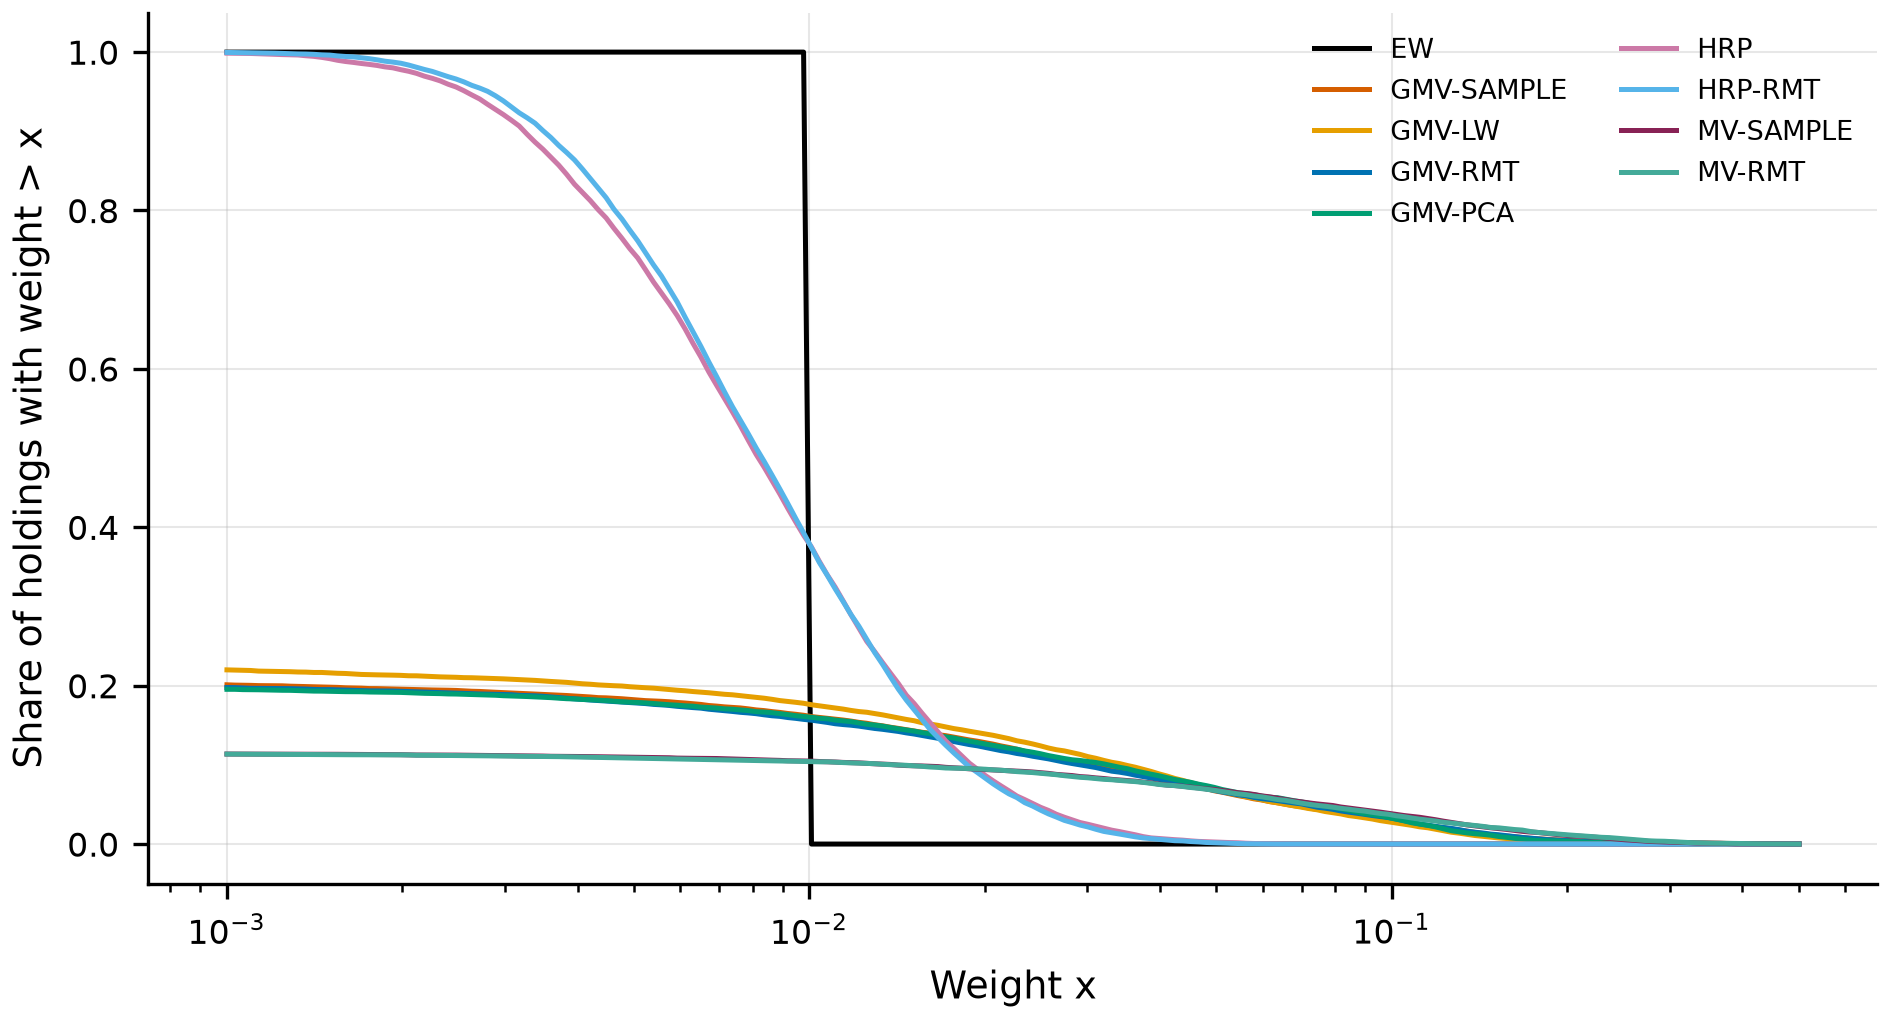

**figA10_struct_dynamics.** Weight dynamics.

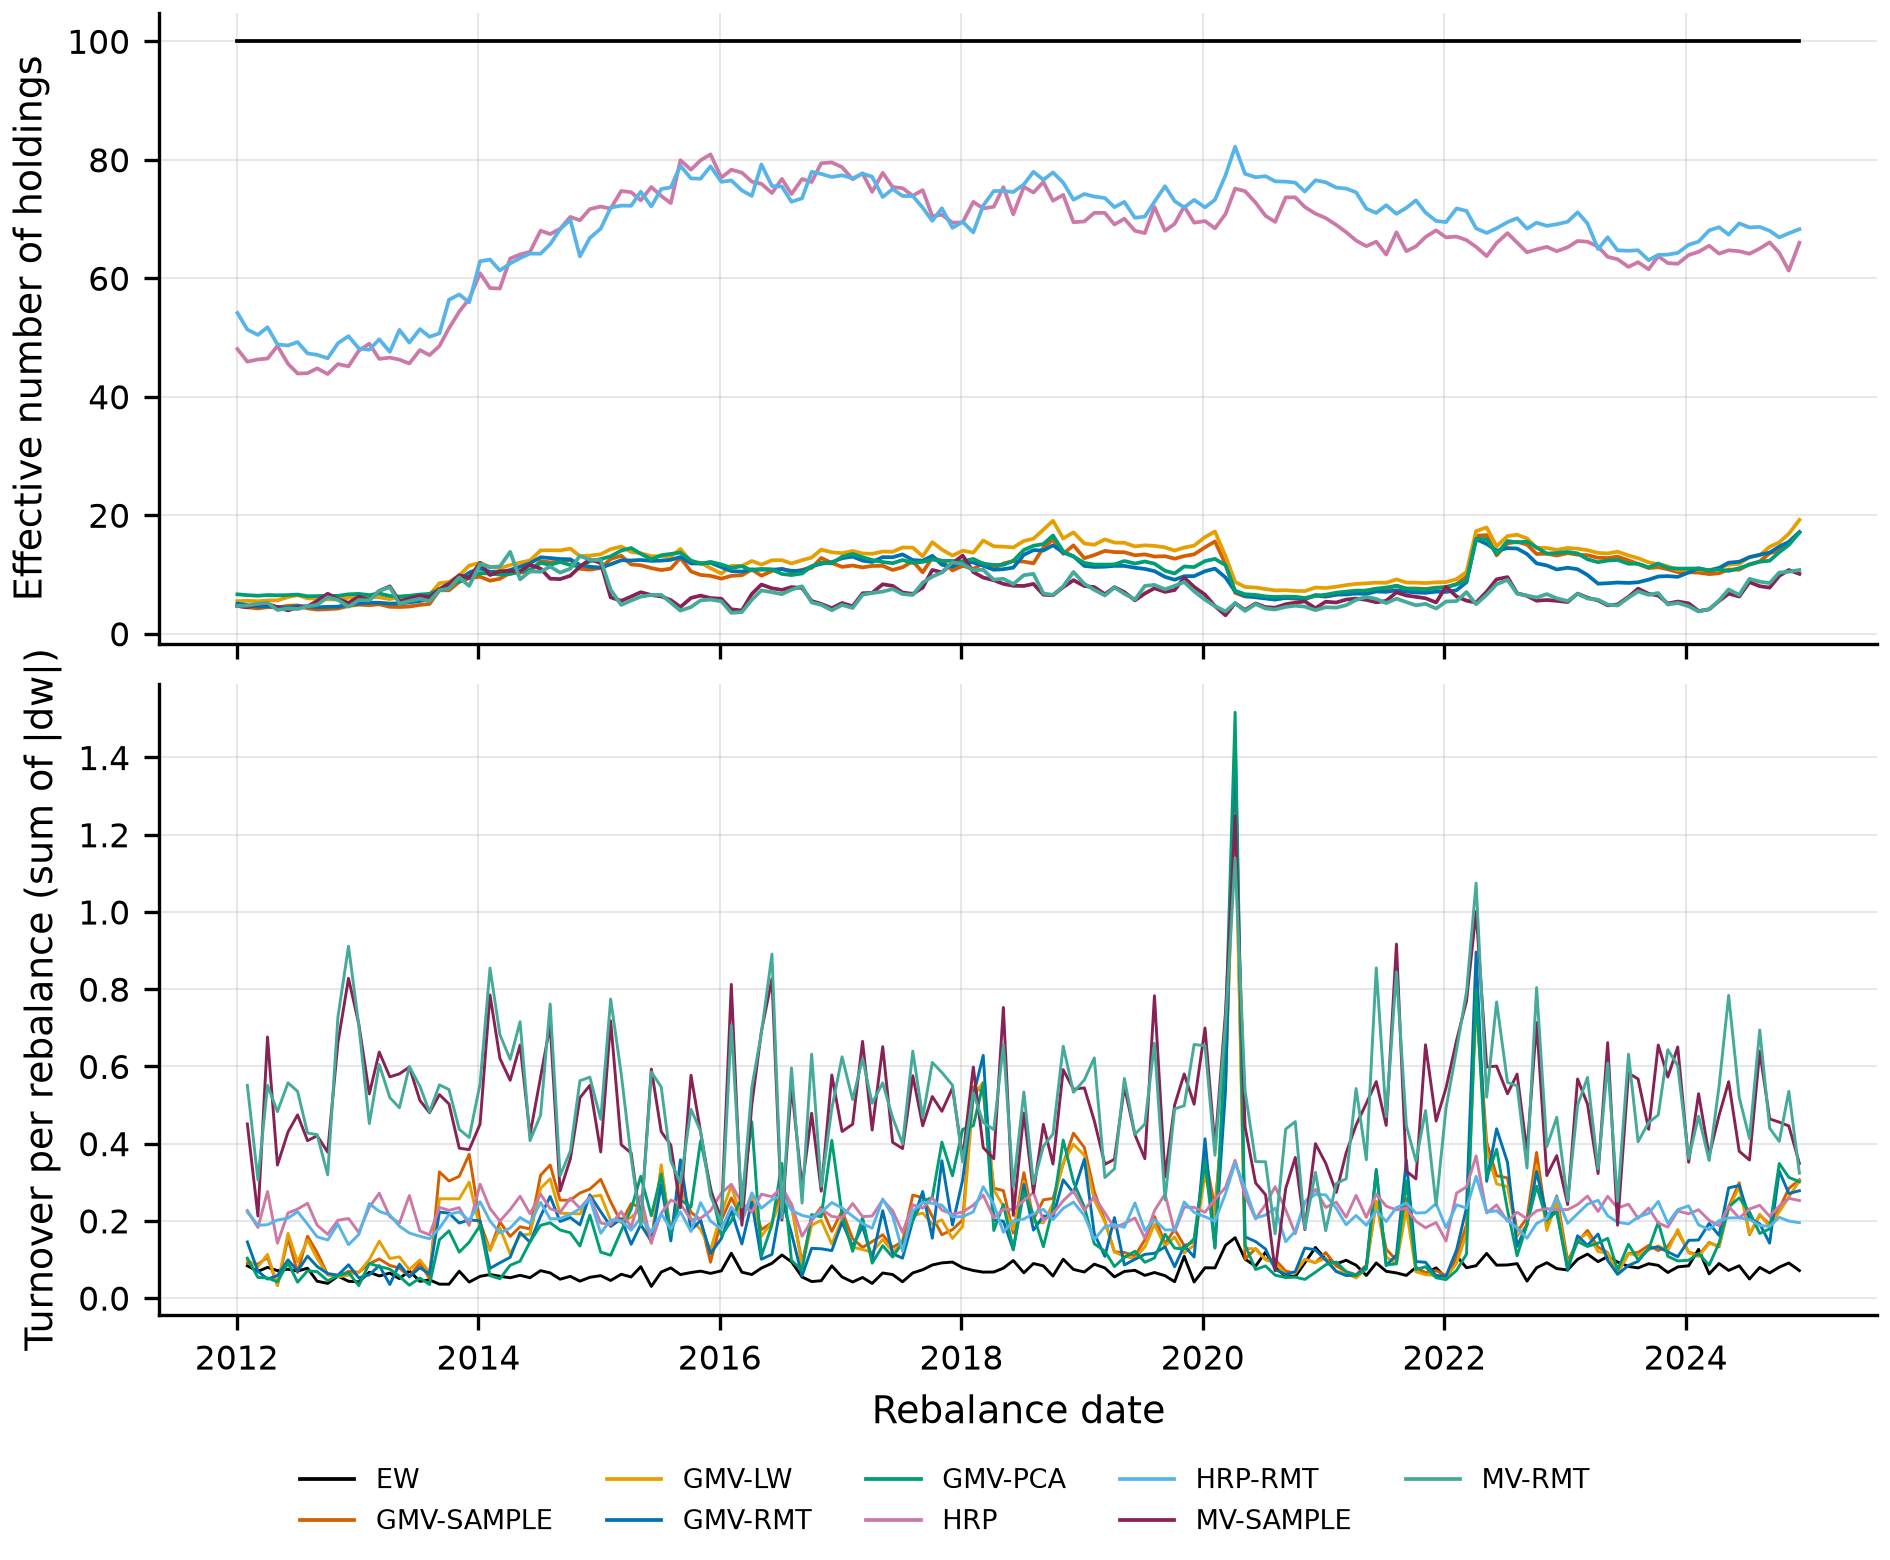

**figA11_struct_sectors.** Sector exposure.

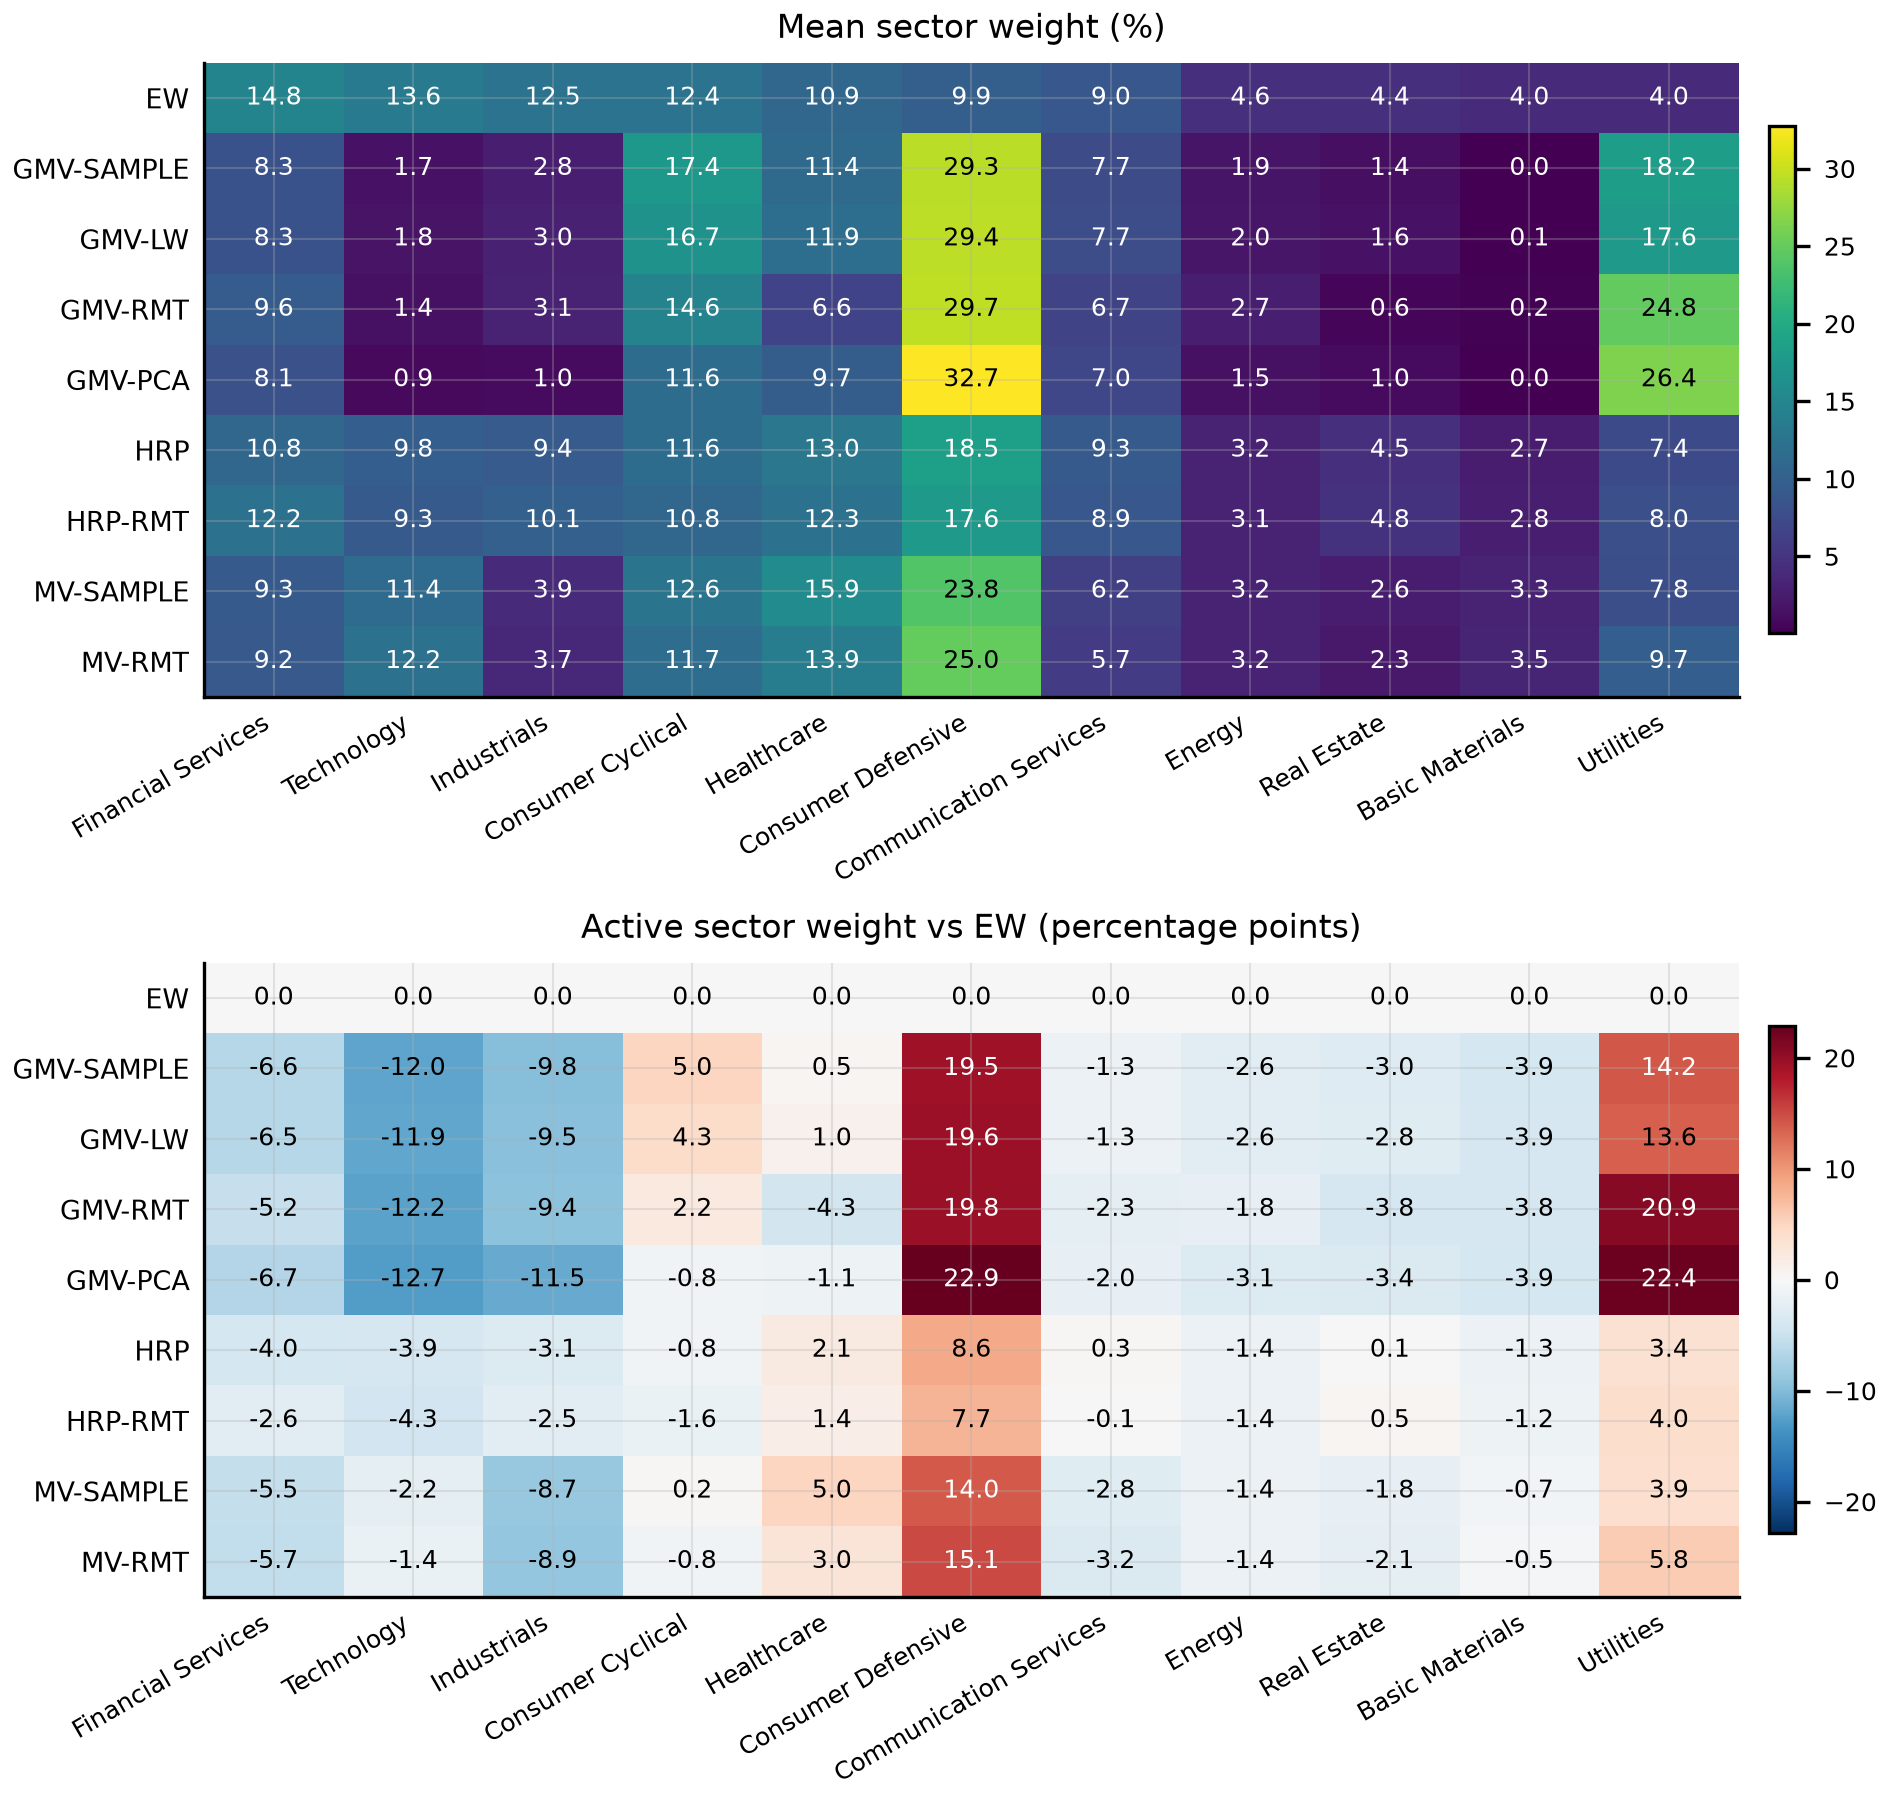

**figA12_struct_eigen.** Spectrum diagnostics and performance.

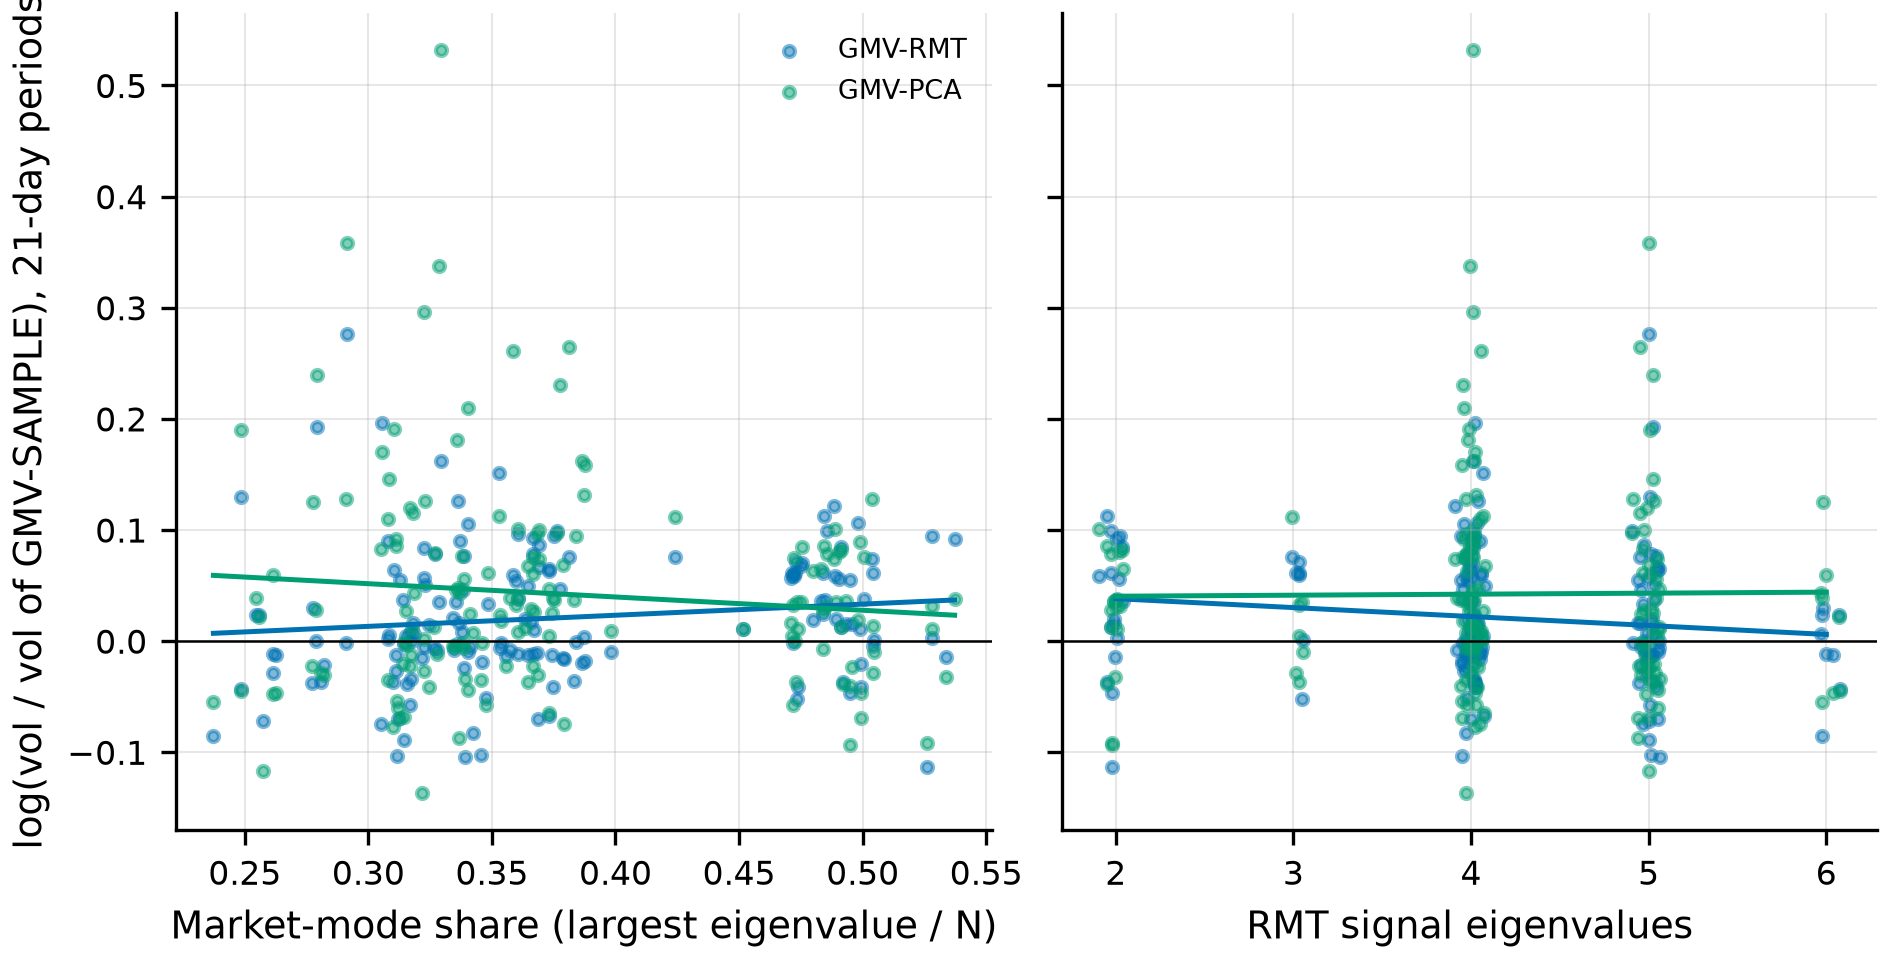

In [16]:
show_figure("struct_weights")
show_figure("struct_dynamics")
show_figure("struct_sectors")
show_figure("struct_eigen")

**Simulation with a known truth.** On real data the true covariance is unknown, so the estimators are also compared in a factor-model simulation where it is known. This separates 'the estimator is worse' from 'the data are different'.

**fig12_simulation.** Simulation study, Gaussian returns.

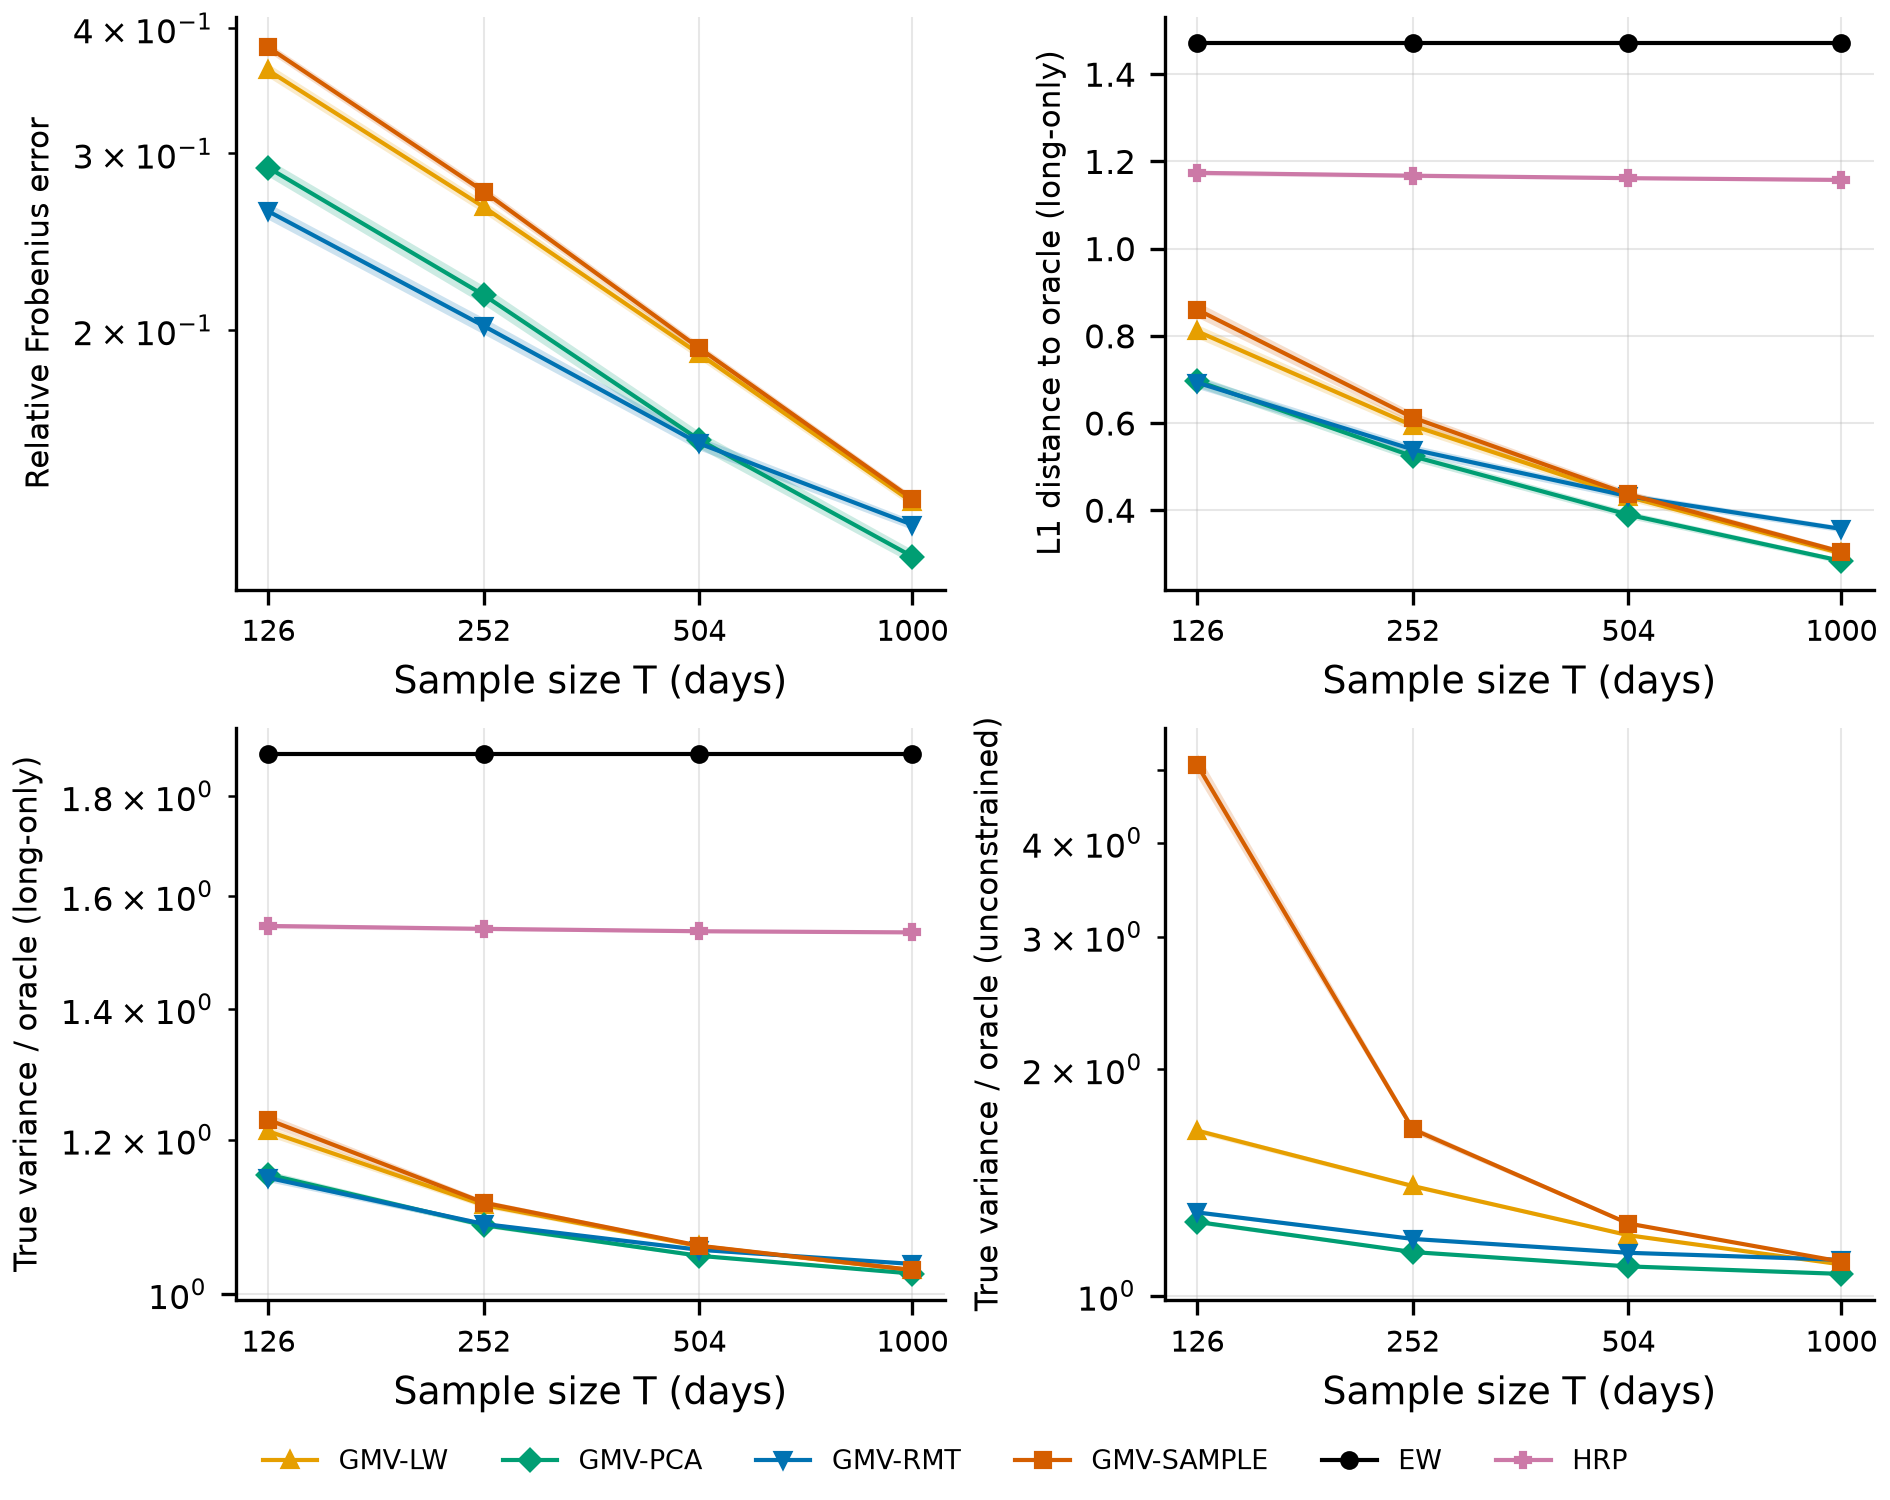

**figA13_simulation_t.** Simulation study, Student-t returns.

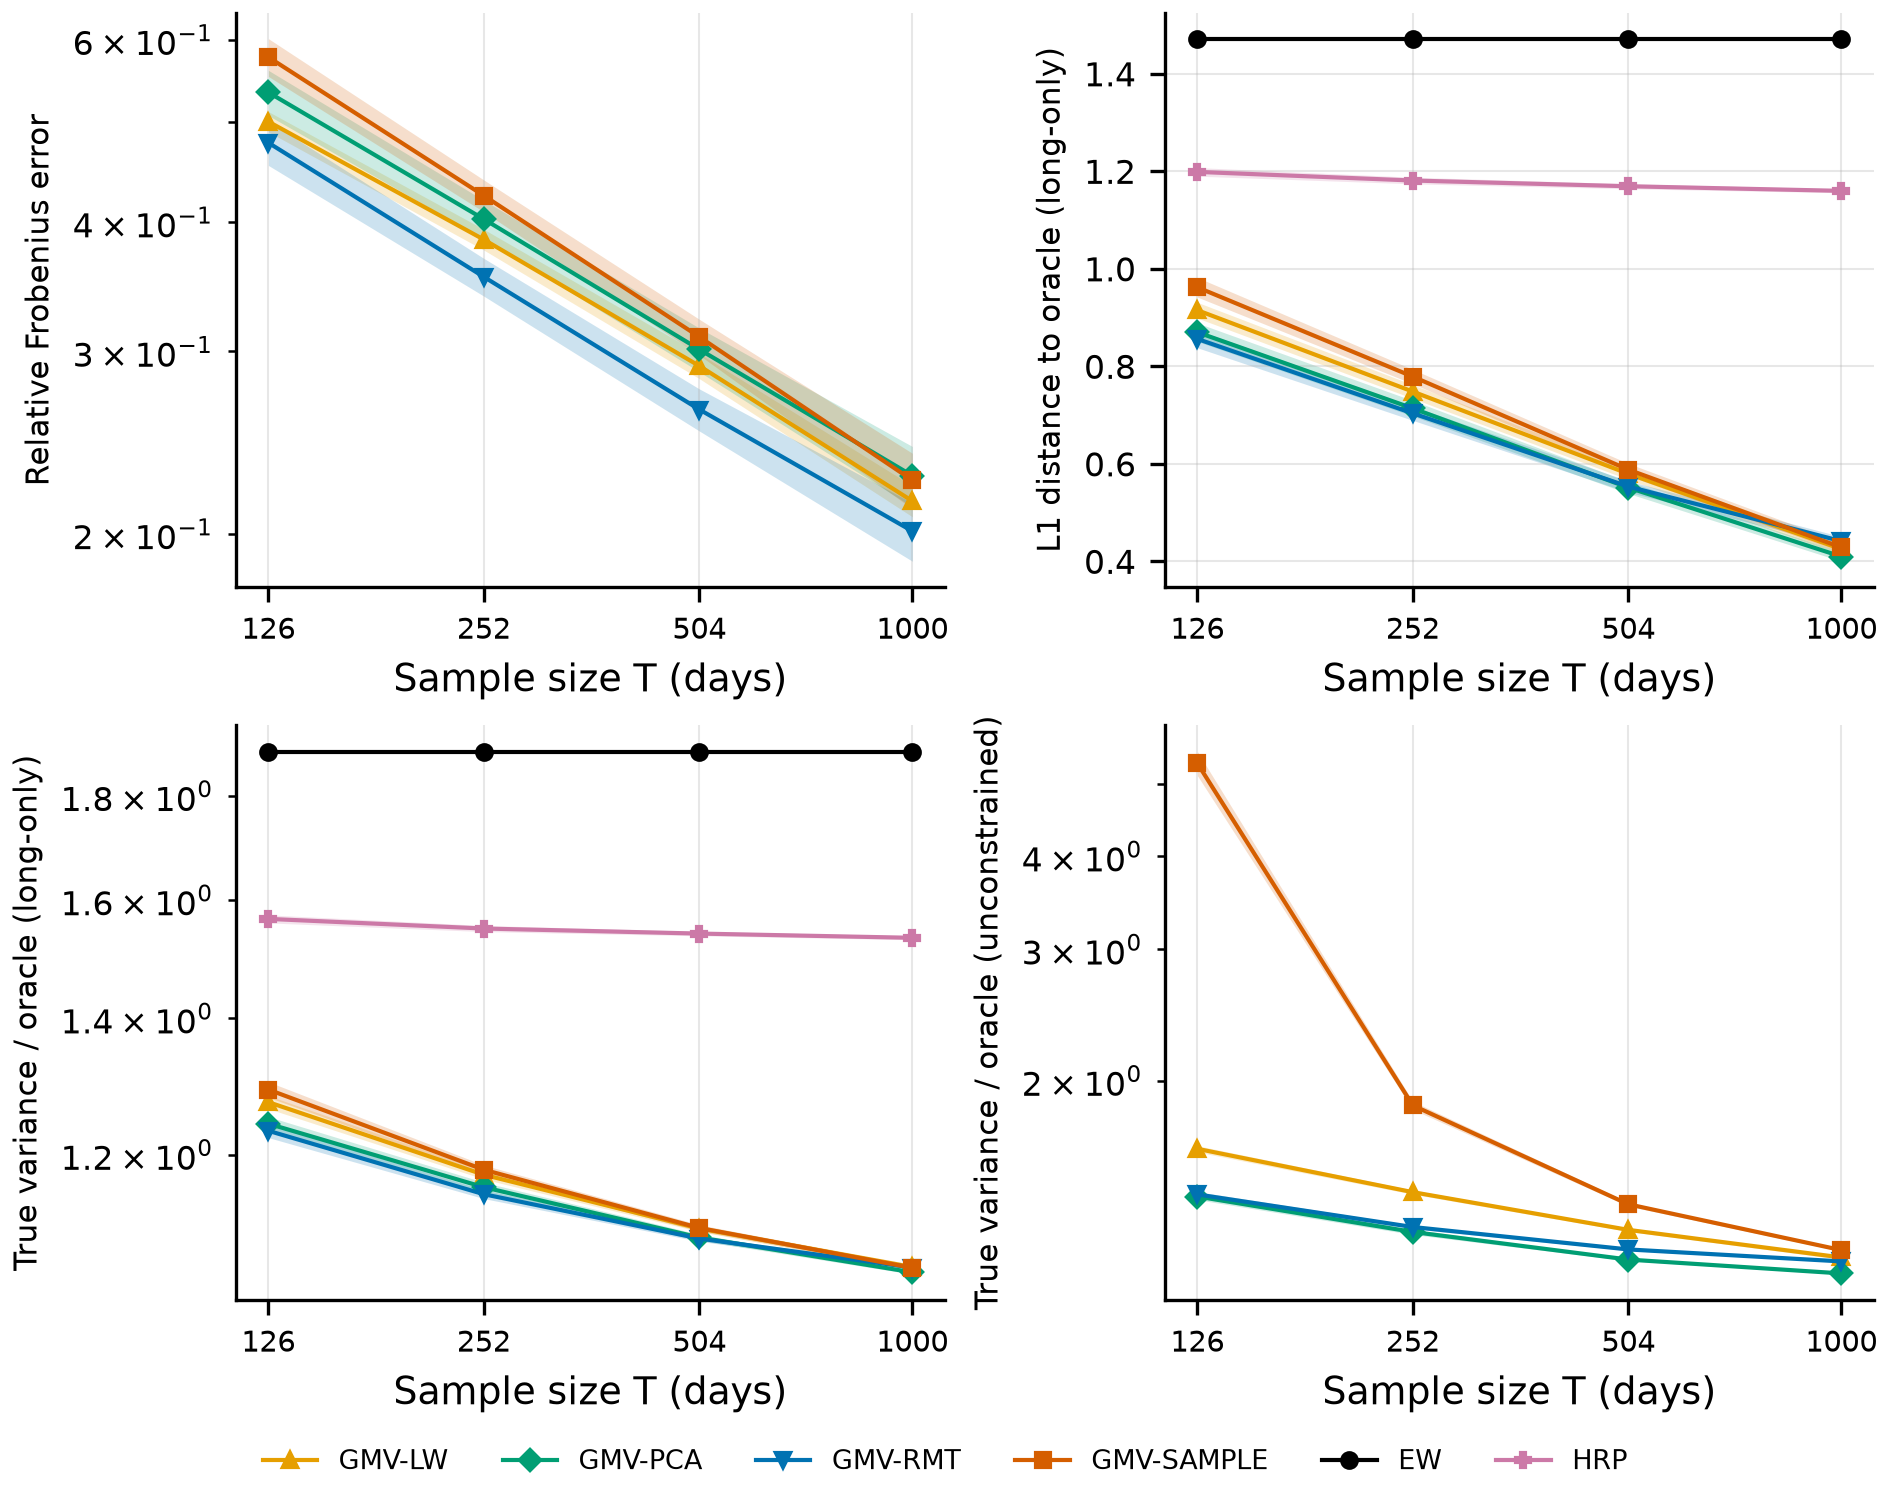

**tabA04_simulation_paired.** Simulation: paired comparison against the sample covariance.

| distribution | T | constraint | method | mean_log_ratio | ci_low | ci_high | beats_sample |
| --- | --- | --- | --- | --- | --- | --- | --- |
| gaussian | 126.000 | long-only | EW | 0.434 | 0.427 | 0.440 | 0.000 |
| gaussian | 126.000 | long-only | GMV-LW | -0.013 | -0.016 | -0.011 | 0.755 |
| gaussian | 126.000 | long-only | GMV-PCA | -0.064 | -0.069 | -0.059 | 0.990 |
| gaussian | 126.000 | long-only | GMV-RMT | -0.068 | -0.073 | -0.063 | 0.990 |
| gaussian | 126.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 126.000 | long-only | HRP | 0.230 | 0.223 | 0.237 | 0.000 |
| gaussian | 126.000 | unconstrained | GMV-LW | -1.090 | -1.124 | -1.057 | 1.000 |
| gaussian | 126.000 | unconstrained | GMV-PCA | -1.369 | -1.404 | -1.334 | 1.000 |
| gaussian | 126.000 | unconstrained | GMV-RMT | -1.339 | -1.374 | -1.305 | 1.000 |
| gaussian | 126.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 252.000 | long-only | EW | 0.530 | 0.527 | 0.534 | 0.000 |
| gaussian | 252.000 | long-only | GMV-LW | -0.003 | -0.004 | -0.002 | 0.630 |
| gaussian | 252.000 | long-only | GMV-PCA | -0.026 | -0.029 | -0.024 | 0.945 |
| gaussian | 252.000 | long-only | GMV-RMT | -0.025 | -0.028 | -0.022 | 0.890 |
| gaussian | 252.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 252.000 | long-only | HRP | 0.323 | 0.320 | 0.327 | 0.000 |
| gaussian | 252.000 | unconstrained | GMV-LW | -0.172 | -0.179 | -0.166 | 1.000 |
| gaussian | 252.000 | unconstrained | GMV-PCA | -0.373 | -0.384 | -0.363 | 1.000 |
| gaussian | 252.000 | unconstrained | GMV-RMT | -0.333 | -0.344 | -0.323 | 1.000 |
| gaussian | 252.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 504.000 | long-only | EW | 0.581 | 0.579 | 0.583 | 0.000 |
| gaussian | 504.000 | long-only | GMV-LW | -4.3e-04 | -8.2e-04 | -4.1e-05 | 0.555 |
| gaussian | 504.000 | long-only | GMV-PCA | -0.012 | -0.013 | -0.011 | 0.895 |
| gaussian | 504.000 | long-only | GMV-RMT | -0.005 | -0.007 | -0.003 | 0.600 |
| gaussian | 504.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 504.000 | long-only | HRP | 0.371 | 0.369 | 0.374 | 0.000 |
| gaussian | 504.000 | unconstrained | GMV-LW | -0.036 | -0.037 | -0.034 | 1.000 |
| gaussian | 504.000 | unconstrained | GMV-PCA | -0.131 | -0.135 | -0.127 | 1.000 |
| gaussian | 504.000 | unconstrained | GMV-RMT | -0.089 | -0.093 | -0.085 | 1.000 |
| gaussian | 504.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 1000.000 | long-only | EW | 0.610 | 0.609 | 0.611 | 0.000 |
| gaussian | 1000.000 | long-only | GMV-LW | -1.4e-04 | -2.7e-04 | 1.2e-06 | 0.525 |
| gaussian | 1000.000 | long-only | GMV-PCA | -0.004 | -0.005 | -0.003 | 0.770 |
| gaussian | 1000.000 | long-only | GMV-RMT | 0.007 | 0.006 | 0.008 | 0.185 |
| gaussian | 1000.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| gaussian | 1000.000 | long-only | HRP | 0.399 | 0.397 | 0.400 | 0.000 |
| gaussian | 1000.000 | unconstrained | GMV-LW | -0.008 | -0.009 | -0.008 | 1.000 |
| gaussian | 1000.000 | unconstrained | GMV-PCA | -0.037 | -0.040 | -0.035 | 0.985 |
| gaussian | 1000.000 | unconstrained | GMV-RMT | 0.006 | 0.003 | 0.008 | 0.355 |
| gaussian | 1000.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 126.000 | long-only | EW | 0.384 | 0.375 | 0.393 | 0.000 |
| student_t | 126.000 | long-only | GMV-LW | -0.014 | -0.019 | -0.009 | 0.675 |
| student_t | 126.000 | long-only | GMV-PCA | -0.038 | -0.044 | -0.032 | 0.825 |
| student_t | 126.000 | long-only | GMV-RMT | -0.046 | -0.052 | -0.040 | 0.875 |
| student_t | 126.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 126.000 | long-only | HRP | 0.194 | 0.186 | 0.203 | 0.000 |
| student_t | 126.000 | unconstrained | GMV-LW | -1.160 | -1.195 | -1.124 | 1.000 |
| student_t | 126.000 | unconstrained | GMV-PCA | -1.307 | -1.344 | -1.271 | 1.000 |
| student_t | 126.000 | unconstrained | GMV-RMT | -1.300 | -1.336 | -1.265 | 1.000 |
| student_t | 126.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 252.000 | long-only | EW | 0.473 | 0.468 | 0.478 | 0.000 |
| student_t | 252.000 | long-only | GMV-LW | -0.006 | -0.008 | -0.003 | 0.625 |
| student_t | 252.000 | long-only | GMV-PCA | -0.020 | -0.024 | -0.016 | 0.770 |
| student_t | 252.000 | long-only | GMV-RMT | -0.028 | -0.031 | -0.024 | 0.875 |
| student_t | 252.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 252.000 | long-only | HRP | 0.273 | 0.268 | 0.278 | 0.000 |
| student_t | 252.000 | unconstrained | GMV-LW | -0.265 | -0.276 | -0.254 | 1.000 |
| student_t | 252.000 | unconstrained | GMV-PCA | -0.388 | -0.403 | -0.374 | 1.000 |
| student_t | 252.000 | unconstrained | GMV-RMT | -0.372 | -0.385 | -0.359 | 1.000 |
| student_t | 252.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 504.000 | long-only | EW | 0.539 | 0.535 | 0.542 | 0.000 |
| student_t | 504.000 | long-only | GMV-LW | -6.5e-04 | -0.002 | 7.1e-04 | 0.545 |
| student_t | 504.000 | long-only | GMV-PCA | -0.011 | -0.013 | -0.009 | 0.785 |
| student_t | 504.000 | long-only | GMV-RMT | -0.012 | -0.014 | -0.010 | 0.780 |
| student_t | 504.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 504.000 | long-only | HRP | 0.333 | 0.329 | 0.337 | 0.000 |
| student_t | 504.000 | unconstrained | GMV-LW | -0.079 | -0.083 | -0.075 | 0.990 |
| student_t | 504.000 | unconstrained | GMV-PCA | -0.170 | -0.176 | -0.164 | 1.000 |
| student_t | 504.000 | unconstrained | GMV-RMT | -0.139 | -0.144 | -0.133 | 1.000 |
| student_t | 504.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 1000.000 | long-only | EW | 0.584 | 0.581 | 0.586 | 0.000 |
| student_t | 1000.000 | long-only | GMV-LW | 8.5e-04 | -0.001 | 0.003 | 0.470 |
| student_t | 1000.000 | long-only | GMV-PCA | -0.005 | -0.006 | -0.004 | 0.705 |
| student_t | 1000.000 | long-only | GMV-RMT | 4.5e-04 | -0.001 | 0.002 | 0.445 |
| student_t | 1000.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |
| student_t | 1000.000 | long-only | HRP | 0.373 | 0.370 | 0.376 | 0.000 |
| student_t | 1000.000 | unconstrained | GMV-LW | -0.023 | -0.027 | -0.019 | 0.990 |
| student_t | 1000.000 | unconstrained | GMV-PCA | -0.072 | -0.075 | -0.068 | 1.000 |
| student_t | 1000.000 | unconstrained | GMV-RMT | -0.035 | -0.038 | -0.031 | 0.925 |
| student_t | 1000.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 |


**tabA05_simulation_detection.** Simulation: detected number of factors.

| distribution | T | rmt_n_signal | pca_K | lw_shrinkage |
| --- | --- | --- | --- | --- |
| gaussian | 126.000 | 1.895 | 1.895 | 0.159 |
| gaussian | 252.000 | 2.000 | 2.000 | 0.083 |
| gaussian | 504.000 | 2.000 | 2.000 | 0.043 |
| gaussian | 1000.000 | 2.000 | 2.000 | 0.022 |
| student_t | 126.000 | 3.205 | 3.205 | 0.302 |
| student_t | 252.000 | 3.520 | 3.520 | 0.180 |
| student_t | 504.000 | 3.695 | 3.695 | 0.106 |
| student_t | 1000.000 | 3.610 | 3.610 | 0.060 |


In [17]:
show_figure("simulation")
show_figure("simulation_t")
show_table("simulation_paired")
show_table("simulation_detection")

## 7. Alternative approaches and extensions

Each extension runs through the same engine, universe, dates, constraints and costs, with hyperparameters fixed a priori in `config.yaml`. They are reported separately from the core results.

### 7.1 Regularized weights (ridge, shrinkage toward 1/N, L1 bound, elastic net)

Applied to the sample-covariance GMV problem. A pure L1 penalty does nothing when the weights are already non-negative and sum to one, so the L1 and elastic-net versions allow shorting, without borrow costs, which flatters them.

In [18]:
show_table("regularized_metrics")
show_table("regularized_tests")

**tabA26_regularized_metrics.** Extension: ridge, shrinkage, L1-bounded and elastic-net weights, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_leverage | mean_effective_n | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-RIDGE-0.1 | 0.129 | 0.096 | 0.774 | -0.340 | 2.098 | 1.000 | 14.322 | 0.110 | 1.172 |
| GMV-RIDGE-1 | 0.131 | 0.107 | 0.840 | -0.346 | 1.524 | 1.000 | 30.615 | 0.117 | 1.120 |
| GMV-RIDGE-10 | 0.147 | 0.138 | 0.950 | -0.359 | 0.963 | 1.000 | 72.500 | 0.142 | 1.036 |
| GMV-SHRINK-0.25 | 0.134 | 0.113 | 0.864 | -0.344 | 1.995 | 1.000 | 16.800 | 0.120 | 1.117 |
| GMV-SHRINK-0.5 | 0.143 | 0.132 | 0.941 | -0.355 | 1.589 | 1.000 | 30.833 | 0.136 | 1.053 |
| GMV-SHRINK-0.75 | 0.157 | 0.152 | 0.980 | -0.365 | 1.187 | 1.000 | 62.898 | 0.155 | 1.008 |
| GMV-L1-1.25 | 0.127 | 0.082 | 0.684 | -0.336 | 3.397 | 1.250 | 9.864 | 0.102 | 1.253 |
| GMV-L1-1.5 | 0.126 | 0.081 | 0.683 | -0.331 | 4.228 | 1.500 | 9.021 | 0.097 | 1.295 |
| GMV-L1-2 | 0.125 | 0.091 | 0.759 | -0.331 | 6.114 | 2.000 | 7.391 | 0.092 | 1.367 |
| GMV-ENET-1.5-1 | 0.127 | 0.102 | 0.830 | -0.342 | 2.602 | 1.479 | 25.551 | 0.106 | 1.201 |
| EW | 0.174 | 0.170 | 0.993 | -0.376 | 0.869 | 1.000 | 100.000 |  |  |
| GMV-SAMPLE | 0.130 | 0.093 | 0.744 | -0.333 | 2.397 | 1.000 | 10.275 | 0.110 | 1.187 |
| GMV-LW | 0.130 | 0.094 | 0.758 | -0.335 | 2.262 | 1.000 | 11.888 | 0.109 | 1.185 |
| GMV-RMT | 0.136 | 0.084 | 0.663 | -0.362 | 2.195 | 1.000 | 10.008 | 0.111 | 1.226 |


**tabA27_regularized_tests.** Extension: studentized tests against GMV-SAMPLE and EW.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | GMV-RIDGE-0.1 | sharpe_diff | 0.030 | -0.019 | 0.078 | 0.234 | 1.000 | 0.067 |
| GMV-SAMPLE | GMV-RIDGE-0.1 | log_var_ratio | -0.015 | -0.032 | 0.002 | 0.102 | 0.406 | 0.019 |
| GMV-SAMPLE | GMV-RIDGE-1 | sharpe_diff | 0.096 | -0.055 | 0.246 | 0.211 | 1.000 | 0.209 |
| GMV-SAMPLE | GMV-RIDGE-1 | log_var_ratio | 0.016 | -0.035 | 0.067 | 0.551 | 0.551 | 0.061 |
| GMV-SAMPLE | GMV-RIDGE-10 | sharpe_diff | 0.205 | -0.070 | 0.481 | 0.136 | 1.000 | 0.386 |
| GMV-SAMPLE | GMV-RIDGE-10 | log_var_ratio | 0.245 | 0.115 | 0.375 | 2.0e-04 | 0.003 | 0.131 |
| GMV-SAMPLE | GMV-SHRINK-0.25 | sharpe_diff | 0.120 | 5.3e-04 | 0.239 | 0.049 | 0.632 | 0.167 |
| GMV-SAMPLE | GMV-SHRINK-0.25 | log_var_ratio | 0.053 | 0.017 | 0.090 | 0.008 | 0.053 | 0.043 |
| GMV-SAMPLE | GMV-SHRINK-0.5 | sharpe_diff | 0.197 | -0.025 | 0.419 | 0.077 | 0.929 | 0.311 |
| GMV-SAMPLE | GMV-SHRINK-0.5 | log_var_ratio | 0.184 | 0.090 | 0.278 | 2.0e-04 | 0.003 | 0.100 |
| GMV-SAMPLE | GMV-SHRINK-0.75 | sharpe_diff | 0.236 | -0.068 | 0.540 | 0.123 | 1.000 | 0.429 |
| GMV-SAMPLE | GMV-SHRINK-0.75 | log_var_ratio | 0.366 | 0.200 | 0.533 | 2.0e-04 | 0.003 | 0.165 |
| GMV-SAMPLE | GMV-L1-1.25 | sharpe_diff | -0.060 | -0.147 | 0.027 | 0.181 | 1.000 | 0.127 |
| GMV-SAMPLE | GMV-L1-1.25 | log_var_ratio | -0.046 | -0.072 | -0.019 | 6.0e-04 | 0.005 | 0.031 |
| GMV-SAMPLE | GMV-L1-1.5 | sharpe_diff | -0.061 | -0.200 | 0.077 | 0.395 | 1.000 | 0.200 |
| GMV-SAMPLE | GMV-L1-1.5 | log_var_ratio | -0.074 | -0.129 | -0.020 | 0.008 | 0.053 | 0.059 |
| GMV-SAMPLE | GMV-L1-2 | sharpe_diff | 0.014 | -0.188 | 0.216 | 0.890 | 1.000 | 0.289 |
| GMV-SAMPLE | GMV-L1-2 | log_var_ratio | -0.075 | -0.201 | 0.050 | 0.181 | 0.543 | 0.114 |
| GMV-SAMPLE | GMV-ENET-1.5-1 | sharpe_diff | 0.085 | -0.102 | 0.273 | 0.376 | 1.000 | 0.262 |
| GMV-SAMPLE | GMV-ENET-1.5-1 | log_var_ratio | -0.051 | -0.128 | 0.026 | 0.193 | 0.543 | 0.089 |
| GMV-SAMPLE | EW | sharpe_diff | 0.248 | -0.121 | 0.617 | 0.185 | 1.000 | 0.523 |
| GMV-SAMPLE | EW | log_var_ratio | 0.575 | 0.330 | 0.820 | 2.0e-04 | 0.003 | 0.225 |
| GMV-SAMPLE | GMV-LW | sharpe_diff | 0.014 | -0.010 | 0.038 | 0.237 | 1.000 | 0.033 |
| GMV-SAMPLE | GMV-LW | log_var_ratio | -0.012 | -0.019 | -0.005 | 6.0e-04 | 0.005 | 0.008 |
| GMV-SAMPLE | GMV-RMT | sharpe_diff | -0.081 | -0.173 | 0.011 | 0.088 | 0.972 | 0.133 |
| GMV-SAMPLE | GMV-RMT | log_var_ratio | 0.087 | -0.011 | 0.186 | 0.060 | 0.302 | 0.070 |
| EW | GMV-RIDGE-0.1 | sharpe_diff | -0.219 | -0.571 | 0.134 | 0.225 | 1.000 | 0.500 |
| EW | GMV-RIDGE-0.1 | log_var_ratio | -0.590 | -0.858 | -0.321 | 2.0e-04 | 0.003 | 0.228 |
| EW | GMV-RIDGE-1 | sharpe_diff | -0.152 | -0.432 | 0.127 | 0.292 | 1.000 | 0.402 |
| EW | GMV-RIDGE-1 | log_var_ratio | -0.559 | -0.817 | -0.302 | 2.0e-04 | 0.003 | 0.203 |
| EW | GMV-RIDGE-10 | sharpe_diff | -0.043 | -0.183 | 0.097 | 0.549 | 1.000 | 0.197 |
| EW | GMV-RIDGE-10 | log_var_ratio | -0.330 | -0.460 | -0.200 | 2.0e-04 | 0.003 | 0.108 |
| EW | GMV-SHRINK-0.25 | sharpe_diff | -0.128 | -0.393 | 0.136 | 0.337 | 1.000 | 0.369 |
| EW | GMV-SHRINK-0.25 | log_var_ratio | -0.522 | -0.751 | -0.293 | 2.0e-04 | 0.003 | 0.193 |
| EW | GMV-SHRINK-0.5 | sharpe_diff | -0.051 | -0.214 | 0.111 | 0.526 | 1.000 | 0.226 |
| EW | GMV-SHRINK-0.5 | log_var_ratio | -0.391 | -0.556 | -0.226 | 2.0e-04 | 0.003 | 0.133 |
| EW | GMV-SHRINK-0.75 | sharpe_diff | -0.012 | -0.087 | 0.063 | 0.734 | 1.000 | 0.103 |
| EW | GMV-SHRINK-0.75 | log_var_ratio | -0.209 | -0.288 | -0.129 | 2.0e-04 | 0.003 | 0.064 |
| EW | GMV-L1-1.25 | sharpe_diff | -0.308 | -0.704 | 0.087 | 0.128 | 1.000 | 0.567 |
| EW | GMV-L1-1.25 | log_var_ratio | -0.621 | -0.821 | -0.420 | 2.0e-04 | 0.003 | 0.205 |
| EW | GMV-L1-1.5 | sharpe_diff | -0.310 | -0.728 | 0.109 | 0.144 | 1.000 | 0.598 |
| EW | GMV-L1-1.5 | log_var_ratio | -0.650 | -0.814 | -0.485 | 2.0e-04 | 0.003 | 0.185 |
| EW | GMV-L1-2 | sharpe_diff | -0.234 | -0.686 | 0.218 | 0.313 | 1.000 | 0.645 |
| EW | GMV-L1-2 | log_var_ratio | -0.650 | -0.767 | -0.534 | 2.0e-04 | 0.003 | 0.147 |
| EW | GMV-ENET-1.5-1 | sharpe_diff | -0.163 | -0.513 | 0.187 | 0.363 | 1.000 | 0.500 |
| EW | GMV-ENET-1.5-1 | log_var_ratio | -0.626 | -0.815 | -0.437 | 2.0e-04 | 0.003 | 0.183 |
| EW | GMV-SAMPLE | sharpe_diff | -0.248 | -0.617 | 0.121 | 0.185 | 1.000 | 0.523 |
| EW | GMV-SAMPLE | log_var_ratio | -0.575 | -0.820 | -0.330 | 2.0e-04 | 0.003 | 0.225 |
| EW | GMV-LW | sharpe_diff | -0.234 | -0.596 | 0.127 | 0.200 | 1.000 | 0.513 |
| EW | GMV-LW | log_var_ratio | -0.587 | -0.842 | -0.333 | 2.0e-04 | 0.003 | 0.226 |
| EW | GMV-RMT | sharpe_diff | -0.329 | -0.715 | 0.057 | 0.092 | 1.000 | 0.548 |
| EW | GMV-RMT | log_var_ratio | -0.488 | -0.846 | -0.130 | 0.012 | 0.012 | 0.286 |


### 7.2 Risk-based allocations (inverse volatility, equal risk contribution)

These need no expected returns and do not minimize variance directly, so they test whether the denoising result is specific to the minimum-variance optimizer.

In [19]:
show_table("riskbased_metrics")
show_table("riskbased_tests")

**tabA24_riskbased_metrics.** Extension: inverse-volatility and ERC portfolios, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- |
| IVOL | 0.163 | 0.153 | 0.954 | -0.372 | 0.826 | 0.163 | 0.998 |
| ERC-SAMPLE | 0.157 | 0.152 | 0.980 | -0.364 | 0.886 | 0.156 | 1.006 |
| ERC-LW | 0.157 | 0.152 | 0.980 | -0.364 | 0.885 | 0.154 | 1.024 |
| ERC-RMT | 0.158 | 0.151 | 0.970 | -0.366 | 0.876 | 0.157 | 1.004 |
| ERC-PCA | 0.156 | 0.151 | 0.977 | -0.364 | 0.897 | 0.155 | 1.007 |
| EW | 0.174 | 0.170 | 0.993 | -0.376 | 0.869 |  |  |
| GMV-SAMPLE | 0.130 | 0.093 | 0.744 | -0.333 | 2.397 | 0.110 | 1.187 |


**tabA25_riskbased_tests.** Extension: studentized tests against ERC-SAMPLE and IVOL.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ERC-SAMPLE | IVOL | sharpe_diff | -0.026 | -0.062 | 0.011 | 0.173 | 0.692 | 0.051 |
| ERC-SAMPLE | IVOL | log_var_ratio | 0.070 | 0.058 | 0.082 | 2.0e-04 | 0.001 | 0.015 |
| ERC-SAMPLE | ERC-LW | sharpe_diff | 3.5e-05 | -4.6e-04 | 5.3e-04 | 0.885 | 1.000 | 7.0e-04 |
| ERC-SAMPLE | ERC-LW | log_var_ratio | 8.5e-04 | 4.9e-04 | 0.001 | 2.0e-04 | 0.001 | 3.4e-04 |
| ERC-SAMPLE | ERC-RMT | sharpe_diff | -0.010 | -0.020 | 2.8e-04 | 0.056 | 0.338 | 0.014 |
| ERC-SAMPLE | ERC-RMT | log_var_ratio | 0.011 | 0.007 | 0.015 | 2.0e-04 | 0.001 | 0.005 |
| ERC-SAMPLE | ERC-PCA | sharpe_diff | -0.003 | -0.009 | 0.004 | 0.420 | 1.000 | 0.010 |
| ERC-SAMPLE | ERC-PCA | log_var_ratio | -0.010 | -0.016 | -0.004 | 0.003 | 0.003 | 0.005 |
| ERC-SAMPLE | EW | sharpe_diff | 0.013 | -0.062 | 0.087 | 0.725 | 1.000 | 0.103 |
| ERC-SAMPLE | EW | log_var_ratio | 0.200 | 0.114 | 0.287 | 2.0e-04 | 0.001 | 0.065 |
| ERC-SAMPLE | GMV-SAMPLE | sharpe_diff | -0.236 | -0.549 | 0.078 | 0.131 | 0.657 | 0.440 |
| ERC-SAMPLE | GMV-SAMPLE | log_var_ratio | -0.375 | -0.536 | -0.213 | 2.0e-04 | 0.001 | 0.166 |
| IVOL | ERC-SAMPLE | sharpe_diff | 0.026 | -0.011 | 0.062 | 0.173 | 0.895 | 0.051 |
| IVOL | ERC-SAMPLE | log_var_ratio | -0.070 | -0.082 | -0.058 | 2.0e-04 | 0.001 | 0.015 |
| IVOL | ERC-LW | sharpe_diff | 0.026 | -0.011 | 0.062 | 0.168 | 0.895 | 0.051 |
| IVOL | ERC-LW | log_var_ratio | -0.069 | -0.081 | -0.058 | 2.0e-04 | 0.001 | 0.015 |
| IVOL | ERC-RMT | sharpe_diff | 0.016 | -0.016 | 0.048 | 0.337 | 0.895 | 0.045 |
| IVOL | ERC-RMT | log_var_ratio | -0.059 | -0.074 | -0.044 | 2.0e-04 | 0.001 | 0.017 |
| IVOL | ERC-PCA | sharpe_diff | 0.023 | -0.018 | 0.063 | 0.266 | 0.895 | 0.056 |
| IVOL | ERC-PCA | log_var_ratio | -0.080 | -0.097 | -0.063 | 2.0e-04 | 0.001 | 0.019 |
| IVOL | EW | sharpe_diff | 0.038 | -0.014 | 0.090 | 0.149 | 0.895 | 0.074 |
| IVOL | EW | log_var_ratio | 0.130 | 0.057 | 0.204 | 0.009 | 0.009 | 0.053 |
| IVOL | GMV-SAMPLE | sharpe_diff | -0.210 | -0.547 | 0.127 | 0.213 | 0.895 | 0.473 |
| IVOL | GMV-SAMPLE | log_var_ratio | -0.445 | -0.618 | -0.272 | 2.0e-04 | 0.001 | 0.179 |


### 7.3 Machine-learning return forecasts

Ridge and a random forest predict the cross-sectional rank of the next 21-day return from momentum, 1-month return, volatility and dollar volume. Training uses an expanding window, a scheduled refit and a purge so that no training label reaches past the refit date. The signal is judged first by its out-of-sample rank information coefficient (IC); a pre-set gate (mean IC above zero with t-statistic of at least 2) decides whether it may feed the optimizer. The portfolios below are shown for completeness whether or not the gate is passed; the IC table states the verdict. The forecast enters the optimizer as a centered rank score, so these portfolios bet on the ranking only.

In [20]:
show_table("ml_signal_ic")
show_table("ml_metrics")
show_table("ml_tests")

**tabA28_ml_signal_ic.** Extension: out-of-sample rank IC of the ML signals and the single features.

| predictor | mean_ic | std_ic | t_stat | hit_rate | n_dates |
| --- | --- | --- | --- | --- | --- |
| RIDGE | 0.025 | 0.226 | 1.250 | 0.557 | 131 |
| RF | 0.029 | 0.192 | 1.703 | 0.542 | 131 |
| mom_12_1 | -0.011 | 0.240 | -0.523 | 0.519 | 131 |
| ret_1m | -0.026 | 0.203 | -1.493 | 0.435 | 131 |
| vol | 0.027 | 0.245 | 1.279 | 0.542 | 131 |
| dollar_volume | 0.011 | 0.138 | 0.897 | 0.573 | 131 |


**tabA29_ml_metrics.** Extension: ML-fed max-Sharpe portfolios (IC gate failed, shown for completeness) and core references, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_effective_n | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| MV-ML-RIDGE-RMT | 0.245 | 0.114 | 0.562 | -0.477 | 18.590 | 5.197 | 0.192 | 1.277 |
| MV-ML-RF-RMT | 0.260 | 0.097 | 0.489 | -0.489 | 16.548 | 4.723 | 0.207 | 1.257 |
| EW | 0.180 | 0.149 | 0.863 | -0.376 | 0.901 | 100.000 |  |  |
| GMV-SAMPLE | 0.137 | 0.092 | 0.715 | -0.333 | 2.549 | 11.203 | 0.112 | 1.223 |
| GMV-RMT | 0.143 | 0.084 | 0.638 | -0.362 | 2.373 | 10.817 | 0.113 | 1.265 |
| MV-SAMPLE | 0.210 | 0.174 | 0.872 | -0.380 | 5.764 | 7.085 | 0.180 | 1.167 |
| MV-RMT | 0.213 | 0.174 | 0.858 | -0.383 | 5.970 | 7.034 | 0.185 | 1.148 |


**tabA30_ml_tests.** Extension: studentized tests against MV-RMT, GMV-RMT and EW.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| MV-RMT | MV-ML-RIDGE-RMT | sharpe_diff | -0.296 | -0.927 | 0.334 | 0.360 | 1.000 | 0.894 |
| MV-RMT | MV-ML-RIDGE-RMT | log_var_ratio | 0.283 | 0.050 | 0.516 | 0.021 | 0.021 | 0.292 |
| MV-RMT | MV-ML-RF-RMT | sharpe_diff | -0.370 | -0.943 | 0.204 | 0.196 | 1.000 | 0.796 |
| MV-RMT | MV-ML-RF-RMT | log_var_ratio | 0.398 | 0.215 | 0.580 | 2.0e-04 | 0.001 | 0.236 |
| MV-RMT | EW | sharpe_diff | 0.004 | -0.558 | 0.567 | 0.988 | 1.000 | 0.792 |
| MV-RMT | EW | log_var_ratio | -0.334 | -0.566 | -0.103 | 0.005 | 0.014 | 0.287 |
| MV-RMT | GMV-SAMPLE | sharpe_diff | -0.144 | -0.676 | 0.389 | 0.607 | 1.000 | 0.746 |
| MV-RMT | GMV-SAMPLE | log_var_ratio | -0.887 | -1.290 | -0.483 | 2.0e-04 | 0.001 | 0.358 |
| MV-RMT | GMV-RMT | sharpe_diff | -0.220 | -0.748 | 0.308 | 0.434 | 1.000 | 0.764 |
| MV-RMT | GMV-RMT | log_var_ratio | -0.798 | -1.295 | -0.301 | 0.002 | 0.010 | 0.396 |
| MV-RMT | MV-SAMPLE | sharpe_diff | 0.013 | -0.067 | 0.094 | 0.754 | 1.000 | 0.115 |
| MV-RMT | MV-SAMPLE | log_var_ratio | -0.030 | -0.049 | -0.010 | 0.005 | 0.014 | 0.027 |
| GMV-RMT | MV-ML-RIDGE-RMT | sharpe_diff | -0.076 | -0.572 | 0.420 | 0.759 | 1.000 | 0.702 |
| GMV-RMT | MV-ML-RIDGE-RMT | log_var_ratio | 1.081 | 0.817 | 1.345 | 2.0e-04 | 0.001 | 0.271 |
| GMV-RMT | MV-ML-RF-RMT | sharpe_diff | -0.150 | -0.683 | 0.384 | 0.572 | 1.000 | 0.750 |
| GMV-RMT | MV-ML-RF-RMT | log_var_ratio | 1.195 | 0.882 | 1.509 | 2.0e-04 | 0.001 | 0.299 |
| GMV-RMT | EW | sharpe_diff | 0.225 | -0.194 | 0.644 | 0.284 | 1.000 | 0.590 |
| GMV-RMT | EW | log_var_ratio | 0.464 | 0.175 | 0.753 | 0.003 | 0.010 | 0.234 |
| GMV-RMT | GMV-SAMPLE | sharpe_diff | 0.077 | -0.036 | 0.189 | 0.173 | 1.000 | 0.159 |
| GMV-RMT | GMV-SAMPLE | log_var_ratio | -0.089 | -0.187 | 0.009 | 0.059 | 0.059 | 0.066 |
| GMV-RMT | MV-SAMPLE | sharpe_diff | 0.234 | -0.302 | 0.770 | 0.404 | 1.000 | 0.765 |
| GMV-RMT | MV-SAMPLE | log_var_ratio | 0.768 | 0.253 | 1.283 | 0.006 | 0.012 | 0.406 |
| GMV-RMT | MV-RMT | sharpe_diff | 0.220 | -0.308 | 0.748 | 0.434 | 1.000 | 0.764 |
| GMV-RMT | MV-RMT | log_var_ratio | 0.798 | 0.301 | 1.295 | 0.002 | 0.010 | 0.396 |
| EW | MV-ML-RIDGE-RMT | sharpe_diff | -0.301 | -0.627 | 0.025 | 0.069 | 0.347 | 0.453 |
| EW | MV-ML-RIDGE-RMT | log_var_ratio | 0.617 | 0.537 | 0.698 | 2.0e-04 | 0.001 | 0.111 |
| EW | MV-ML-RF-RMT | sharpe_diff | -0.374 | -0.751 | 0.003 | 0.052 | 0.314 | 0.524 |
| EW | MV-ML-RF-RMT | log_var_ratio | 0.732 | 0.626 | 0.838 | 2.0e-04 | 0.001 | 0.144 |
| EW | GMV-SAMPLE | sharpe_diff | -0.148 | -0.550 | 0.253 | 0.461 | 1.000 | 0.561 |
| EW | GMV-SAMPLE | log_var_ratio | -0.553 | -0.739 | -0.366 | 2.0e-04 | 0.001 | 0.177 |
| EW | GMV-RMT | sharpe_diff | -0.225 | -0.644 | 0.194 | 0.284 | 1.000 | 0.590 |
| EW | GMV-RMT | log_var_ratio | -0.464 | -0.753 | -0.175 | 0.003 | 0.008 | 0.234 |
| EW | MV-SAMPLE | sharpe_diff | 0.009 | -0.551 | 0.569 | 0.977 | 1.000 | 0.791 |
| EW | MV-SAMPLE | log_var_ratio | 0.305 | 0.065 | 0.544 | 0.015 | 0.015 | 0.298 |
| EW | MV-RMT | sharpe_diff | -0.004 | -0.567 | 0.558 | 0.988 | 1.000 | 0.792 |
| EW | MV-RMT | log_var_ratio | 0.334 | 0.103 | 0.566 | 0.005 | 0.010 | 0.287 |


### 7.4 Other covariance ideas and diagnostics

- **Nonlinear shrinkage** (quadratic-inverse, Ledoit-Wolf 2022): shrinks eigenvalues individually instead of clipping at a threshold. Real-data and simulation results below.
- **Non-stationarity**: EWMA covariances at two half-lives, and a simulated positive control.
- **Residual structure**: is there sector structure left in the PCA residual, and does restoring it (sector blocks) help? A random-label placebo checks that any gain is specific to the true sectors.
- **Forecast loss**: covariance estimates scored by QLIKE as forecasters of the variance of random portfolios, separating forecast quality from the optimizer's use of the estimate.

In [21]:
show_table("nls_metrics")
show_table("nls_tests")
show_table("nls_simulation")

**tabA21_nls_metrics.** Extension: quadratic-inverse shrinkage GMV, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | 0.130 | 0.093 | 0.744 | -0.333 | 2.397 | 0.110 | 1.187 |
| GMV-LW | 0.130 | 0.094 | 0.758 | -0.335 | 2.262 | 0.109 | 1.185 |
| GMV-RMT | 0.136 | 0.084 | 0.663 | -0.362 | 2.195 | 0.111 | 1.226 |
| GMV-PCA | 0.135 | 0.092 | 0.721 | -0.343 | 2.175 | 0.102 | 1.319 |
| GMV-NLS | 0.130 | 0.093 | 0.751 | -0.336 | 2.185 | 0.110 | 1.185 |


**tabA22_nls_tests.** Extension: studentized tests of GMV-NLS against sample and RMT.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | GMV-LW | sharpe_diff | 0.014 | -0.010 | 0.038 | 0.237 | 0.712 | 0.033 |
| GMV-SAMPLE | GMV-LW | log_var_ratio | -0.012 | -0.019 | -0.005 | 6.0e-04 | 0.002 | 0.008 |
| GMV-SAMPLE | GMV-RMT | sharpe_diff | -0.081 | -0.173 | 0.011 | 0.088 | 0.354 | 0.133 |
| GMV-SAMPLE | GMV-RMT | log_var_ratio | 0.087 | -0.011 | 0.186 | 0.060 | 0.121 | 0.070 |
| GMV-SAMPLE | GMV-PCA | sharpe_diff | -0.023 | -0.137 | 0.091 | 0.685 | 1.000 | 0.166 |
| GMV-SAMPLE | GMV-PCA | log_var_ratio | 0.066 | 0.047 | 0.084 | 2.0e-04 | 8.0e-04 | 0.026 |
| GMV-SAMPLE | GMV-NLS | sharpe_diff | 0.007 | -0.025 | 0.038 | 0.667 | 1.000 | 0.045 |
| GMV-SAMPLE | GMV-NLS | log_var_ratio | -0.008 | -0.019 | 0.002 | 0.103 | 0.121 | 0.010 |
| GMV-RMT | GMV-SAMPLE | sharpe_diff | 0.081 | -0.011 | 0.173 | 0.088 | 0.196 | 0.133 |
| GMV-RMT | GMV-SAMPLE | log_var_ratio | -0.087 | -0.186 | 0.011 | 0.060 | 0.190 | 0.070 |
| GMV-RMT | GMV-LW | sharpe_diff | 0.095 | 7.5e-04 | 0.189 | 0.049 | 0.195 | 0.137 |
| GMV-RMT | GMV-LW | log_var_ratio | -0.099 | -0.197 | -0.002 | 0.047 | 0.190 | 0.070 |
| GMV-RMT | GMV-PCA | sharpe_diff | 0.058 | -0.036 | 0.151 | 0.233 | 0.233 | 0.136 |
| GMV-RMT | GMV-PCA | log_var_ratio | -0.022 | -0.093 | 0.049 | 0.395 | 0.395 | 0.062 |
| GMV-RMT | GMV-NLS | sharpe_diff | 0.088 | -0.005 | 0.180 | 0.065 | 0.196 | 0.134 |
| GMV-RMT | GMV-NLS | log_var_ratio | -0.096 | -0.189 | -0.002 | 0.048 | 0.190 | 0.066 |


**tabA23_nls_simulation.** Extension: simulation, true GMV variance against the sample covariance.

| distribution | T | constraint | method | mean_log_ratio | ci_low | ci_high | beats_sample | best_rate |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| stationary | 126.000 | long-only | GMV-LW | -0.013 | -0.016 | -0.011 | 0.755 | 0.020 |
| stationary | 126.000 | long-only | GMV-NLS | 0.002 | -0.003 | 0.007 | 0.480 | 0.005 |
| stationary | 126.000 | long-only | GMV-PCA | -0.064 | -0.069 | -0.059 | 0.990 | 0.350 |
| stationary | 126.000 | long-only | GMV-RMT | -0.068 | -0.073 | -0.063 | 0.990 | 0.625 |
| stationary | 126.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| stationary | 126.000 | unconstrained | GMV-LW | -1.090 | -1.124 | -1.057 | 1.000 | 0.000 |
| stationary | 126.000 | unconstrained | GMV-NLS | -1.178 | -1.212 | -1.144 | 1.000 | 0.005 |
| stationary | 126.000 | unconstrained | GMV-PCA | -1.369 | -1.404 | -1.334 | 1.000 | 0.940 |
| stationary | 126.000 | unconstrained | GMV-RMT | -1.339 | -1.374 | -1.305 | 1.000 | 0.055 |
| stationary | 126.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| stationary | 252.000 | long-only | GMV-LW | -0.003 | -0.004 | -0.002 | 0.630 | 0.035 |
| stationary | 252.000 | long-only | GMV-NLS | 0.013 | 0.011 | 0.015 | 0.185 | 0.005 |
| stationary | 252.000 | long-only | GMV-PCA | -0.026 | -0.029 | -0.024 | 0.945 | 0.485 |
| stationary | 252.000 | long-only | GMV-RMT | -0.025 | -0.028 | -0.022 | 0.890 | 0.450 |
| stationary | 252.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.025 |
| stationary | 252.000 | unconstrained | GMV-LW | -0.172 | -0.179 | -0.166 | 1.000 | 0.000 |
| stationary | 252.000 | unconstrained | GMV-NLS | -0.236 | -0.246 | -0.226 | 1.000 | 0.000 |
| stationary | 252.000 | unconstrained | GMV-PCA | -0.373 | -0.384 | -0.363 | 1.000 | 0.995 |
| stationary | 252.000 | unconstrained | GMV-RMT | -0.333 | -0.344 | -0.323 | 1.000 | 0.005 |
| stationary | 252.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| stationary | 504.000 | long-only | GMV-LW | -4.3e-04 | -8.2e-04 | -4.1e-05 | 0.555 | 0.065 |
| stationary | 504.000 | long-only | GMV-NLS | 0.008 | 0.007 | 0.009 | 0.160 | 0.015 |
| stationary | 504.000 | long-only | GMV-PCA | -0.012 | -0.013 | -0.011 | 0.895 | 0.740 |
| stationary | 504.000 | long-only | GMV-RMT | -0.005 | -0.007 | -0.003 | 0.600 | 0.125 |
| stationary | 504.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.055 |
| stationary | 504.000 | unconstrained | GMV-LW | -0.036 | -0.037 | -0.034 | 1.000 | 0.000 |
| stationary | 504.000 | unconstrained | GMV-NLS | -0.061 | -0.064 | -0.058 | 0.995 | 0.000 |
| stationary | 504.000 | unconstrained | GMV-PCA | -0.131 | -0.135 | -0.127 | 1.000 | 1.000 |
| stationary | 504.000 | unconstrained | GMV-RMT | -0.089 | -0.093 | -0.085 | 1.000 | 0.000 |
| stationary | 504.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| stationary | 1000.000 | long-only | GMV-LW | -1.4e-04 | -2.7e-04 | 1.2e-06 | 0.525 | 0.120 |
| stationary | 1000.000 | long-only | GMV-NLS | 0.002 | 0.002 | 0.003 | 0.220 | 0.040 |
| stationary | 1000.000 | long-only | GMV-PCA | -0.004 | -0.005 | -0.003 | 0.770 | 0.730 |
| stationary | 1000.000 | long-only | GMV-RMT | 0.007 | 0.006 | 0.008 | 0.185 | 0.015 |
| stationary | 1000.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.095 |
| stationary | 1000.000 | unconstrained | GMV-LW | -0.008 | -0.009 | -0.008 | 1.000 | 0.005 |
| stationary | 1000.000 | unconstrained | GMV-NLS | -0.017 | -0.019 | -0.016 | 0.990 | 0.055 |
| stationary | 1000.000 | unconstrained | GMV-PCA | -0.037 | -0.040 | -0.035 | 0.985 | 0.940 |
| stationary | 1000.000 | unconstrained | GMV-RMT | 0.006 | 0.003 | 0.008 | 0.355 | 0.000 |
| stationary | 1000.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| time-varying | 126.000 | long-only | GMV-LW | -0.013 | -0.021 | -0.005 | 0.625 | 0.050 |
| time-varying | 126.000 | long-only | GMV-NLS | 0.003 | -0.008 | 0.013 | 0.510 | 0.055 |
| time-varying | 126.000 | long-only | GMV-PCA | -0.072 | -0.079 | -0.064 | 0.905 | 0.415 |
| time-varying | 126.000 | long-only | GMV-RMT | -0.072 | -0.080 | -0.064 | 0.885 | 0.425 |
| time-varying | 126.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.055 |
| time-varying | 126.000 | unconstrained | GMV-LW | -1.041 | -1.080 | -1.001 | 0.995 | 0.010 |
| time-varying | 126.000 | unconstrained | GMV-NLS | -1.128 | -1.171 | -1.085 | 0.995 | 0.015 |
| time-varying | 126.000 | unconstrained | GMV-PCA | -1.302 | -1.344 | -1.260 | 1.000 | 0.690 |
| time-varying | 126.000 | unconstrained | GMV-RMT | -1.282 | -1.322 | -1.241 | 1.000 | 0.285 |
| time-varying | 126.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| time-varying | 252.000 | long-only | GMV-LW | -0.005 | -0.008 | -7.0e-04 | 0.580 | 0.135 |
| time-varying | 252.000 | long-only | GMV-NLS | 0.008 | 0.001 | 0.015 | 0.430 | 0.110 |
| time-varying | 252.000 | long-only | GMV-PCA | -0.032 | -0.038 | -0.026 | 0.780 | 0.325 |
| time-varying | 252.000 | long-only | GMV-RMT | -0.029 | -0.036 | -0.023 | 0.740 | 0.375 |
| time-varying | 252.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.055 |
| time-varying | 252.000 | unconstrained | GMV-LW | -0.163 | -0.175 | -0.151 | 0.965 | 0.010 |
| time-varying | 252.000 | unconstrained | GMV-NLS | -0.223 | -0.243 | -0.204 | 0.935 | 0.060 |
| time-varying | 252.000 | unconstrained | GMV-PCA | -0.352 | -0.371 | -0.332 | 0.990 | 0.815 |
| time-varying | 252.000 | unconstrained | GMV-RMT | -0.314 | -0.332 | -0.296 | 0.990 | 0.110 |
| time-varying | 252.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.005 |
| time-varying | 504.000 | long-only | GMV-LW | -0.004 | -0.006 | -0.002 | 0.665 | 0.150 |
| time-varying | 504.000 | long-only | GMV-NLS | 0.002 | -0.003 | 0.006 | 0.505 | 0.240 |
| time-varying | 504.000 | long-only | GMV-PCA | -0.008 | -0.011 | -0.004 | 0.595 | 0.270 |
| time-varying | 504.000 | long-only | GMV-RMT | -0.002 | -0.007 | 0.002 | 0.585 | 0.240 |
| time-varying | 504.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.100 |
| time-varying | 504.000 | unconstrained | GMV-LW | -0.038 | -0.043 | -0.033 | 0.905 | 0.030 |
| time-varying | 504.000 | unconstrained | GMV-NLS | -0.064 | -0.074 | -0.054 | 0.815 | 0.150 |
| time-varying | 504.000 | unconstrained | GMV-PCA | -0.123 | -0.135 | -0.112 | 0.935 | 0.745 |
| time-varying | 504.000 | unconstrained | GMV-RMT | -0.083 | -0.095 | -0.072 | 0.855 | 0.055 |
| time-varying | 504.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.020 |
| time-varying | 1000.000 | long-only | GMV-LW | -0.003 | -0.004 | -0.002 | 0.695 | 0.100 |
| time-varying | 1000.000 | long-only | GMV-NLS | -0.003 | -0.006 | -5.0e-04 | 0.585 | 0.365 |
| time-varying | 1000.000 | long-only | GMV-PCA | 7.4e-04 | -0.002 | 0.004 | 0.470 | 0.205 |
| time-varying | 1000.000 | long-only | GMV-RMT | 0.007 | 0.003 | 0.011 | 0.425 | 0.235 |
| time-varying | 1000.000 | long-only | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.095 |
| time-varying | 1000.000 | unconstrained | GMV-LW | -0.009 | -0.012 | -0.007 | 0.775 | 0.080 |
| time-varying | 1000.000 | unconstrained | GMV-NLS | -0.019 | -0.024 | -0.014 | 0.745 | 0.355 |
| time-varying | 1000.000 | unconstrained | GMV-PCA | -0.033 | -0.043 | -0.023 | 0.715 | 0.480 |
| time-varying | 1000.000 | unconstrained | GMV-RMT | 0.004 | -0.006 | 0.014 | 0.490 | 0.025 |
| time-varying | 1000.000 | unconstrained | GMV-SAMPLE | 0.000 | 0.000 | 0.000 | 0.000 | 0.060 |


In [22]:
show_table("nonstat_metrics")
show_table("nonstat_tests")
show_table("nonstat_calibration")
show_table("nonstat_control")

**tabA11_nonstat_metrics.** Extension: EWMA strategies against sample GMV, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | 0.130 | 0.093 | 0.744 | -0.333 | 2.397 | 0.110 | 1.187 |
| GMV-LW | 0.130 | 0.094 | 0.758 | -0.335 | 2.262 | 0.109 | 1.185 |
| GMV-RMT | 0.136 | 0.084 | 0.663 | -0.362 | 2.195 | 0.111 | 1.226 |
| GMV-PCA | 0.135 | 0.092 | 0.721 | -0.343 | 2.175 | 0.102 | 1.319 |
| GMV-EWMA126 | 0.125 | 0.101 | 0.828 | -0.295 | 3.490 | 0.106 | 1.183 |
| GMV-EWMA126-RMT | 0.130 | 0.090 | 0.732 | -0.312 | 3.141 | 0.107 | 1.214 |
| GMV-EWMA63 | 0.123 | 0.107 | 0.889 | -0.255 | 5.545 | 0.100 | 1.231 |
| GMV-EWMA63-RMT | 0.127 | 0.101 | 0.825 | -0.282 | 4.938 | 0.101 | 1.257 |


**tabA12_nonstat_tests.** Extension: studentized tests of the EWMA strategies.

| reference | strategy | test | estimate | ci_low | ci_high | p_value | p_holm | mde |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | GMV-LW | sharpe_diff | 0.014 | -0.010 | 0.038 | 0.237 | 0.949 | 0.033 |
| GMV-SAMPLE | GMV-LW | log_var_ratio | -0.012 | -0.019 | -0.005 | 6.0e-04 | 0.004 | 0.008 |
| GMV-SAMPLE | GMV-RMT | sharpe_diff | -0.081 | -0.173 | 0.011 | 0.088 | 0.619 | 0.133 |
| GMV-SAMPLE | GMV-RMT | log_var_ratio | 0.087 | -0.011 | 0.186 | 0.060 | 0.302 | 0.070 |
| GMV-SAMPLE | GMV-PCA | sharpe_diff | -0.023 | -0.137 | 0.091 | 0.685 | 1.000 | 0.166 |
| GMV-SAMPLE | GMV-PCA | log_var_ratio | 0.066 | 0.047 | 0.084 | 2.0e-04 | 0.001 | 0.026 |
| GMV-SAMPLE | GMV-EWMA126 | sharpe_diff | 0.083 | -0.028 | 0.195 | 0.142 | 0.798 | 0.153 |
| GMV-SAMPLE | GMV-EWMA126 | log_var_ratio | -0.078 | -0.275 | 0.118 | 0.176 | 0.704 | 0.109 |
| GMV-SAMPLE | GMV-EWMA126-RMT | sharpe_diff | -0.012 | -0.140 | 0.115 | 0.844 | 1.000 | 0.177 |
| GMV-SAMPLE | GMV-EWMA126-RMT | log_var_ratio | -0.010 | -0.032 | 0.013 | 0.417 | 0.704 | 0.030 |
| GMV-SAMPLE | GMV-EWMA63 | sharpe_diff | 0.144 | -0.045 | 0.333 | 0.133 | 0.798 | 0.255 |
| GMV-SAMPLE | GMV-EWMA63 | log_var_ratio | -0.112 | -0.475 | 0.251 | 0.215 | 0.704 | 0.186 |
| GMV-SAMPLE | GMV-EWMA63-RMT | sharpe_diff | 0.081 | -0.095 | 0.256 | 0.370 | 1.000 | 0.244 |
| GMV-SAMPLE | GMV-EWMA63-RMT | log_var_ratio | -0.057 | -0.171 | 0.057 | 0.211 | 0.704 | 0.098 |
| GMV-EWMA126 | GMV-SAMPLE | sharpe_diff | -0.083 | -0.195 | 0.028 | 0.142 | 0.709 | 0.153 |
| GMV-EWMA126 | GMV-SAMPLE | log_var_ratio | 0.078 | -0.118 | 0.275 | 0.176 | 0.704 | 0.109 |
| GMV-EWMA126 | GMV-LW | sharpe_diff | -0.069 | -0.183 | 0.044 | 0.226 | 0.709 | 0.153 |
| GMV-EWMA126 | GMV-LW | log_var_ratio | 0.066 | -0.145 | 0.277 | 0.217 | 0.704 | 0.109 |
| GMV-EWMA126 | GMV-RMT | sharpe_diff | -0.164 | -0.311 | -0.018 | 0.029 | 0.202 | 0.203 |
| GMV-EWMA126 | GMV-RMT | log_var_ratio | 0.166 | -0.281 | 0.612 | 0.118 | 0.632 | 0.176 |
| GMV-EWMA126 | GMV-PCA | sharpe_diff | -0.107 | -0.264 | 0.051 | 0.176 | 0.709 | 0.218 |
| GMV-EWMA126 | GMV-PCA | log_var_ratio | 0.144 | -0.018 | 0.306 | 0.070 | 0.491 | 0.119 |
| GMV-EWMA126 | GMV-EWMA126-RMT | sharpe_diff | -0.096 | -0.197 | 0.005 | 0.061 | 0.366 | 0.143 |
| GMV-EWMA126 | GMV-EWMA126-RMT | log_var_ratio | 0.069 | -0.076 | 0.214 | 0.221 | 0.704 | 0.096 |
| GMV-EWMA126 | GMV-EWMA63 | sharpe_diff | 0.061 | -0.033 | 0.155 | 0.196 | 0.709 | 0.126 |
| GMV-EWMA126 | GMV-EWMA63 | log_var_ratio | -0.034 | -0.163 | 0.096 | 0.321 | 0.704 | 0.078 |
| GMV-EWMA126 | GMV-EWMA63-RMT | sharpe_diff | -0.003 | -0.120 | 0.115 | 0.962 | 0.962 | 0.167 |
| GMV-EWMA126 | GMV-EWMA63-RMT | log_var_ratio | 0.021 | -0.005 | 0.048 | 0.105 | 0.632 | 0.034 |
| GMV-EWMA63 | GMV-SAMPLE | sharpe_diff | -0.144 | -0.333 | 0.045 | 0.133 | 0.616 | 0.255 |
| GMV-EWMA63 | GMV-SAMPLE | log_var_ratio | 0.112 | -0.251 | 0.475 | 0.215 | 1.000 | 0.186 |
| GMV-EWMA63 | GMV-LW | sharpe_diff | -0.130 | -0.320 | 0.059 | 0.171 | 0.616 | 0.252 |
| GMV-EWMA63 | GMV-LW | log_var_ratio | 0.100 | -0.287 | 0.486 | 0.247 | 1.000 | 0.186 |
| GMV-EWMA63 | GMV-RMT | sharpe_diff | -0.225 | -0.438 | -0.012 | 0.040 | 0.283 | 0.292 |
| GMV-EWMA63 | GMV-RMT | log_var_ratio | 0.199 | -0.434 | 0.833 | 0.156 | 0.942 | 0.252 |
| GMV-EWMA63 | GMV-PCA | sharpe_diff | -0.168 | -0.384 | 0.048 | 0.123 | 0.616 | 0.293 |
| GMV-EWMA63 | GMV-PCA | log_var_ratio | 0.177 | -0.155 | 0.510 | 0.135 | 0.942 | 0.195 |
| GMV-EWMA63 | GMV-EWMA126 | sharpe_diff | -0.061 | -0.155 | 0.033 | 0.196 | 0.616 | 0.126 |
| GMV-EWMA63 | GMV-EWMA126 | log_var_ratio | 0.034 | -0.096 | 0.163 | 0.321 | 1.000 | 0.078 |
| GMV-EWMA63 | GMV-EWMA126-RMT | sharpe_diff | -0.157 | -0.309 | -0.005 | 0.043 | 0.283 | 0.209 |
| GMV-EWMA63 | GMV-EWMA126-RMT | log_var_ratio | 0.102 | -0.251 | 0.456 | 0.268 | 1.000 | 0.172 |
| GMV-EWMA63 | GMV-EWMA63-RMT | sharpe_diff | -0.064 | -0.182 | 0.054 | 0.285 | 0.616 | 0.166 |
| GMV-EWMA63 | GMV-EWMA63-RMT | log_var_ratio | 0.055 | -0.084 | 0.194 | 0.295 | 1.000 | 0.097 |


**tabA13_nonstat_calibration.** Extension: market volatility dynamics, a priori against calibrated.

| parameter | a_priori | calibrated |
| --- | --- | --- |
| vol_log_sd | 0.400 | 0.437 |
| vol_persistence | 0.980 | 0.981 |


**tabA14_nonstat_control.** Extension: positive control, paired true-variance ratio against sample GMV.

| design | T | method | mean_log_ratio | ci_low | ci_high |
| --- | --- | --- | --- | --- | --- |
| stationary | 252.000 | GMV-EWMA126 | 0.011 | 0.008 | 0.014 |
| stationary | 252.000 | GMV-EWMA126-RMT | -0.022 | -0.026 | -0.017 |
| stationary | 252.000 | GMV-EWMA63 | 0.042 | 0.036 | 0.048 |
| stationary | 252.000 | GMV-EWMA63-RMT | 0.002 | -0.003 | 0.007 |
| stationary | 252.000 | GMV-PCA | -0.031 | -0.035 | -0.027 |
| stationary | 252.000 | GMV-RMT | -0.031 | -0.035 | -0.026 |
| stationary | 252.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |
| stationary | 504.000 | GMV-EWMA126 | 0.024 | 0.021 | 0.027 |
| stationary | 504.000 | GMV-EWMA126-RMT | 0.011 | 0.007 | 0.015 |
| stationary | 504.000 | GMV-EWMA63 | 0.074 | 0.069 | 0.080 |
| stationary | 504.000 | GMV-EWMA63-RMT | 0.043 | 0.038 | 0.049 |
| stationary | 504.000 | GMV-PCA | -0.011 | -0.013 | -0.009 |
| stationary | 504.000 | GMV-RMT | -0.003 | -0.006 | -7.0e-04 |
| stationary | 504.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |
| time-varying (a priori) | 252.000 | GMV-EWMA126 | -0.015 | -0.021 | -0.009 |
| time-varying (a priori) | 252.000 | GMV-EWMA126-RMT | -0.043 | -0.052 | -0.033 |
| time-varying (a priori) | 252.000 | GMV-EWMA63 | -0.008 | -0.019 | 0.003 |
| time-varying (a priori) | 252.000 | GMV-EWMA63-RMT | -0.047 | -0.059 | -0.035 |
| time-varying (a priori) | 252.000 | GMV-PCA | -0.030 | -0.038 | -0.023 |
| time-varying (a priori) | 252.000 | GMV-RMT | -0.023 | -0.031 | -0.015 |
| time-varying (a priori) | 252.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |
| time-varying (a priori) | 504.000 | GMV-EWMA126 | -0.033 | -0.042 | -0.024 |
| time-varying (a priori) | 504.000 | GMV-EWMA126-RMT | -0.051 | -0.061 | -0.041 |
| time-varying (a priori) | 504.000 | GMV-EWMA63 | -0.018 | -0.033 | -0.004 |
| time-varying (a priori) | 504.000 | GMV-EWMA63-RMT | -0.055 | -0.069 | -0.041 |
| time-varying (a priori) | 504.000 | GMV-PCA | -0.012 | -0.018 | -0.007 |
| time-varying (a priori) | 504.000 | GMV-RMT | -0.004 | -0.011 | 0.002 |
| time-varying (a priori) | 504.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |
| time-varying (calibrated) | 252.000 | GMV-EWMA126 | -0.017 | -0.023 | -0.010 |
| time-varying (calibrated) | 252.000 | GMV-EWMA126-RMT | -0.045 | -0.055 | -0.035 |
| time-varying (calibrated) | 252.000 | GMV-EWMA63 | -0.011 | -0.023 | 0.001 |
| time-varying (calibrated) | 252.000 | GMV-EWMA63-RMT | -0.051 | -0.064 | -0.038 |
| time-varying (calibrated) | 252.000 | GMV-PCA | -0.031 | -0.039 | -0.023 |
| time-varying (calibrated) | 252.000 | GMV-RMT | -0.024 | -0.033 | -0.016 |
| time-varying (calibrated) | 252.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |
| time-varying (calibrated) | 504.000 | GMV-EWMA126 | -0.035 | -0.045 | -0.025 |
| time-varying (calibrated) | 504.000 | GMV-EWMA126-RMT | -0.053 | -0.064 | -0.042 |
| time-varying (calibrated) | 504.000 | GMV-EWMA63 | -0.021 | -0.037 | -0.006 |
| time-varying (calibrated) | 504.000 | GMV-EWMA63-RMT | -0.059 | -0.074 | -0.044 |
| time-varying (calibrated) | 504.000 | GMV-PCA | -0.012 | -0.018 | -0.007 |
| time-varying (calibrated) | 504.000 | GMV-RMT | -0.004 | -0.011 | 0.003 |
| time-varying (calibrated) | 504.000 | GMV-SAMPLE | 0.000 | 0.000 | 0.000 |


**figA14_res_blocks.** Extension: mean residual correlation by sector pair.

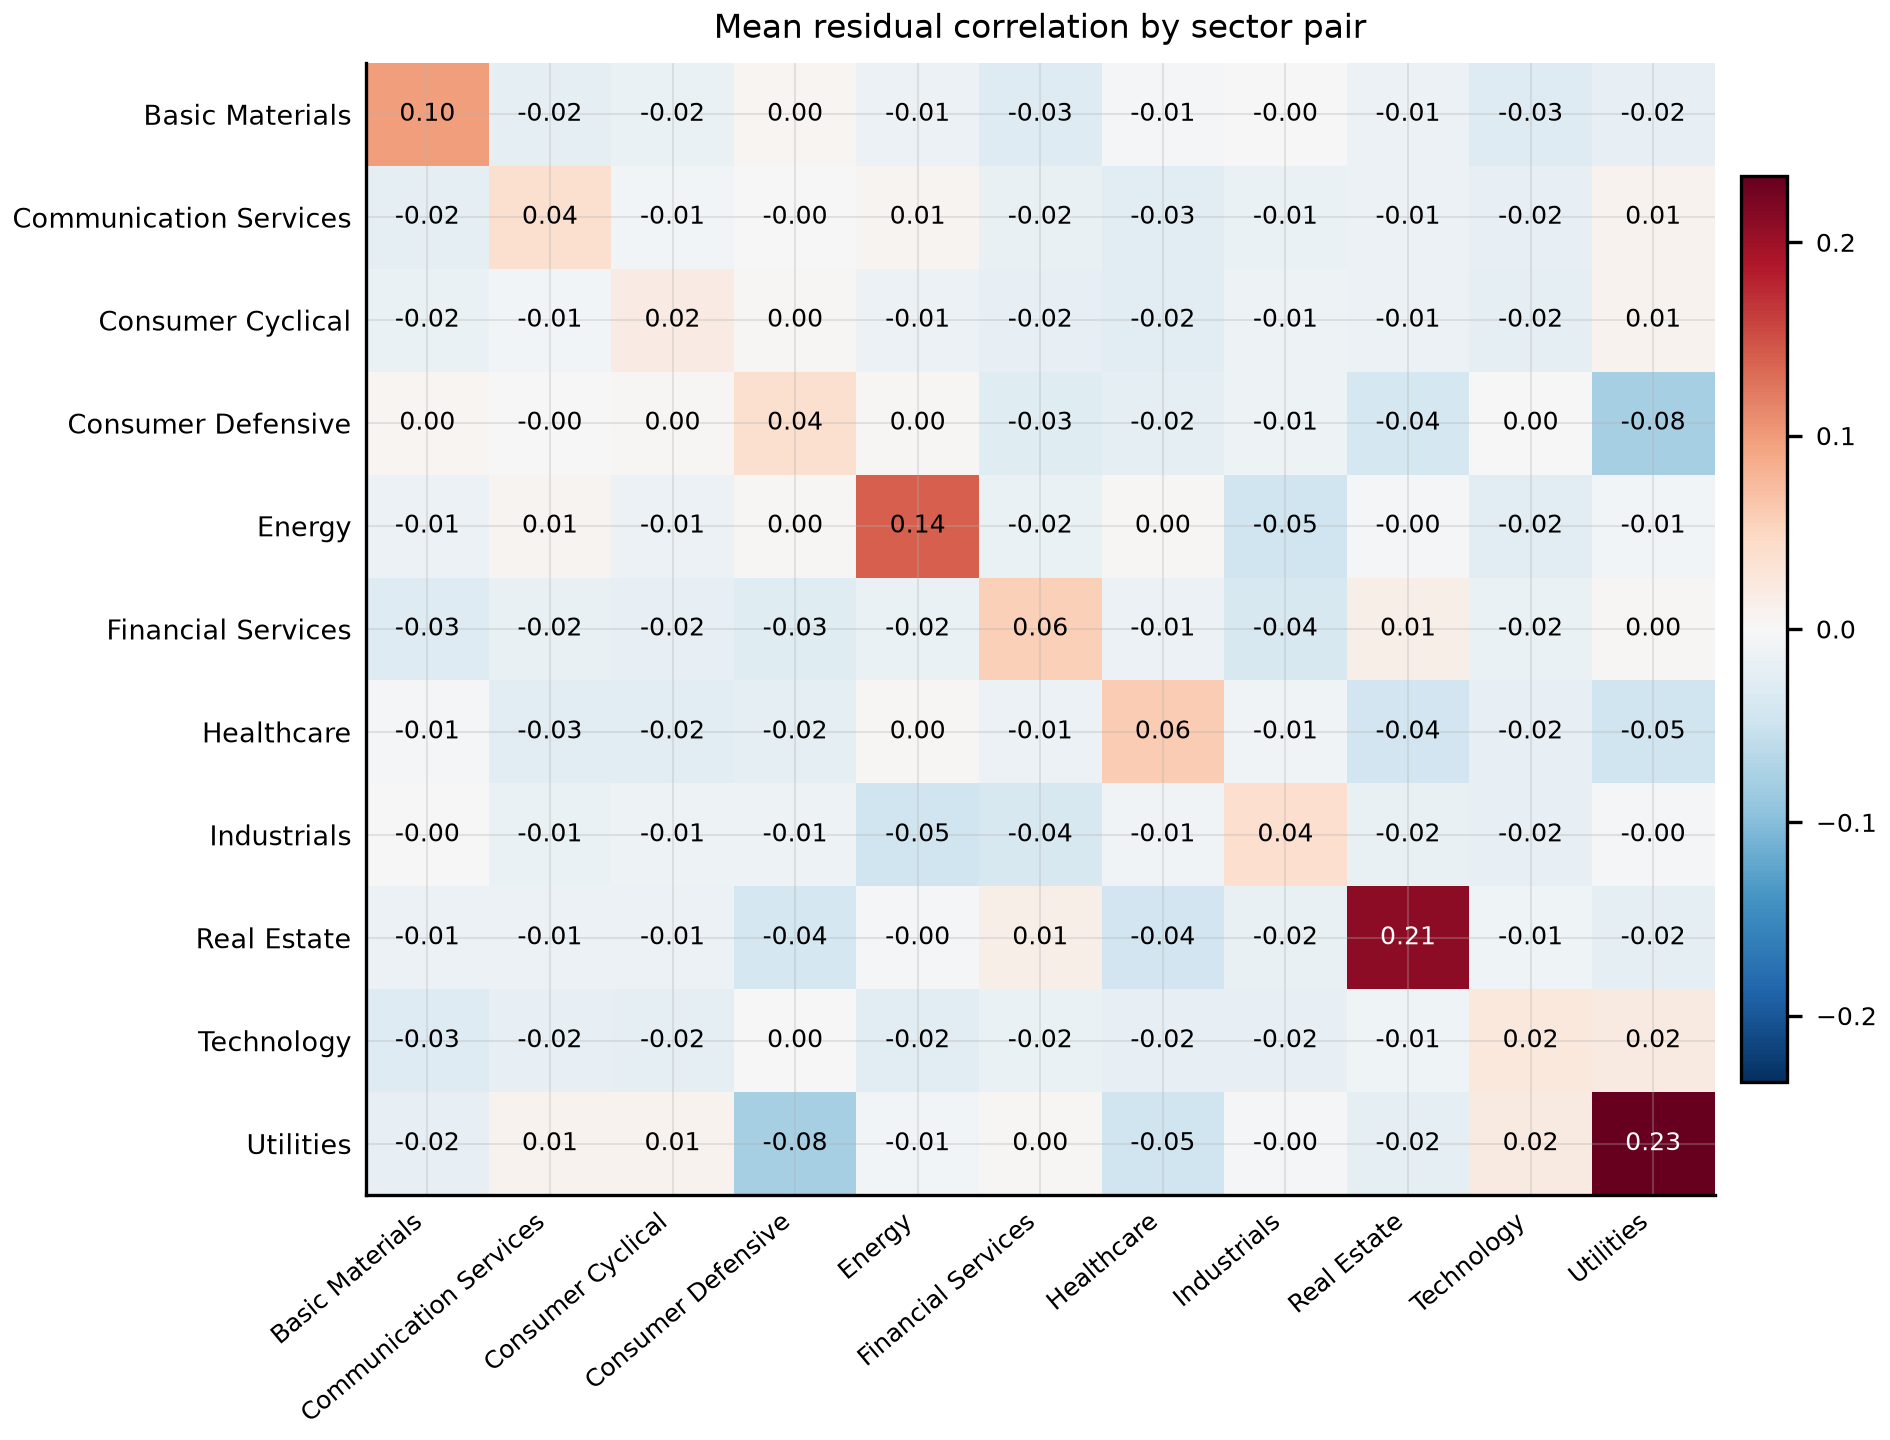

**figA15_res_timeseries.** Extension: sector structure of the PCA residual over time.

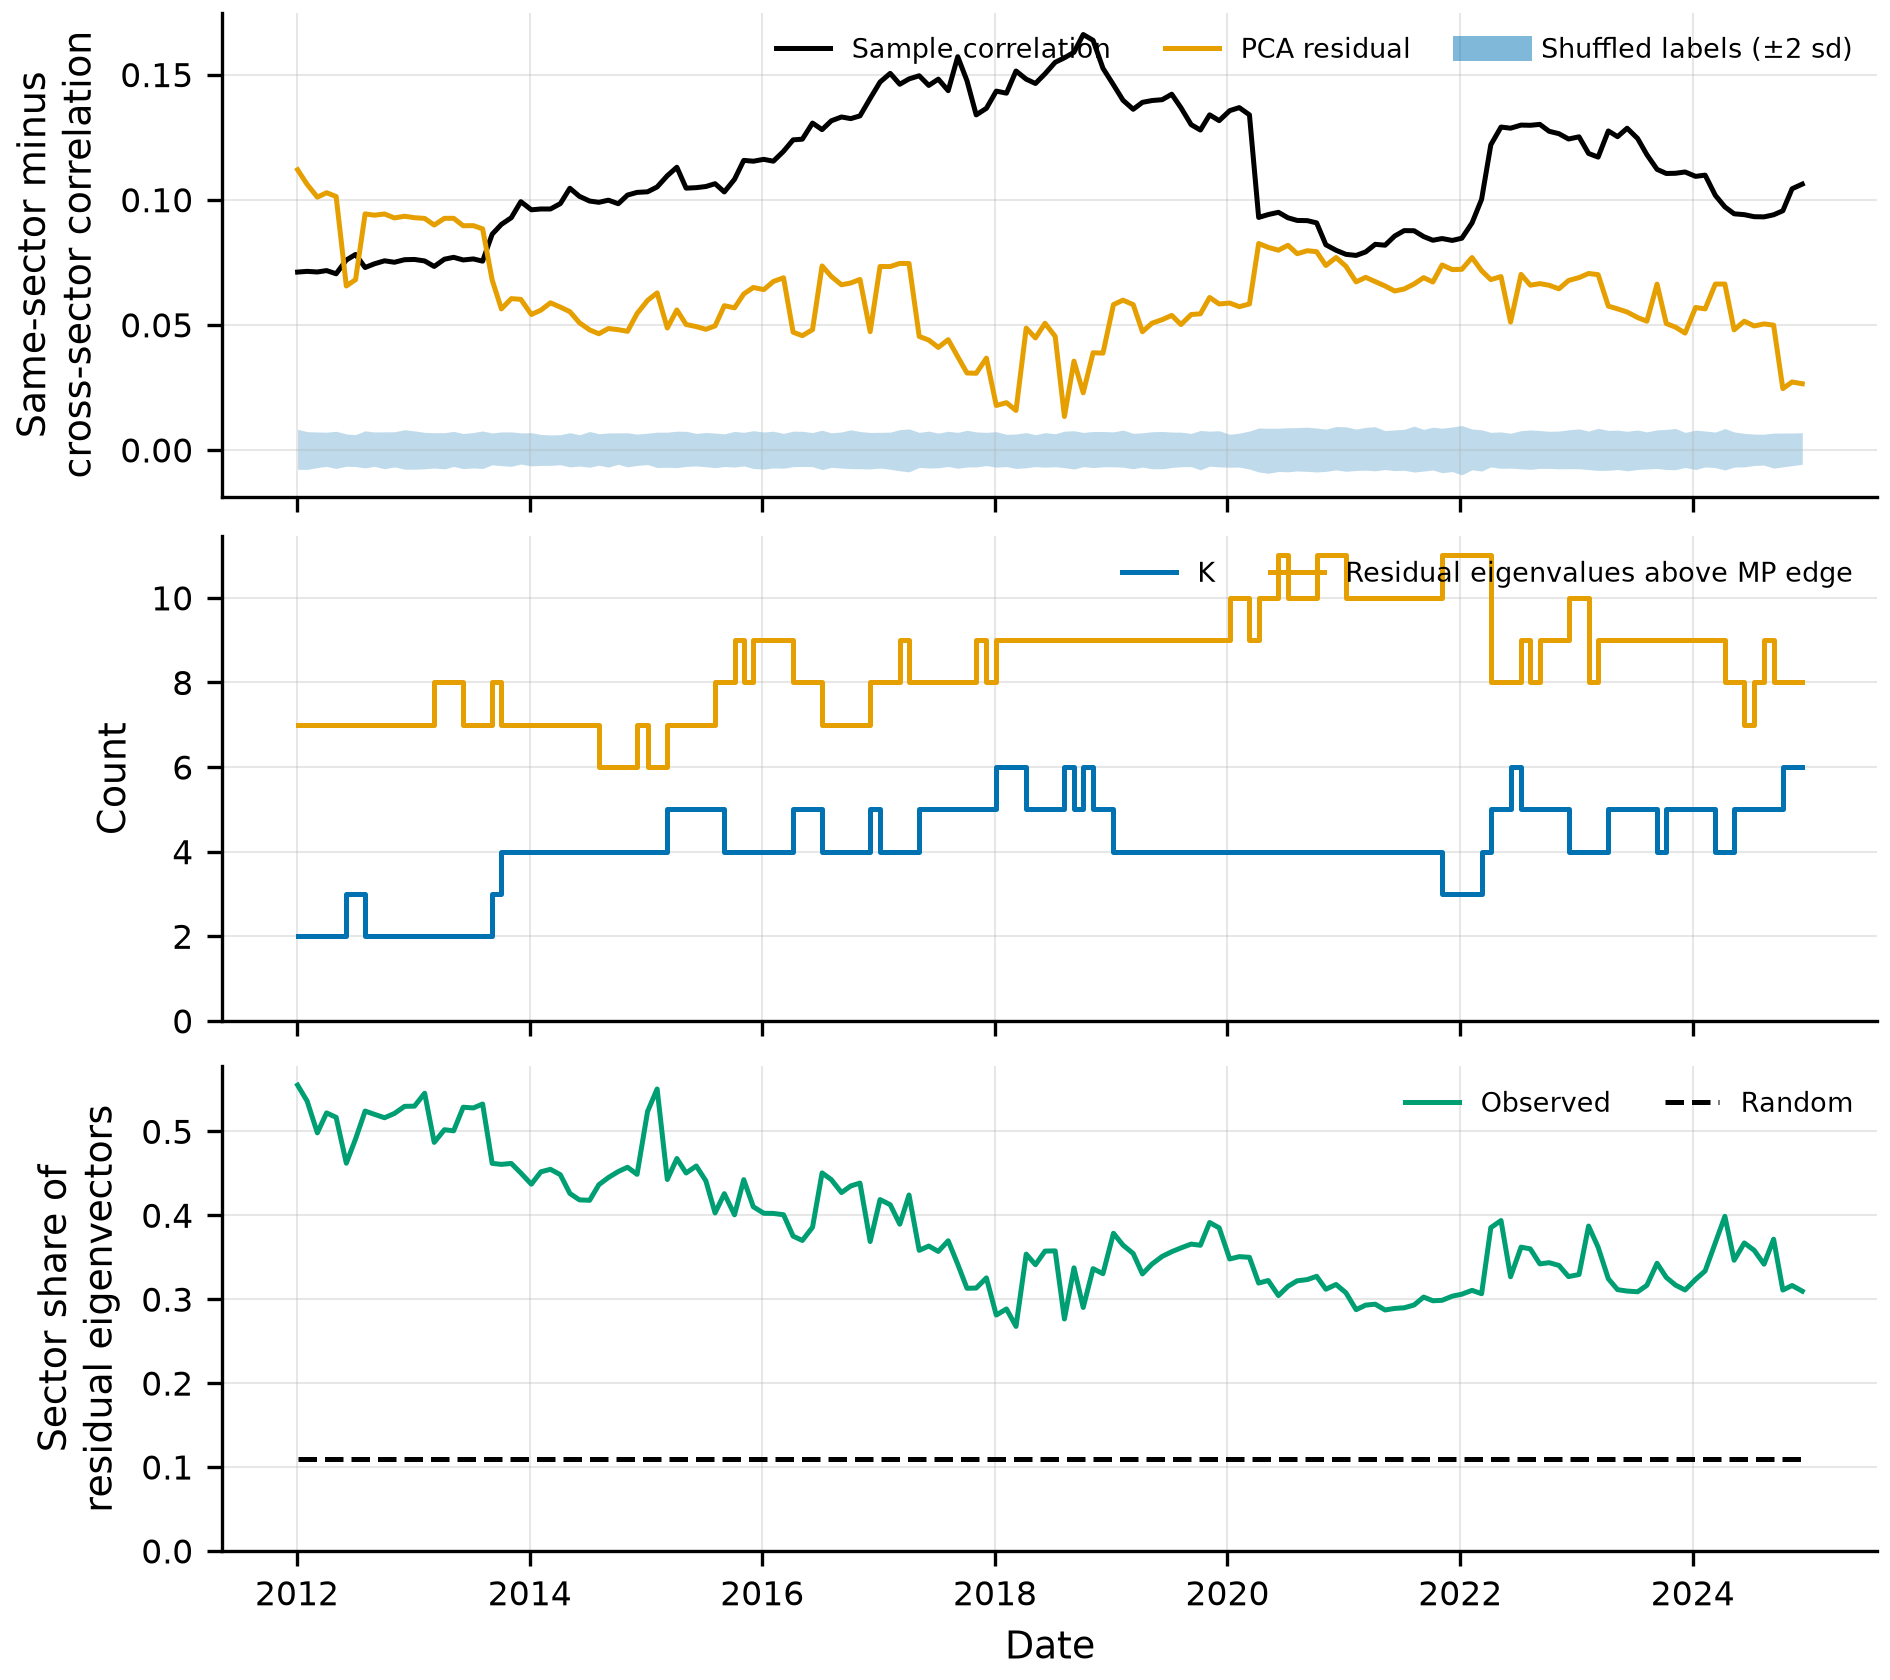

**tabA15_residual_blocks.** Extension: mean residual correlation by sector pair.

| sector | Basic Materials | Communication Services | Consumer Cyclical | Consumer Defensive | Energy | Financial Services | Healthcare | Industrials | Real Estate | Technology | Utilities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Basic Materials | 0.098 | -0.021 | -0.016 | 0.004 | -0.015 | -0.030 | -0.005 | -0.001 | -0.013 | -0.030 | -0.018 |
| Communication Services | -0.021 | 0.038 | -0.006 | -0.002 | 0.006 | -0.018 | -0.026 | -0.015 | -0.013 | -0.019 | 0.009 |
| Consumer Cyclical | -0.016 | -0.006 | 0.019 | 0.003 | -0.014 | -0.020 | -0.024 | -0.013 | -0.013 | -0.020 | 0.008 |
| Consumer Defensive | 0.004 | -0.002 | 0.003 | 0.037 | 0.003 | -0.029 | -0.023 | -0.011 | -0.042 | 9.2e-04 | -0.079 |
| Energy | -0.015 | 0.006 | -0.014 | 0.003 | 0.141 | -0.016 | 0.002 | -0.047 | -0.004 | -0.025 | -0.006 |
| Financial Services | -0.030 | -0.018 | -0.020 | -0.029 | -0.016 | 0.057 | -0.014 | -0.037 | 0.014 | -0.016 | 0.002 |
| Healthcare | -0.005 | -0.026 | -0.024 | -0.023 | 0.002 | -0.014 | 0.060 | -0.008 | -0.045 | -0.019 | -0.047 |
| Industrials | -0.001 | -0.015 | -0.013 | -0.011 | -0.047 | -0.037 | -0.008 | 0.040 | -0.018 | -0.018 | -0.005 |
| Real Estate | -0.013 | -0.013 | -0.013 | -0.042 | -0.004 | 0.014 | -0.045 | -0.018 | 0.210 | -0.011 | -0.021 |
| Technology | -0.030 | -0.019 | -0.020 | 9.2e-04 | -0.025 | -0.016 | -0.019 | -0.018 | -0.011 | 0.025 | 0.021 |
| Utilities | -0.018 | 0.009 | 0.008 | -0.079 | -0.006 | 0.002 | -0.047 | -0.005 | -0.021 | 0.021 | 0.234 |


**tabA16_residual_links.** Extension: window diagnostics against relative volatility (descriptive).

| diagnostic | target | spearman_rho | p_value | n |
| --- | --- | --- | --- | --- |
| raw_gap | logvol_GMV-LW | 0.292 | 2.3e-04 | 155.000 |
| raw_gap | logvol_GMV-RMT | -0.185 | 0.021 | 155.000 |
| raw_gap | logvol_GMV-PCA | -0.061 | 0.453 | 155.000 |
| resid_gap | logvol_GMV-LW | -0.238 | 0.003 | 155.000 |
| resid_gap | logvol_GMV-RMT | 0.165 | 0.040 | 155.000 |
| resid_gap | logvol_GMV-PCA | -0.070 | 0.387 | 155.000 |
| perm_z | logvol_GMV-LW | -0.121 | 0.132 | 155.000 |
| perm_z | logvol_GMV-RMT | 0.115 | 0.154 | 155.000 |
| perm_z | logvol_GMV-PCA | -0.045 | 0.576 | 155.000 |
| k_factors | logvol_GMV-LW | 0.258 | 0.001 | 155.000 |
| k_factors | logvol_GMV-RMT | -0.176 | 0.029 | 155.000 |
| k_factors | logvol_GMV-PCA | -0.049 | 0.547 | 155.000 |
| resid_n_signal | logvol_GMV-LW | -0.140 | 0.082 | 155.000 |
| resid_n_signal | logvol_GMV-RMT | 0.061 | 0.453 | 155.000 |
| resid_n_signal | logvol_GMV-PCA | -0.236 | 0.003 | 155.000 |


**tabA17_sectorblock_metrics.** Extension: PCA plus sector-block strategy, net of costs.

| strategy | ann_vol | ann_return | sharpe | max_drawdown | annual_turnover | mean_pred_vol | realized_over_pred |
| --- | --- | --- | --- | --- | --- | --- | --- |
| GMV-SAMPLE | 0.130 | 0.093 | 0.744 | -0.333 | 2.397 | 0.110 | 1.187 |
| GMV-LW | 0.130 | 0.094 | 0.758 | -0.335 | 2.262 | 0.109 | 1.185 |
| GMV-RMT | 0.136 | 0.084 | 0.663 | -0.362 | 2.195 | 0.111 | 1.226 |
| GMV-PCA | 0.135 | 0.092 | 0.721 | -0.343 | 2.175 | 0.102 | 1.319 |
| GMV-PCA-SECTOR | 0.131 | 0.094 | 0.753 | -0.332 | 2.233 | 0.107 | 1.233 |


... (2 outputs left out)

**tabA19_sectorblock_control.** Extension: positive and negative control, paired ratio against PCA.

| design | T | method | mean_log_ratio | ci_low | ci_high | n |
| --- | --- | --- | --- | --- | --- | --- |
| no sector factors | 252.000 | GMV-PCA-SECTOR | 0.004 | 0.003 | 0.005 | 100.000 |
| no sector factors | 252.000 | GMV-PCA-SECTOR-NOISY | 0.003 | 0.002 | 0.005 | 100.000 |
| no sector factors | 504.000 | GMV-PCA-SECTOR | 0.001 | 5.1e-04 | 0.002 | 100.000 |
| no sector factors | 504.000 | GMV-PCA-SECTOR-NOISY | 0.001 | 7.5e-04 | 0.002 | 100.000 |
| weak sector factors | 252.000 | GMV-PCA-SECTOR | -0.005 | -0.006 | -0.003 | 100.000 |
| weak sector factors | 252.000 | GMV-PCA-SECTOR-NOISY | -0.002 | -0.004 | -6.9e-04 | 100.000 |
| weak sector factors | 504.000 | GMV-PCA-SECTOR | -0.002 | -0.003 | -0.002 | 100.000 |
| weak sector factors | 504.000 | GMV-PCA-SECTOR-NOISY | -4.2e-04 | -0.002 | 7.0e-04 | 100.000 |


**tabA31_sectorblock_placebo.** Extension: random-label placebo draws of the sector-block strategy.

| draw | vol | log_var_vs_pca | log_var_vs_sample |
| --- | --- | --- | --- |
| 0.000 | 0.134 | -0.011 | 0.054 |
| 1.000 | 0.134 | -0.006 | 0.059 |
| 2.000 | 0.134 | -0.005 | 0.061 |
| 3.000 | 0.134 | -0.006 | 0.059 |
| 4.000 | 0.134 | -0.005 | 0.061 |
| 5.000 | 0.134 | -0.010 | 0.056 |
| 6.000 | 0.134 | -0.006 | 0.060 |
| 7.000 | 0.134 | -0.006 | 0.059 |
| 8.000 | 0.134 | -0.010 | 0.055 |
| 9.000 | 0.134 | -0.005 | 0.061 |
| 10.000 | 0.133 | -0.028 | 0.037 |
| 11.000 | 0.134 | -0.004 | 0.061 |
| 12.000 | 0.134 | -0.003 | 0.063 |
| 13.000 | 0.134 | -0.012 | 0.053 |
| 14.000 | 0.134 | -0.009 | 0.057 |
| 15.000 | 0.134 | -0.006 | 0.060 |
| 16.000 | 0.134 | -0.016 | 0.050 |
| 17.000 | 0.134 | -0.003 | 0.062 |
| 18.000 | 0.134 | -0.015 | 0.051 |
| 19.000 | 0.134 | -0.007 | 0.059 |


In [23]:
show_figure("res_blocks")
show_figure("res_timeseries")
show_table("residual_blocks")
show_table("residual_links")
show_table("sectorblock_metrics")
show_table("sectorblock_tests")
show_table("sectorblock_control")
show_table("sectorblock_placebo")

In [24]:
show_table("forecastloss")

**tabA20_forecastloss.** Extension: covariance forecast loss on random portfolios (QLIKE).

| family | estimator | n_dates | mean_qlike | mean_log_bias | diff_qlike | se | ci_low | ci_high | p_value | p_holm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| equal weight | Ledoit-Wolf | 155 | 0.680 | 0.485 | 0.008 | 0.011 | -0.014 | 0.030 | 0.465 | 1.000 |
| equal weight | NLS | 155 | 0.677 | 0.500 | 0.005 | 0.006 | -0.006 | 0.017 | 0.371 | 1.000 |
| equal weight | PCA | 155 | 0.668 | 0.533 | -0.004 | 0.004 | -0.013 | 0.004 | 0.344 | 1.000 |
| equal weight | PCA-SECTOR | 155 | 0.666 | 0.541 | -0.006 | 0.007 | -0.019 | 0.008 | 0.388 | 1.000 |
| equal weight | RMT | 155 | 0.670 | 0.520 | -0.002 | 0.001 | -0.004 | 0.001 | 0.275 | 1.000 |
| equal weight | Sample | 155 | 0.672 | 0.519 | 0.000 |  |  |  |  |  |
| Dirichlet(1) | Ledoit-Wolf | 155 | 0.662 | 0.471 | 0.008 | 0.011 | -0.013 | 0.028 | 0.473 | 1.000 |
| Dirichlet(1) | NLS | 155 | 0.660 | 0.486 | 0.005 | 0.006 | -0.006 | 0.016 | 0.375 | 1.000 |
| Dirichlet(1) | PCA | 155 | 0.651 | 0.518 | -0.004 | 0.004 | -0.012 | 0.004 | 0.345 | 1.000 |
| Dirichlet(1) | PCA-SECTOR | 155 | 0.649 | 0.526 | -0.006 | 0.007 | -0.019 | 0.007 | 0.389 | 1.000 |
| Dirichlet(1) | RMT | 155 | 0.653 | 0.505 | -0.001 | 0.001 | -0.004 | 0.001 | 0.282 | 1.000 |
| Dirichlet(1) | Sample | 155 | 0.655 | 0.505 | 0.000 |  |  |  |  |  |
| Dirichlet(0.1) | Ledoit-Wolf | 155 | 0.579 | 0.404 | 0.005 | 0.008 | -0.010 | 0.020 | 0.525 | 1.000 |
| Dirichlet(0.1) | NLS | 155 | 0.577 | 0.417 | 0.003 | 0.004 | -0.004 | 0.010 | 0.426 | 1.000 |
| Dirichlet(0.1) | PCA | 155 | 0.571 | 0.440 | -0.003 | 0.003 | -0.009 | 0.003 | 0.344 | 1.000 |
| Dirichlet(0.1) | PCA-SECTOR | 155 | 0.569 | 0.446 | -0.005 | 0.005 | -0.015 | 0.006 | 0.381 | 1.000 |
| Dirichlet(0.1) | RMT | 155 | 0.572 | 0.431 | -0.001 | 9.9e-04 | -0.003 | 5.3e-04 | 0.153 | 0.766 |
| Dirichlet(0.1) | Sample | 155 | 0.574 | 0.430 | 0.000 |  |  |  |  |  |


## 8. Summary and limitations

The cell below lists the net out-of-sample results of the core strategies, sorted by Sharpe ratio, straight from the saved table. The tables above are the authoritative record; this section only states what they support.

In [25]:
main = pd.read_csv(TABLES / "main_metrics.csv")
net_main = main[main["basis"] == "net"].set_index("strategy")
view = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "annual_turnover"]
display(net_main[view].sort_values("sharpe", ascending=False).round(3))

,ann_return,ann_vol,sharpe,max_drawdown,annual_turnover
strategy,,,,,
EW,0.170,0.174,0.993,-0.376,0.869
HRP-RMT,0.138,0.150,0.941,-0.359,2.535
HRP,0.136,0.148,0.934,-0.356,2.737
MV-SAMPLE,0.177,0.199,0.919,-0.380,5.812
MV-RMT,0.174,0.202,0.898,-0.383,6.029
GMV-LW,0.094,0.130,0.758,-0.335,2.262
GMV-SAMPLE,0.093,0.130,0.744,-0.333,2.397
GMV-PCA,0.092,0.135,0.721,-0.343,2.175
GMV-RMT,0.084,0.136,0.663,-0.362,2.195


**What the evidence supports** (read from the tables and figures above; see them for effect sizes and p-values):

- *Covariance estimation.* None of the denoised or shrunk covariance estimators (Ledoit-Wolf, RMT, PCA factor, nonlinear shrinkage, PCA with sector blocks) lowers the realized volatility of the long-only GMV portfolio below that of the plain sample covariance by a detectable margin; RMT and PCA come out slightly worse. Restoring sector structure in the PCA residual recovers most of the PCA loss but does not beat the sample covariance.
- *Forecast quality versus use.* As forecasters of the variance of random portfolios, RMT and PCA are not detectably worse than the sample covariance. The GMV loss therefore appears to come from how the optimizer uses the estimate, not from a worse covariance as such. The mechanism was not tested directly.
- *The optimizer matters.* For equal risk contribution portfolios the choice of covariance estimator hardly matters; for minimum variance it does. Shrinking the weights toward 1/N or adding a ridge penalty brings realized volatility closer to the predicted level at the price of higher volatility, with no significant Sharpe gain.
- *Machine learning.* The ML signals have an out-of-sample rank IC that is small and not significant, so the gate is failed; the forced portfolios are more concentrated, trade more and are more volatile than the references. This is a null result and is reported as such.

**Limitations.**

- The supplied file prices only part of the listed symbols and holds current index members only: the universe is a selection of those with prices, and survivorship bias remains.
- One historical path; the block bootstrap quantifies sampling noise within it, not other histories. Several differences are within the detectable-effect bounds reported in the inference tables.
- Costs are proportional; shorting variants carry no borrow cost; there is no market-impact model.
- The ML evaluation starts later than the core backtest because the models need training history, so its comparison uses the common later window.
- Parameters were fixed a priori. Sensitivity tables are descriptive and were not used to pick a configuration.